In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os

sys.path.append(os.path.abspath("src/data_analysis/utils/"))
import utils.ros_to_df

In [2]:
import argparse
import math
import re

from collections import defaultdict
from dataclasses import dataclass, field
from datetime import datetime
from math import pi
from pathlib import Path
from typing import Any, Generator, List, Optional

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import PyKDL
import rclpy
import rosbag2_py

# import ros2_numpy as rnp
import rosbag2_py._storage as storage
import scipy
import tf2_geometry_msgs
import tf2_ros

from utils.analysis_utils import (
    df_to_pose_stamped,
    do_transform_twist,
    filter_dataframe,
    filter_twist_data,
    transform_pose_dataframe,
    transform_to_kdl,
    transform_twist_dataframe,
    quaternion_to_euler
)
from utils.bag_utils import get_metadata, get_reader
from builtin_interfaces.msg import Time
from control_msgs.msg import DynamicJointState
from geometry_msgs.msg import Pose, PoseStamped, TwistStamped, Vector3, Vector3Stamped
from mpl_toolkits.mplot3d import Axes3D
from numpy.typing import NDArray
from pandas import DataFrame, Series
from rclpy.serialization import deserialize_message
from utils.ros_to_df import ros_message_to_df
from rosidl_runtime_py.utilities import get_message
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.spatial.transform import Rotation as R
from sensor_msgs.msg import Imu
from std_msgs.msg import Header, String
from tf2_msgs.msg import TFMessage
from tf2_ros import TransformStamped
from utils.viz_utils import (
    MultiViconPoseTwistAnimator,
    publish_df_pose_stamped,
    publish_pose_stamped,
    publish_pose_stamped_list,
    send_static_transform,
    send_transform,
)

from motor_msgs.msg import MotorCurrents
import matplotlib.pyplot as plt
import multiprocessing
import time
import matplotlib
# matplotlib.use("Agg") 
# %matplotlib inline

from utils.deriv_smoothing import savgol_derivative, quaternion_derivative_savgol

plt.rcParams.update({
    "font.size": 14,  # Change all fonts to size 14
    "axes.titlesize": 16,  # Title font size
    "axes.labelsize": 14,  # Axis label font size
    "xtick.labelsize": 12,  # X-axis tick font size
    "ytick.labelsize": 12,  # Y-axis tick font size
    "legend.fontsize": 12   # Legend font size
})

In [ ]:
def save_all_figures(bag_name, root_folder="figures"):
    """
    Saves all open matplotlib figures using their titles or suptitles as
    filenames inside a subdirectory named after bag_name. Figures remain open
    after saving.

    Parameters:
        bag_name (str): The bag name to create a subdirectory under `figures/`.
        root_folder (str): The root directory where all figures are stored.
    """
    # Ensure the root and subdirectory exist
    save_dir = os.path.join(root_folder, bag_name)
    os.makedirs(save_dir, exist_ok=True)
    # **Disable interactive mode**
    # plt.ioff()

    for i, fig_num in enumerate(plt.get_fignums()):
        fig = plt.figure(fig_num)  # Activate figure
        ax = fig.axes[0] if fig.axes else None

        # **Try to get the suptitle (for multi-axes figures)**
        title = fig._suptitle.get_text() if fig._suptitle else None

        # If no suptitle, try to get the first subplot title
        if not title and ax:
            title = ax.get_title()

        # Fallback if title is empty
        if not title:
            title = f"figure_{i + 1}"

        # Clean up title to be a valid filename
        filename = re.sub(r"[^\w\-_]", "_", title).strip("_")  # Replace invalid characters
        filename = filename[:100]  # Limit filename length

        filepath = os.path.join(save_dir, f"{filename}.png")
        fig.savefig(filepath, dpi=300, bbox_inches="tight")
        print(f"Saved: {filepath}")
    # plt.show()


def save_animation(animator, bag_name, root_folder="figures", filename_suffix="animation", fps=30):
    """
    Saves the animation from MultiViconPoseAnimator to an MP4 file.

    Parameters:
        animator: The MultiViconPoseAnimator instance that has been run.
        bag_name (str): The bag name to create a subdirectory under `figures/`.
        root_folder (str): The root directory where all figures are stored.
        filename_suffix (str): Custom suffix for filename (default: 'animation').
        fps (int): Frames per second for the saved animation.
    """
    from matplotlib.animation import FFMpegWriter

    # Ensure the output directory exists
    save_dir = os.path.join(root_folder, bag_name)
    os.makedirs(save_dir, exist_ok=True)

    # Construct the filename
    filename = f"{bag_name}_{filename_suffix}.mp4"
    filepath = os.path.join(save_dir, filename)

    # Save animation
    writer = FFMpegWriter(fps=fps, metadata={"artist": "MultiViconPoseAnimator"})
    animator.anim.save(filepath, writer=writer, dpi=300)

    print(f"Saved animation: {filepath}")

# Estimating Dynamic COF Using a Skid-Steer Robot 
This will be longitudinal driving only using the slip-slope relationship. This is done by comparing the force experienced by the wheel to the actual amount of velocity slip experienced. For a given surface this relationship will be roughly linear. The steepness indicates that for an increase in slip so and so amount of more force is required to overcome the friction force.

# Load Data From Rosbag
We will read all messages from a MCAP rosbag and store in a dictionary of lists. The key values will be string representations of the topic name. The lists will be of ros2 message objects deserialized from the bag. Use my generic(ish) `ros_message_to_df` function to convert the messages of interest into pandas.DataFrames. Column names will be the recursively unflattened data structure of the message. **Note**, this is somewhat fragile and will likely need to be tweaked to work for messages other than the ones currently tested which are:

* DynamicJointState
* PoseStamped
* Twist Stamped
* Imu
* MotorCurrents

The `sec` and `nanosec` fields of stamped messages will be preserved in the DataFrame as columns. The indxed of the DataFrame will be a floating point timestamp made by combining the sec and nanosec time values. 

In [4]:
# TODO Put this in asome other kind of structure.
# bag_file = (
# "logging/2025_2_16_rosbags/2025_2_16__17_14_4760RPM_vinyl_linear_skid.bag"

# UNSORTED

# 'logging/2025_2_3_rosbags/2025_2_3__16_52_49sit_still_1min.bag'
# 'logging/2025_2_3_rosbags/2025_2_3__16_56_14imu_still_17min.bag'
# 'logging/2025_2_3_rosbags/2025_2_3__17_25_29drive_stop_1.bag'
# 'logging/2025_2_3_rosbags/2025_2_3__17_29_08drive_back_9prm_1.bag'
# 'logging/2025_2_3_rosbags/2025_2_3__17_42_08spin_40s_5rpm_1.bag'
# 'logging/2025_2_3_rosbags/2025_2_3__18_00_30sin_drive_0to6RPM.bag'

# 'logging/2025_2_5_rosbags/2025_2_5__17_52_080.2m/sec_concrete.bag'
# 'logging/2025_2_5_rosbags/2025_2_5__17_53_020.4m'
# 'logging/2025_2_5_rosbags/2025_2_5__17_53_480.6m'
# 'logging/2025_2_5_rosbags/2025_2_5__17_54_500.6m'
# 'logging/2025_2_5_rosbags/2025_2_5__17_55_430.8m'
# 'logging/2025_2_5_rosbags/2025_2_5__17_56_200.8m'
# 'logging/2025_2_5_rosbags/2025_2_5__17_59_181m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_02_221.2m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_06_370.2m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_04_490.2m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_34_580.2m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_37_580.4m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_41_460.6m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_43_390.8m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_45_151m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_47_460.2m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_49_160.4m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_51_460.6m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_53_540.8m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_55_110.8m'
# 'logging/2025_2_5_rosbags/2025_2_5__18_57_530.8m'

# 'logging/2025_2_16_rosbags/2025_2_16__15_20_10RPM2.0_Vinyl.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__15_41_00RPM2.0_Vinyl_test.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__15_48_02RPM3.0_Vinyl.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__16_00_08RPM5.0_Vinyl.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__16_05_04RBM5.0_TEST.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__16_45_585RPM_vinyl_linear.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__17_14_4760RPM_vinyl_linear_skid.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__17_18_2110RPM_concrete_linear_skid.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__17_21_0660RPM_concrete_linear_skid.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__17_25_2230RPMback_40RPMfront.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__17_27_4230RPMback_50RPMfront.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__17_32_4930RPMback_60RPMfront.bag'
# 'logging/2025_2_16_rosbags/2025_2_16__17_35_4130RPMback_60RPMfront_v2.bag'

# 'logging/2025_2_20_rosbags/2025_02_20__11_54_50_drive_straight_AngularV2_Distance2_concrete.bag'
# 'logging/2025_2_20_rosbags/2025_02_20__11_55_32_drive_straight_AngularV2_Distance2_concrete..bag'
# 'logging/2025_2_20_rosbags/2025_02_20__13_14_56_drive_straight_AngularV2_Distance2_concrete..bag'
# 'logging/2025_2_20_rosbags/2025_02_20__15_40_49_arc_drive_Arclength10_ArcVel5.bag'
# 'logging/2025_2_20_rosbags/2025_02_20__15_45_30_arc_drive_Arclength10_ArcVel5.bag'
# 'logging/2025_2_20_rosbags/2025_02_20__15_51_58_drive_straight_AngVel3_Distance5_conR&nylL.bag'


# 'logging/2025_3_11_rosbags_correct/2025_3_11__15_25_25RPM60_Vinyl.bag'
# 'logging/2025_3_11_rosbags_correct/2025_3_11__15_27_48RPM20_Vinyl.bag'
# 'logging/2025_3_11_rosbags_correct/2025_3_11__15_30_37RPM20_left_con_right_vinyl.bag'
# 'logging/2025_3_11_rosbags_correct/2025_3_11__15_34_08RPM60_con.bag'
# 'logging/2025_3_11_rosbags_correct/2025_3_11__15_36_11RPM30_con.bag'
# 'logging/2025_3_11_rosbags_correct/2025_3_11__15_49_15RPM20_con.bag'
# 'logging/2025_3_11_rosbags_correct/2025_3_11__15_49_15RPM20_con.bag/2025_3_11__15_49_15RPM20_con.bag_0.mcap'

# GOOD - RAD
# 'logging/2025_3_11_rosbags_correct/2025_3_11__15_27_48RPM20_Vinyl.bag'

# GOOD - RPM


# BAD DATA? ###################################################
# 'logging/2025_2_20_rosbags/2025_02_20__15_54_37_drive_straight_AngVel-4_Distance10_conR&nylL.bag'

## Noisy/spikey reported encoder data?
# 'logging/2025_2_20_rosbags/2025_02_20__15_53_00_drive_straight_AngVel4_Distance10_conR&nylL.bag'

# )


# bag_files = [
#     'logging/2025_2_3_rosbags/2025_2_3__16_52_49sit_still_1min.bag',
#     'logging/2025_2_3_rosbags/2025_2_3__16_56_14imu_still_17min.bag',
#     'logging/2025_2_3_rosbags/2025_2_3__17_25_29drive_stop_1.bag',
#     'logging/2025_2_3_rosbags/2025_2_3__17_29_08drive_back_9prm_1.bag',
#     'logging/2025_2_3_rosbags/2025_2_3__17_42_08spin_40s_5rpm_1.bag',
#     'logging/2025_2_3_rosbags/2025_2_3__18_00_30sin_drive_0to6RPM.bag',

#     'logging/2025_2_5_rosbags/2025_2_5__17_52_080.2m/sec_concrete.bag',
#     'logging/2025_2_5_rosbags/2025_2_5__17_53_020.4m',
#     'logging/2025_2_5_rosbags/2025_2_5__17_53_480.6m',
#     'logging/2025_2_5_rosbags/2025_2_5__17_54_500.6m',
#     'logging/2025_2_5_rosbags/2025_2_5__17_55_430.8m',
#     'logging/2025_2_5_rosbags/2025_2_5__17_56_200.8m',
#     'logging/2025_2_5_rosbags/2025_2_5__17_59_181m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_02_221.2m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_06_370.2m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_04_490.2m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_34_580.2m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_37_580.4m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_41_460.6m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_43_390.8m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_45_151m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_47_460.2m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_49_160.4m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_51_460.6m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_53_540.8m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_55_110.8m',
#     'logging/2025_2_5_rosbags/2025_2_5__18_57_530.8m',

#     'logging/2025_2_16_rosbags/2025_2_16__15_20_10RPM2.0_Vinyl.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__15_41_00RPM2.0_Vinyl_test.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__15_48_02RPM3.0_Vinyl.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__16_00_08RPM5.0_Vinyl.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__16_05_04RBM5.0_TEST.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__16_45_585RPM_vinyl_linear.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__17_14_4760RPM_vinyl_linear_skid.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__17_18_2110RPM_concrete_linear_skid.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__17_21_0660RPM_concrete_linear_skid.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__17_25_2230RPMback_40RPMfront.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__17_27_4230RPMback_50RPMfront.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__17_32_4930RPMback_60RPMfront.bag',
#     'logging/2025_2_16_rosbags/2025_2_16__17_35_4130RPMback_60RPMfront_v2.bag',

#     'logging/2025_2_20_rosbags/2025_02_20__11_54_50_drive_straight_AngularV2_Distance2_concrete.bag',
#     'logging/2025_2_20_rosbags/2025_02_20__11_55_32_drive_straight_AngularV2_Distance2_concrete..bag',
#     'logging/2025_2_20_rosbags/2025_02_20__13_14_56_drive_straight_AngularV2_Distance2_concrete..bag',
#     'logging/2025_2_20_rosbags/2025_02_20__15_40_49_arc_drive_Arclength10_ArcVel5.bag',
#     'logging/2025_2_20_rosbags/2025_02_20__15_45_30_arc_drive_Arclength10_ArcVel5.bag',
#     'logging/2025_2_20_rosbags/2025_02_20__15_51_58_drive_straight_AngVel3_Distance5_conR&nylL.bag',


#     'logging/2025_3_11_rosbags_correct/2025_3_11__15_25_25RPM60_Vinyl.bag'
#     'logging/2025_3_11_rosbags_correct/2025_3_11__15_27_48RPM20_Vinyl.bag'
#     'logging/2025_3_11_rosbags_correct/2025_3_11__15_30_37RPM20_left_con_right_vinyl.bag'
#     'logging/2025_3_11_rosbags_correct/2025_3_11__15_34_08RPM60_con.bag'
#     'logging/2025_3_11_rosbags_correct/2025_3_11__15_36_11RPM30_con.bag'
#     'logging/2025_3_11_rosbags_correct/2025_3_11__15_49_15RPM20_con.bag'
#     'logging/2025_3_11_rosbags_correct/2025_3_11__15_49_15RPM20_con.bag/2025_3_11__15_49_15RPM20_con.bag_0.mcap'

#     'logging/2025_3_11_rosbags_correct/2025_3_11__15_27_48RPM20_Vinyl.bag'

# ]

In [5]:
bag_file = (
    # "logging/2025_2_16_rosbags/2025_2_16__16_00_08RPM5.0_Vinyl.bag"
    # 'logging/2025_3_11_rosbags_correct/2025_3_11__15_36_11RPM30_con.bag'
    # 'logging/2025_3_11_rosbags_correct/2025_3_11__15_49_15RPM20_con.bag'
    # 'logging/2025_3_11_rosbags_correct/2025_3_11__15_34_08RPM60_con.bag'
    # 'logging/2025_3_11_rosbags_correct/2025_3_11__15_25_25RPM60_Vinyl.bag'
    # 'logging/2025_3_11_rosbags_correct/2025_3_11__15_27_48RPM20_Vinyl.bag'
    'logging/2025_3_11_rosbags_correct/2025_3_11__15_25_25RPM60_Vinyl.bag'
)


SURFACE_TYPE = None
if 'con' in bag_file.lower():
    SURFACE_TYPE = "Concrete"
elif 'vinyl' in bag_file.lower():
    SURFACE_TYPE = "Vinyl"
else:
    SURFACE_TYPE = "unknown"

print(SURFACE_TYPE)

# plt.ioff()
# plt.ion()

path_pref = "../../"
bag_file = path_pref + bag_file
# Use this for labeling plots and such later.
bag_name = bag_file.split("/")[-1]

#################################
# Manually set the bag_name
# bag_name = "Concrete"

# Get a list of topcis, their types and counts for them.
meta_data = get_metadata(input_bag=bag_file)
reader = get_reader(input_bag=bag_file)

# Create a dict of lists with keys matching the the topic names.
msgs = {k.topic_metadata.name: [] for k in meta_data.topics_with_message_count}

# User our rosbag2_py wrapper function to populate lists with corresponding messages.
for topic, msg, timestamp in reader:
    msgs[topic].append(msg)


# Check if rosbag was recorded in the RPMs (<March X) or in RAD/s (>Marchx)
bag_epoch_time = meta_data.starting_time.nanoseconds  # Unix epoch for bag
RAD_EPOCH = (
    datetime(year=2025, month=2, day=19).timestamp() * 1e9
)  # Unix epoch for when we started using RAD/s
# print(RAD_EPOCH)
ANG_VEL_UNIT = None
if (bag_epoch_time - RAD_EPOCH) > 0:
    ANG_VEL_UNIT = "RAD"
    print("Data recorded before switching to RAD/s! Setting ANG_VEL_UNIT='RAD'...")
else:
    ANG_VEL_UNIT = "RPM"
    print("Data recorded before switching to RAD/s! Setting ANG_VEL_UNIT='RPM'...")


# Maybe just RAD?
# ANG_VEL_UNIT = "RAD"

print(meta_data)





# For metadata on DataFrame.attrs
base_meta = {
    'bag_name': bag_name,
    'surface': str(SURFACE_TYPE)
    # 'bag_meta_data' : meta_data,
    
}


Vinyl
Data recorded before switching to RAD/s! Setting ANG_VEL_UNIT='RAD'...

Files:             2025_3_11__15_25_25RPM60_Vinyl.bag_0.mcap
Bag size:          11.4 MiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          47.896384077s
Start:             Mar 11 2025 19:25:25.893382849 (1741721125.893382849)
End:               Mar 11 2025 19:26:13.789766926 (1741721173.789766926)
Messages:          67976
Topic information: Topic: /diagnostics | Type: diagnostic_msgs/msg/DiagnosticArray | Count: 47 | Serialization Format: cdr
                   Topic: /dynamic_joint_states | Type: control_msgs/msg/DynamicJointState | Count: 1214 | Serialization Format: cdr
                   Topic: /events/write_split | Type: rosbag2_interfaces/msg/WriteSplitEvent | Count: 0 | Serialization Format: cdr
                   Topic: /joint_state_broadcaster/transition_event | Type: lifecycle_msgs/msg/TransitionEvent | Count: 0 | Serialization Format: cdr
                   Topic: /joint_states | 

## Converting ROS2 Message Objects to DataFrames and Plotting Raw Data
We can plot a data frame using `pd.DataFrame.plot` which by default plots all columns as time series against the index. Timestamps are Unix epoch but we can offset to start at t=0 for visualization.

In [6]:
plt.close("all")

In [ ]:
from utils.plot_utils import ExternalPlotter


# Create external plot manager
plt.figure()
external_plotter = ExternalPlotter()
external_plotter_2 = ExternalPlotter()

time.sleep(0.3)


QStandardPaths: XDG_RUNTIME_DIR not set, defaulting to '/tmp/runtime-rb'
glx: failed to create dri3 screen
failed to load driver: nouveau
glx: failed to create dri3 screen
failed to load driver: nouveau
QStandardPaths: XDG_RUNTIME_DIR not set, defaulting to '/tmp/runtime-rb'
glx: failed to create dri3 screen
failed to load driver: nouveau
glx: failed to create dri3 screen
failed to load driver: nouveau


<Figure size 640x480 with 0 Axes>

left_currents.columns=Index(['header.stamp.sec', 'header.stamp.nanosec', 'header._frame_id', 'front',
       'back'],
      dtype='object')
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Raw_Motor_encoder_count___2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Raw_Motor_position___2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Raw_Motor_current___2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Raw_Motor_velocity___2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/VICON_marker_TRUE_POSE__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/VICON_marker_TRUE_POSE__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/VICON_marker_TRUE_POSE__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Vicon_Marker_Linear_Vel__20

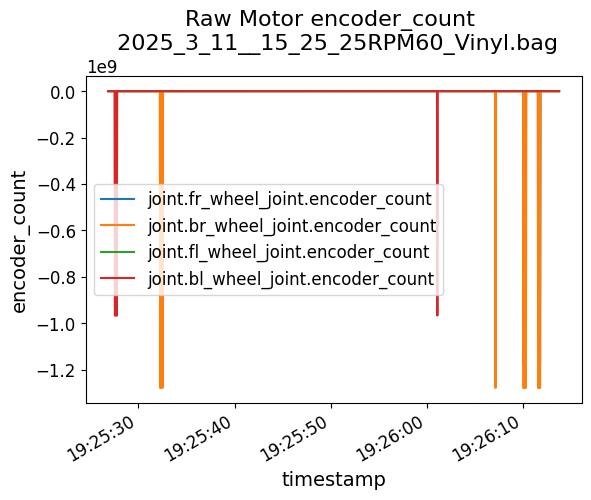

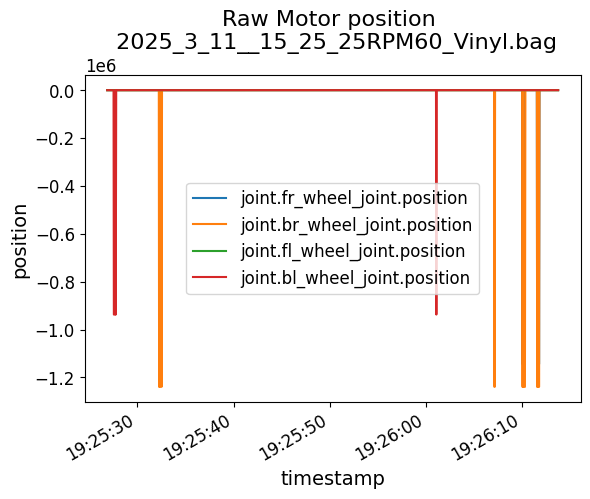

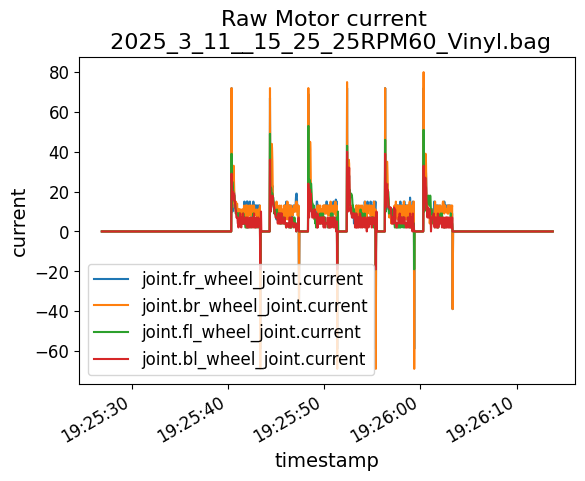

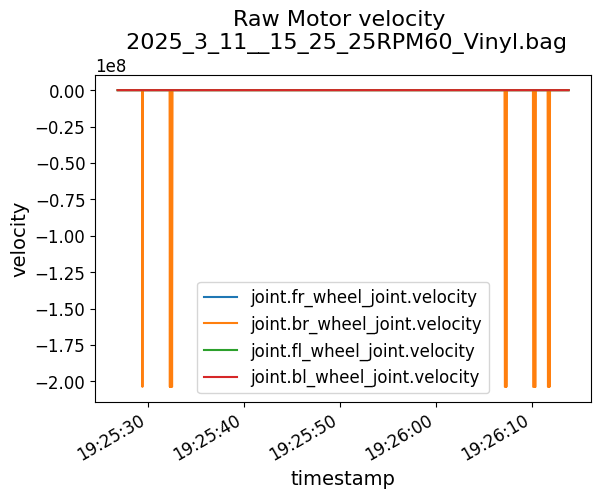

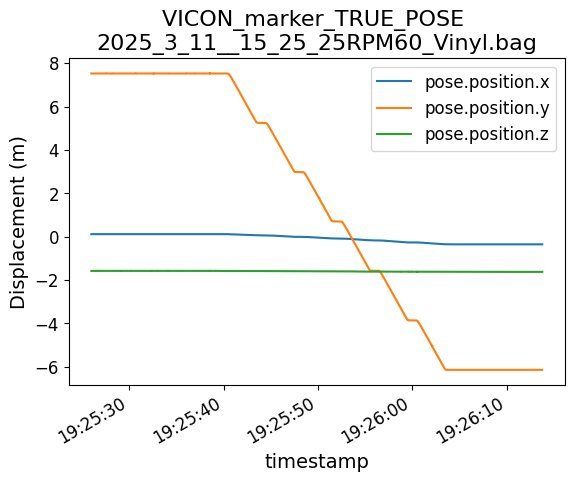

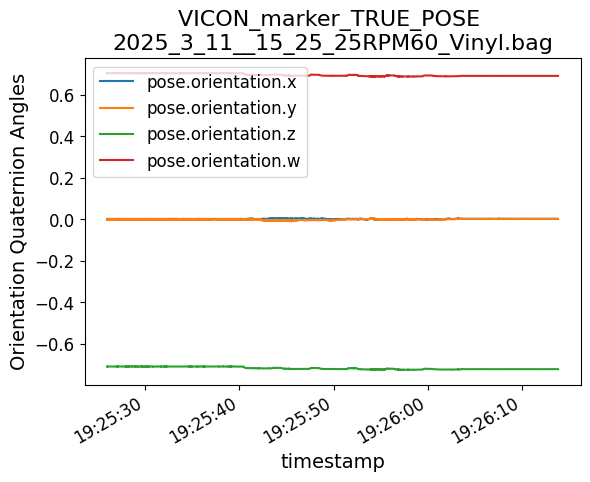

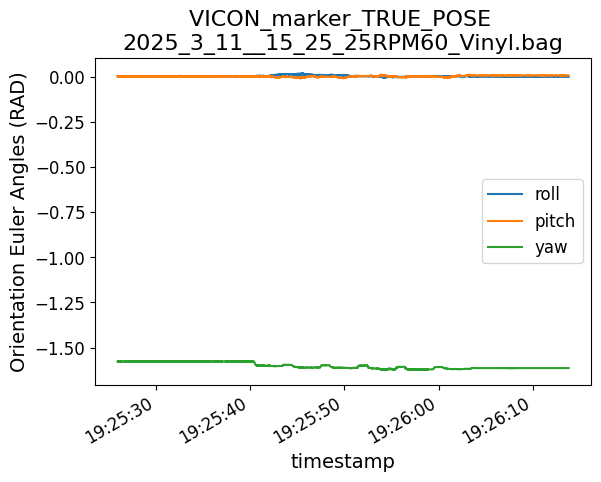

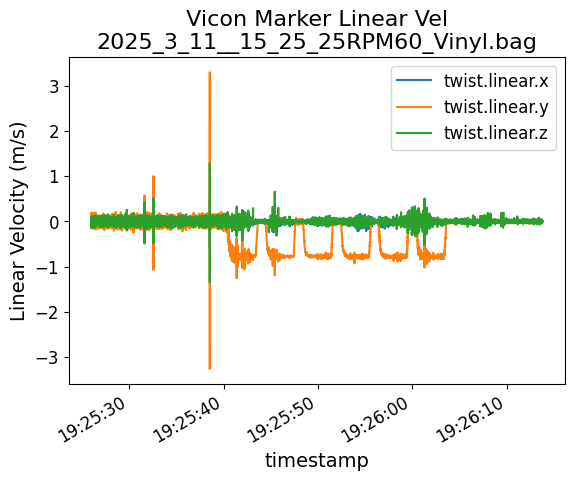

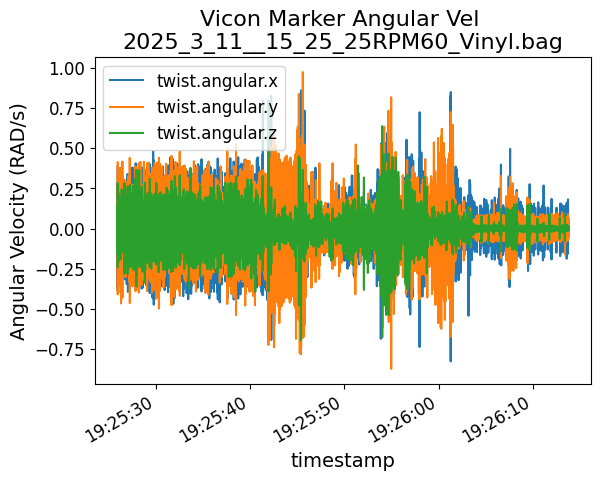

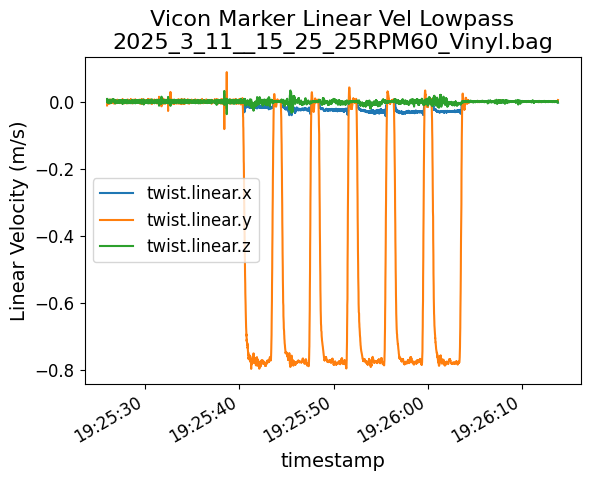

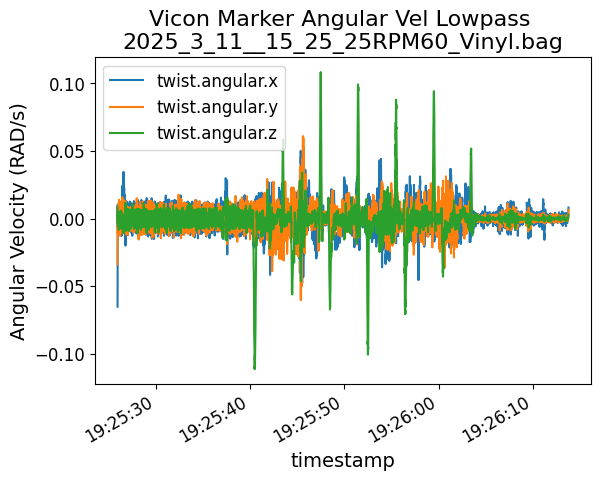

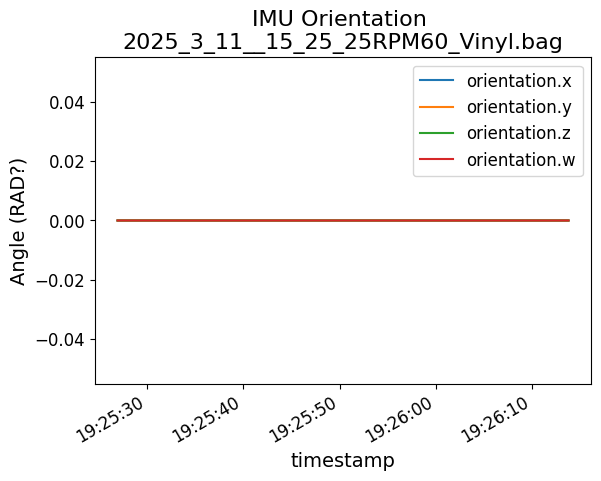

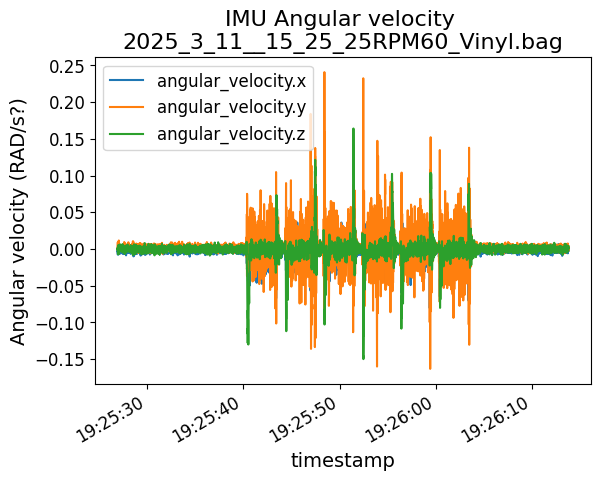

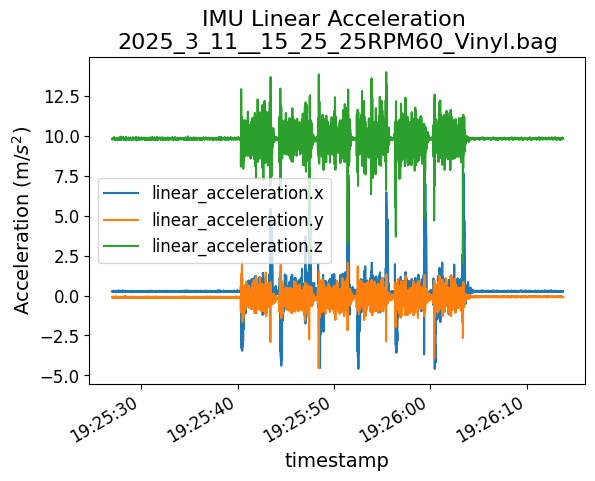

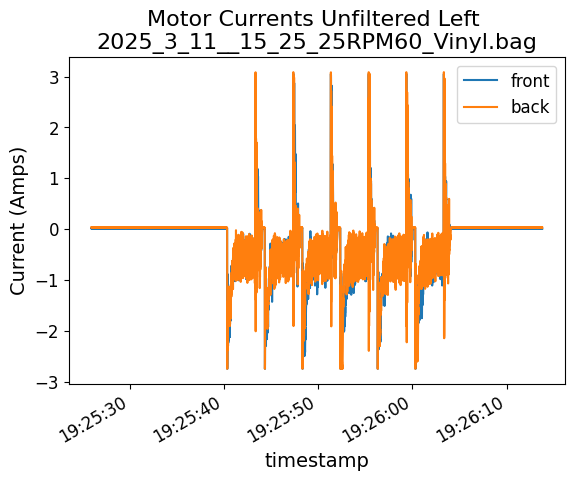

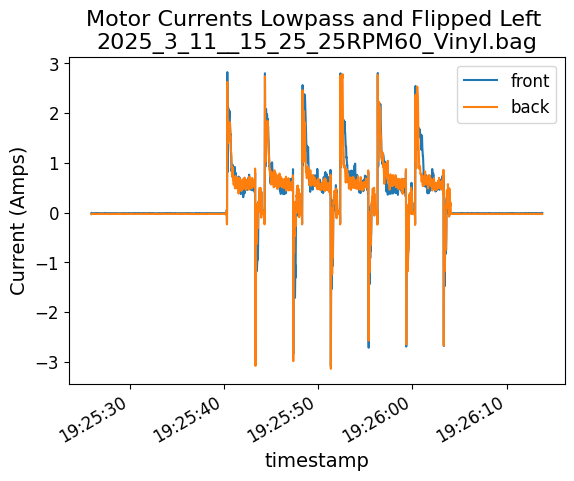

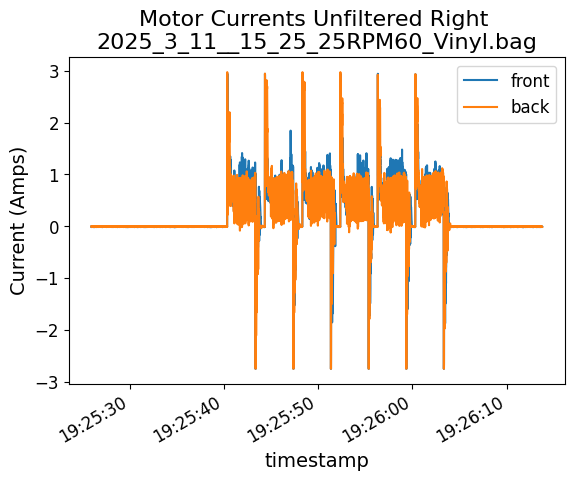

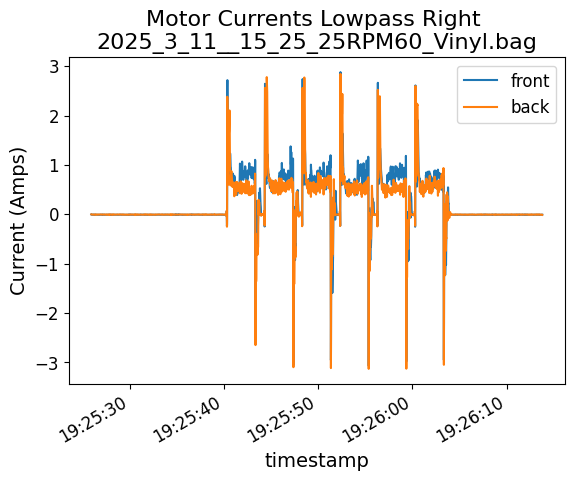

In [8]:
# TODO Add better titles, axes names, labels, units to plots.
# TODO Make plots more compact (subplots).
# TODO Offset to start at t=0 for time label.
# TODO Make/override functions to plot dataframes to avoid having to list cols.

# NAMIING CONVENTION: ${FRAME}_${object}_${DATA_SOURCE}_${TYPE}
# E.g. VICON_body_VICON_POSE or LOCAL_frwheel_VICON_TWIST.

# Will contain mostly DataFrames but also lists for tf messages.
from scipy.signal import savgol_filter


results = {}
ext_plots = []

results['base_meta'] = base_meta


# List *static* tf2_msgs/msg/TFMessages.
##############################################################
tf_static_msgs: list[TransformStamped] = [
    transform for tf_msg in msgs["/tf_static"] for transform in tf_msg.transforms
        ]
results["/tf_static"] = tf_static_msgs


# List of tf2_msgs/msg/TFMessages.
##############################################################
tf_msgs: list[TransformStamped] = [
    transform for tf_msg in msgs["/tf"] for transform in tf_msg.transforms]
results['/tf'] = tf_msgs


# DataFrame of Encoder, ang_pose, ang_vel, rough current.
##############################################################
raw_wheel_data_msgs: List[DynamicJointState] = msgs["/dynamic_joint_states"]
raw_wheel_data = ros_message_to_df(raw_wheel_data_msgs)


# Store original DataFrame with metadata
raw_wheel_data.attrs = {"desc": "Raw joint state data. Encoder, angle, angvel, current."}
results["raw_wheel_data"] = raw_wheel_data.copy()

# Define the column groups
wheel_data_keys = ["encoder_count", "position", "current", "velocity"]
wheel_data_labels = ["raw_encoder_count", "raw_wheel_angle", "raw_motor_current", "raw_wheel_vel"]

# Extract subsets dynamically
for key, label in zip(wheel_data_keys, wheel_data_labels):
    results[label] = raw_wheel_data.filter(like=key).copy() # Beautiful.
    p = results[label].plot(
        title=f'Raw Motor {key} \n {bag_name}',
        ylabel=key
    )
    # external_plotter.add_plot(p, row=, col=)

# Convert  raw_wheel_vel  into RAD/s
if ANG_VEL_UNIT == "RPM":
    results["raw_wheel_vel"] *= (2 * np.pi / 60)  # Convert RPM to rad/s

    # Update the title to reflect the conversion
    results["raw_wheel_vel"].plot(
        title=f'Raw Motor Velocity (Converted to RAD/s) \n {bag_name}',
        ylabel="Velocity (rad/s)"
    )

    for key in wheel_data_keys:
        results["raw_wheel_vel"].plot(
            title=f'Raw Motor {key} \n {bag_name}',
            ylabel=key
        )



# DataFrame of marker pose in vicon frame.
##############################################################
vicon_pose_msgs: list[PoseStamped] = msgs["/vrpn_mocap/rb1/pose"]
VICON_marker_TRUE_POSE = ros_message_to_df(vicon_pose_msgs)
VICON_marker_TRUE_POSE.attrs = {"desc": "Raw robot pose in vicon frame."}

# Calc Euler angles and append to the DataFrame.
euler_angles = VICON_marker_TRUE_POSE.apply(
    lambda row: quaternion_to_euler(
        row["pose.orientation.x"],
        row["pose.orientation.y"],
        row["pose.orientation.z"],
        row["pose.orientation.w"]
    ), axis=1, result_type="expand"
)
euler_angles.columns = ["roll", "pitch", "yaw"]
VICON_marker_TRUE_POSE = pd.concat([VICON_marker_TRUE_POSE, euler_angles], axis=1)

results["VICON_marker_TRUE_POSE"] = VICON_marker_TRUE_POSE

# Plot the raw vicon pose of the marker.
p = VICON_marker_TRUE_POSE.plot(
    title=f'VICON_marker_TRUE_POSE \n{bag_name}',
    ylabel="Displacement (m)",
    y=[
        "pose.position.x",
        "pose.position.y",
        "pose.position.z",
    ]
)

external_plotter.add_plot(ax=p, row=0, col=0)


VICON_marker_TRUE_POSE.plot(
    title=f'VICON_marker_TRUE_POSE \n{bag_name}',
    ylabel="Orientation Quaternion Angles",
    y=[

        "pose.orientation.x",
        "pose.orientation.y",
        "pose.orientation.z",
        "pose.orientation.w",
    ]
)
p = VICON_marker_TRUE_POSE.plot(
    title=f'VICON_marker_TRUE_POSE \n{bag_name}',
    ylabel="Orientation Euler Angles (RAD)",
    y=[

        "roll",
        "pitch",
        "yaw",
    ]
)
external_plotter.add_plot(ax=p, row=0, col=1)




# DataFrame of marker  TWIST in vicon frame.
##############################################################
vicon_twist_msgs: list[TwistStamped] = msgs["/vrpn_mocap/rb1/twist"]
VICON_marker_TRUE_TWIST = ros_message_to_df(vicon_twist_msgs)
VICON_marker_TRUE_TWIST.attrs = {"desc": "Raw robot twist in vicon frame."}
VICON_marker_TRUE_TWIST.attrs.update(base_meta)

p = VICON_marker_TRUE_TWIST.plot(
    title=f' Vicon Marker Linear Vel \n{bag_name}',
    ylabel="Linear Velocity (m/s)",
    y=[
        "twist.linear.x",
        "twist.linear.y",
        "twist.linear.z",
    ]
)
external_plotter.add_plot(p, row=1, col=0)

VICON_marker_TRUE_TWIST.plot(
    title=f'Vicon Marker Angular Vel \n{bag_name}',
    ylabel="Angular Velocity (RAD/s)",
    y=[
        "twist.angular.x",
        "twist.angular.y",
        "twist.angular.z",
    ]
)
#TODO filter this correctly.abs

# results["VICON_marker_TRUE_TWIST"] = VICON_marker_TRUE_TWIST
# results["VICON_marker_TRUE_TWIST"] = filter_twist_data(VICON_marker_TRUE_TWIST, 5, 200)

# Select the relevant columns
# columns = ["twist.linear.x", "twist.linear.y", "twist.linear.z", "twist.angular.x","twist.angular.y","twist.angular.z",]

# # Apply Savitzky-Golay filter along the time axis (rows)
# filtered_values = savgol_filter(VICON_marker_TRUE_TWIST[columns].to_numpy(), 51, 7, axis=0)
# # Convert back to a DataFrame
# results["VICON_marker_TRUE_TWIST"] = pd.DataFrame(filtered_values, columns=columns, index=VICON_marker_TRUE_TWIST.index)




filter_columns = [
    "twist.linear.x", "twist.linear.y", "twist.linear.z",
    "twist.angular.x", "twist.angular.y", "twist.angular.z"
]

# Filter only existing columns
existing_columns = [col for col in filter_columns if col in VICON_marker_TRUE_TWIST]

# Apply filter and retain structure
filtered_df = VICON_marker_TRUE_TWIST.copy()
filtered_df[existing_columns] = savgol_filter(
    VICON_marker_TRUE_TWIST[existing_columns].to_numpy(), 
    51, 3, axis=0
)

# Store result
results["VICON_marker_TRUE_TWIST"] = filtered_df



p = results["VICON_marker_TRUE_TWIST"] .plot(
    title=f' Vicon Marker Linear Vel Lowpass \n{bag_name}',
    ylabel="Linear Velocity (m/s)",
    y=[
        "twist.linear.x",
        "twist.linear.y",
        "twist.linear.z",
    ]
)
external_plotter.add_plot(p, row=1, col=1)

results["VICON_marker_TRUE_TWIST"] .plot(
    title=f'Vicon Marker Angular Vel Lowpass \n{bag_name}',
    ylabel="Angular Velocity (RAD/s)",
    y=[
        "twist.angular.x",
        "twist.angular.y",
        "twist.angular.z",
    ]
)

# DataFrame of IMU data in IMU frame.
##############################################################
imu_msgs: list[Imu] = msgs["/pico_imu"]
imu_data = ros_message_to_df(imu_msgs)
imu_data.attrs = {"desc": "Raw IMU data in the IMU frame."}
imu_data.plot(
    title=f'IMU Orientation \n{bag_name}',
    ylabel="Angle (RAD?)",
    y=[
        "orientation.x",
        "orientation.y",
        "orientation.z",
        "orientation.w",

    ]
)
imu_data.plot(
    title=f'IMU Angular velocity \n{bag_name}',
    ylabel="Angular velocity (RAD/s?)",
    y=[
        "angular_velocity.x",
        "angular_velocity.y",
        "angular_velocity.z",
    ]
)
imu_data.plot(
    title=f'IMU Linear Acceleration \n{bag_name}',
    ylabel="Acceleration (m/$s^2$)",
    y=[
        "linear_acceleration.x",
        "linear_acceleration.y",
        "linear_acceleration.z",
    ]
)
results["LOCAL_imu"] = imu_data



# DataFrame of Left Motor Currents.
#TODO Filter this?
##############################################################
left_current_msgs: List[MotorCurrents] = msgs["/left_motor_currents"]
left_currents = ros_message_to_df(left_current_msgs)


left_currents.attrs = {"desc": "Left raw motor currents. Negated."}
left_currents.rename(columns={"data.0": "front", "data.1": "back"}, inplace=True)

p = left_currents.plot(
    title=f'Motor Currents Unfiltered Left \n{bag_name}',
    ylabel="Current (Amps)",
    y=["front", "back"])
external_plotter.add_plot(p, row=2, col=0)


print(f'{left_currents.columns=}')
left_currents = filter_dataframe(df=left_currents, columns_to_filter=["front", "back"], cutoff=20, fs=160, order=4)

left_currents["back"] = left_currents["back"] * -1  # I thought it was just the back motors?
left_currents["front"] = left_currents["front"] * -1
results["left_currents"] = left_currents


p = left_currents.plot(
    title=f'Motor Currents Lowpass and Flipped Left \n{bag_name}',
    ylabel="Current (Amps)",
    y=["front", "back"])
external_plotter.add_plot(p, row=2, col=1)


# DataFrame of Right Motor Currents.
##############################################################
right_current_msgs: List[MotorCurrents] = msgs["/right_motor_currents"]
right_currents = ros_message_to_df(right_current_msgs)


right_currents.attrs = {"desc": "Right raw motor currents. ."}
right_currents.rename(columns={"data.0": "front", "data.1": "back"}, inplace=True)
right_currents.attrs.update(base_meta)

p = right_currents.plot(
    title=f'Motor Currents Unfiltered Right \n{bag_name}',
    ylabel="Current (Amps)",
    y=["front", "back"])
external_plotter.add_plot(p, row=3, col=0)


right_currents = filter_dataframe(df=right_currents, columns_to_filter=["front", "back"], cutoff=20, fs=160, order=4)

# right_currents.back *= -1
p = right_currents.plot(
        title=f'Motor Currents Lowpass Right \n{bag_name}',
    ylabel="Current (Amps)",
    y=["front", "back"])
results["right_currents"] = right_currents
external_plotter.add_plot(p, row=3, col=1)


save_all_figures(bag_name=bag_name)


In [9]:
# from twist_slip_msg.msg import TwistSlipStamped




# twist_slip_msgs: List[TwistSlipStamped] = msgs["/rb_slip_controller/cmd_vel"]
# twist_slip = ros_message_to_df(twist_slip_msgs)
# results['twist_slip'] = twist_slip

# # Find the global minimum timestamp
# zero_time = min(df.index[0] for df in results.values() if isinstance(df, pd.DataFrame))

# # Offset all DataFrame indices to start at zero
# for key, df in results.items():
#     if isinstance(df, pd.DataFrame):
#         df.index = (df.index - zero_time).total_seconds()  # Convert to seconds

# # Now all plots will have time in seconds starting from zero




# print(twist_slip.columns)
# # display(twist_slip)

# twist_slip.plot(
#     y=[
#         # "twist.linear.x",
#         # "twist.linear.y",
#         # "twist.linear.z",
#         # "twist.angular.x",
#         # "twist.angular.y",
#         # "twist.angular.z",
#         # "fl_wheel",
#         # "fr_wheel",
#         # "br_wheel",
#         "bl_wheel", # Rename this to commanded longitudinal velocity 
#     ],
#     ylabel="Velocity (m/s)",
#     xlabel="Time (s)",
#     title="Commanded Longitudinal Robot Velocity",
#     legend=False
# )
# # .legend(["Commanded Velocity"])
# # right_currents.rename(columns={"data.0": "front", "data.1": "back"}, inplace=True)

# # p = right_currents.plot(
# #     title=f'Motor Currents Unfiltered Right \n{bag_name}',
# #     ylabel="Current (Amps)",
# #     y=["front", "back"])
# # external_plotter.add_plot(p, row=3, col=0)


# # right_currents = filter_dataframe(df=right_currents, columns_to_filter=["front", "back"], cutoff=20, fs=160, order=4)

# # # right_currents.back *= -1
# # p = right_currents.plot(
# #         title=f'Motor Currents Lowpass Right \n{bag_name}',
# #     ylabel="Current (Amps)",
# #     y=["front", "back"])
# # results["right_currents"] = right_currents
# # external_plotter.add_plot(p, row=3, col=1)


# save_all_figures(bag_name=bag_name)

# Transforming Data to Necessary Frames
We would like to be able to transform any kind of spatial data 

**Body Frame**:
* body_pose
* {fr,br,fl,bl}_wheel_pose

**Vicon Frame**:
* body_twist 
* {fr,br,fl,bl}_wheel_twist

Let's do everything in DataFrames to be consistent. I have `anaylsis_utils.transform_twist_dataframe` and `analysis_utils.transform_pose_dataframe` as wrappers around some KDl calls. TF2 has no ability to transform Twist data at the moment so we have to do something like this for now.

For poses that can be connected using a static TF we can use the transform functions but for non-tf poses published as PoseStamped messages like the body pose we have need to turn the PoseStamped into Tranfsorm objects.

For example we have no transform for vicon->base_link but the PoseStamped for the robot is functionally equivalent. So to find wheel poses in the vicon frame we apply the base_link->${wheel}$ transform to the vicon_body_pose dataframe.



## Look at Static TF Tree
let's look at the static transforms we have. Most of these will be from the robot_state_publisher as interpreted from the URDF. There is also the vicon->odom static tf. I'm going to copy-paste in the static robot URDF which works but is hacky.`

In [10]:
# from viz_utils import capture_tf_static
# capture_tf_static()

## Hacky Hardcode TF Data

In [11]:
body_assembly_tf = TransformStamped()
body_assembly_tf.header.frame_id = "base_link"
body_assembly_tf.child_frame_id = "body_assembly"
body_assembly_tf.transform.translation.x = 0.0
body_assembly_tf.transform.translation.y = 0.0
body_assembly_tf.transform.translation.z = 0.0
body_assembly_tf.transform.rotation.x = 0.0
body_assembly_tf.transform.rotation.y = 0.0
body_assembly_tf.transform.rotation.z = 0.0
body_assembly_tf.transform.rotation.w = 1.0


bl_tire_tf = TransformStamped()
bl_tire_tf.header.frame_id = "bl_wheel"
bl_tire_tf.child_frame_id = "bl_tire"
bl_tire_tf.transform.translation.x = 4.85722573273506e-17
bl_tire_tf.transform.translation.y = 5.551115123125783e-17
bl_tire_tf.transform.translation.z = -0.1337945000000001
bl_tire_tf.transform.rotation.x = -7.216449660051615e-16
bl_tire_tf.transform.rotation.y = 3.885780586188474e-16
bl_tire_tf.transform.rotation.z = -2.775557561553138e-16
bl_tire_tf.transform.rotation.w = 1.0


br_tire_tf = TransformStamped()
br_tire_tf.header.frame_id = "br_wheel"
br_tire_tf.child_frame_id = "br_tire"
br_tire_tf.transform.translation.x = 6.938893903907228e-18
br_tire_tf.transform.translation.y = 0.0
br_tire_tf.transform.translation.z = -0.1337945000000001
br_tire_tf.transform.rotation.x = 7.215346115250174e-16
br_tire_tf.transform.rotation.y = -1.5651472852649807e-16
br_tire_tf.transform.rotation.z = -2.7929047963014134e-16
br_tire_tf.transform.rotation.w = 1.0


fl_tire_tf = TransformStamped()
fl_tire_tf.header.frame_id = "fl_wheel"
fl_tire_tf.child_frame_id = "fl_tire"
fl_tire_tf.transform.translation.x = 0.0
fl_tire_tf.transform.translation.y = 0.0
fl_tire_tf.transform.translation.z = -0.1337945000000001
fl_tire_tf.transform.rotation.x = 1.1102230246264002e-16
fl_tire_tf.transform.rotation.y = -1.5593048718502875e-30
fl_tire_tf.transform.rotation.z = 8.226802350443992e-29
fl_tire_tf.transform.rotation.w = 1.0


fr_tire_tf = TransformStamped()
fr_tire_tf.header.frame_id = "fr_wheel"
fr_tire_tf.child_frame_id = "fr_tire"
fr_tire_tf.transform.translation.x = 6.938893903907228e-18
fr_tire_tf.transform.translation.y = 0.0
fr_tire_tf.transform.translation.z = -0.13379450000000004
fr_tire_tf.transform.rotation.x = -7.831291700877619e-17
fr_tire_tf.transform.rotation.y = 2.4865692621727728e-30
fr_tire_tf.transform.rotation.z = -4.190823558985819e-31
fr_tire_tf.transform.rotation.w = 1.0


vicon_ball_tf = TransformStamped()
vicon_ball_tf.header.frame_id = "body_assembly"
vicon_ball_tf.child_frame_id = "vicon_ball"
vicon_ball_tf.transform.translation.x = 0.006846331482470505
vicon_ball_tf.transform.translation.y = 0.33905758449404216
vicon_ball_tf.transform.translation.z = 0.032512000000000346
vicon_ball_tf.transform.rotation.x = 4.279977145501479e-16
vicon_ball_tf.transform.rotation.y = -5.427076622916737e-16
vicon_ball_tf.transform.rotation.z = -3.901640706876909e-16
vicon_ball_tf.transform.rotation.w = 1.0


bl_wheel_tf = TransformStamped()
bl_wheel_tf.header.frame_id = "body_assembly"
bl_wheel_tf.child_frame_id = "bl_wheel"
bl_wheel_tf.transform.translation.x = -0.3233536684657514
bl_wheel_tf.transform.translation.y = 0.2571425844940418
bl_wheel_tf.transform.translation.z = 0.032511999948221106
# bl_wheel_tf.transform.rotation.x = 0.500000000000003
# bl_wheel_tf.transform.rotation.y = 0.4999999999999971
# bl_wheel_tf.transform.rotation.z = 0.4999999999999971
# bl_wheel_tf.transform.rotation.w = -0.5000000000000032
bl_wheel_tf.transform.rotation.x = 0.0
bl_wheel_tf.transform.rotation.y = 0.0
bl_wheel_tf.transform.rotation.z = 0.0
bl_wheel_tf.transform.rotation.w = 1.0


br_wheel_tf = TransformStamped()
br_wheel_tf.header.frame_id = "body_assembly"
br_wheel_tf.child_frame_id = "br_wheel"
br_wheel_tf.transform.translation.x = -0.3233536685693126
br_wheel_tf.transform.translation.y = -0.25720741550594695
br_wheel_tf.transform.translation.z = 0.03251199994823433
# br_wheel_tf.transform.rotation.x = 0.500000000000018
# br_wheel_tf.transform.rotation.y = 0.4999999999999821
# br_wheel_tf.transform.rotation.z = 0.5000000000000037
# br_wheel_tf.transform.rotation.w = -0.49999999999999667
br_wheel_tf.transform.rotation.x = 0.0
br_wheel_tf.transform.rotation.y = 0.0
br_wheel_tf.transform.rotation.z = 0.0
br_wheel_tf.transform.rotation.w = 1.0


fl_wheel_tf = TransformStamped()
fl_wheel_tf.header.frame_id = "body_assembly"
fl_wheel_tf.child_frame_id = "fl_wheel"
fl_wheel_tf.transform.translation.x = 0.3370463315342484
fl_wheel_tf.transform.translation.y = 0.2571425844940314
fl_wheel_tf.transform.translation.z = 0.032511999948229245
# fl_wheel_tf.transform.rotation.x = 0.5000000000000122
# fl_wheel_tf.transform.rotation.y = 0.4999999999999878
# fl_wheel_tf.transform.rotation.z = 0.5000000000000075
# fl_wheel_tf.transform.rotation.w = -0.49999999999999245
fl_wheel_tf.transform.rotation.x = 0.0
fl_wheel_tf.transform.rotation.y = 0.0
fl_wheel_tf.transform.rotation.z = 0.0
fl_wheel_tf.transform.rotation.w = 1.0


fr_wheel_tf = TransformStamped()
fr_wheel_tf.header.frame_id = "body_assembly"
fr_wheel_tf.child_frame_id = "fr_wheel"
fr_wheel_tf.transform.translation.x = 0.33704633143069057
fr_wheel_tf.transform.translation.y = -0.25720741550595705
fr_wheel_tf.transform.translation.z = 0.032511999948221744
# fr_wheel_tf.transform.rotation.x = 0.500000000000008
# fr_wheel_tf.transform.rotation.y = 0.499999999999992
# fr_wheel_tf.transform.rotation.z = 0.4999999999999918
# fr_wheel_tf.transform.rotation.w = -0.5000000000000082
fr_wheel_tf.transform.rotation.x = 0.0
fr_wheel_tf.transform.rotation.y = 0.0
fr_wheel_tf.transform.rotation.z = 0.0
fr_wheel_tf.transform.rotation.w = 1.0


# Store all transforms in a list

static_transforms = [
    body_assembly_tf,
    bl_tire_tf,
    br_tire_tf,
    fl_tire_tf,
    fr_tire_tf,
    vicon_ball_tf,
    bl_wheel_tf,
    br_wheel_tf,
    fl_wheel_tf,
    fr_wheel_tf,
]

results["urdf_transforms"] = static_transforms

## Clean Up Static TF Data
Set times to zero and remove duplicates

In [12]:
def clean_static_tf(transforms):
    seen = set()
    unique_static_transforms = []

    for tf in transforms:
        key = (tf.header.frame_id, tf.child_frame_id)
        if key not in seen:
            seen.add(key)
            tf.header.stamp.sec = 0
            tf.header.stamp.nanosec = 0
            unique_static_transforms.append(tf)

    return unique_static_transforms


results["static_transforms"] = clean_static_tf(
    results["urdf_transforms"] + results["/tf_static"]
)
# results['static_transforms']

In [13]:
# Add all the static transforms (jonits and regular tf_static)
tf_buffer = tf2_ros.Buffer()
for transform in results["static_transforms"]:
    # print(transform)
    tf_buffer.set_transform(transform, "default_authority")

# Broadcast so we can look at them in rviz.
send_static_transform(results["static_transforms"])

[WARN] [1742099507.500128892] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1742099507.500142924] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.


##  Make VICON_ frames from VICON_marker_TRUE_POSE
Offset VICON_marker_TRUE_TWIST to create vicon_body_pose and vicon_{fr,fl,bl,br}_pose
The vrpn topic is actually not for the robot but a small vicon marker. We can transform this to make it base_link.

Need to make "dumb" transform that doens't take into account the frame or orientation of the target. I wish TF called their transform a "basis change" or something like that. Maybe we should turn the transform into a PoseStamped and apply the translation and quat rotation ourselves?

### Make VICON_base_TRUE_POSE
The pose of the robot base_link in the vicon frame.

In [14]:
# results['VICON_marker_TRUE_POSE']

In [15]:
import pandas as pd
from scipy.spatial.transform import Rotation as R


def add_euler_angles(df):
    """
    Adds roll, pitch, and yaw columns to a PoseStamped DataFrame.

    Args:
        df (pd.DataFrame): DataFrame containing quaternion orientation columns
                           ("pose.orientation.x", "pose.orientation.y",
                            "pose.orientation.z", "pose.orientation.w").

    Returns:
        pd.DataFrame: The input DataFrame with added roll, pitch, and yaw columns.
    """

    def quaternion_to_euler(x, y, z, w):
        """Convert quaternion to Euler angles (roll, pitch, yaw)."""
        return R.from_quat([x, y, z, w]).as_euler(
            "xyz", degrees=False
        )  # Returns (roll, pitch, yaw)

    # Compute Euler angles
    euler_angles = df.apply(
        lambda row: quaternion_to_euler(
            row["pose.orientation.x"],
            row["pose.orientation.y"],
            row["pose.orientation.z"],
            row["pose.orientation.w"],
        ),
        axis=1,
        result_type="expand",
    )

    # Assign column names for roll, pitch, yaw
    euler_angles.columns = ["roll", "pitch", "yaw"]

    # Append Euler angles to the original DataFrame
    return pd.concat([df, euler_angles], axis=1)


In [16]:
from utils.analysis_utils import offset_pose_df

tf2_geometry_msgs.do_transform_pose
from utils.viz_utils import MultiViconPoseAnimator, ViconPoseAnimator

# Make a TF buffer and populate with static xforms.
tf_buffer = tf2_ros.Buffer()
for transform in results["static_transforms"]:
    # print(transform)
    tf_buffer.set_transform(transform, "default_authority")

# print(tf_buffer.all_frames_as_yaml())

# Broadcast so we can look at them in rviz.
send_static_transform(results["static_transforms"])


# Get dataframe we are going to transform *from*.
VICON_marker_TRUE_POSE = results["VICON_marker_TRUE_POSE"]

# apply base_link->vicon_ball
ball_to_base_xform = tf_buffer.lookup_transform(
    "vicon_ball", "body_assembly", rclpy.time.Time()
)
print("Transform Retrieved:", ball_to_base_xform)


VICON_base_TRUE_POSE = offset_pose_df(VICON_marker_TRUE_POSE, ball_to_base_xform)

results["VICON_base_TRUE_POSE"] = add_euler_angles(VICON_base_TRUE_POSE)

# poses_to_pub = {
#     "/VICON_marker_TRUE_POSE": df_to_pose_stamped(results['VICON_marker_TRUE_POSE'], frame_id="vicon"),
#     "/VICON_marker_TRUE_POSE": df_to_pose_stamped(results['VICON_marker_TRUE_POSE'], frame_id="vicon")
# }
# publish_pose_stamped_list(poses_to_pub, rate_hz=100)


df = []
df.append(results["VICON_base_TRUE_POSE"])
df.append(results["VICON_marker_TRUE_POSE"])
labels = ["VICON_base_TRUE_POSE", "VICON_marker_TRUE_POSE"]

# animator = MultiViconPoseAnimator(df, labels=labels, max_size_mb=1, figsize=(6,6), elev=45, azim=60)
# animator.run()
# save_animation(animator=animator, bag_name=bag_name)


[WARN] [1742099510.874805736] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1742099510.874815295] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.


Transform Retrieved: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='vicon_ball'), child_frame_id='body_assembly', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=-0.0068463314824702744, y=-0.33905758449404216, z=-0.03251200000000004), rotation=geometry_msgs.msg.Quaternion(x=-4.279977145501479e-16, y=5.427076622916737e-16, z=3.901640706876909e-16, w=1.0)))


Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Vicon_Frame_True_Pose__2025_3_11__15_25_25RPM60_Vinyl_bag.png


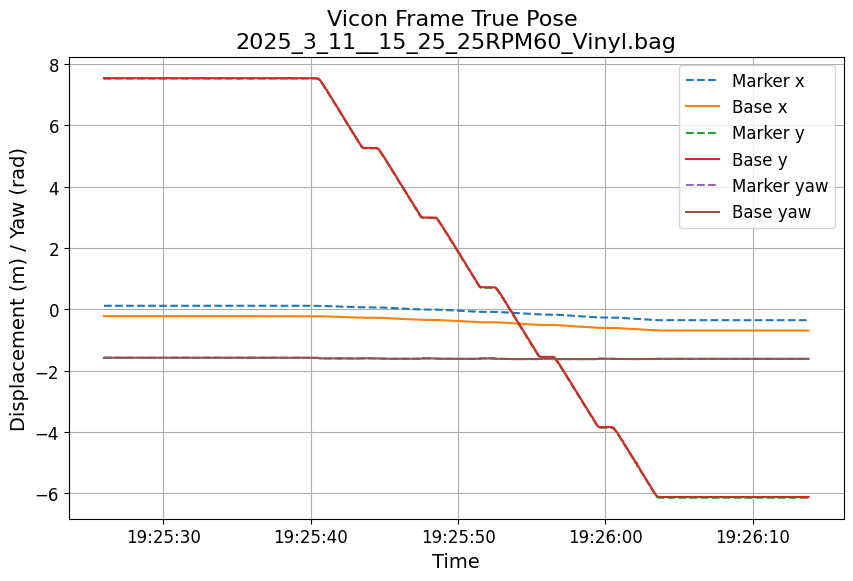

In [17]:
# # display(results["vicon_base_pose"])
# results["VICON_marker_TRUE_POSE"].plot(
#     title=f"Vicon Frame True marker Pose \n{bag_name}",
#     ylabel="Displacement( m)",
#     y=["pose.position.x", "pose.position.y", "yaw"]
# )

# # display(results["vicon_base_pose"])
# results["VICON_base_TRUE_POSE"].plot(
#     title=f"Vicon Frame True base_link Pose \n{bag_name}",
#     ylabel="Displacement( m)",
#     y=["pose.position.x", "pose.position.y", "yaw"]
# )


# Extract data
marker_pose = results["VICON_marker_TRUE_POSE"]
base_pose = results["VICON_base_TRUE_POSE"]

fig, ax = plt.subplots(figsize=(10, 6))

# Plot x-position
ax.plot(
    marker_pose.index,
    marker_pose["pose.position.x"],
    label="Marker x",
    linestyle="dashed",
)
ax.plot(base_pose.index, base_pose["pose.position.x"], label="Base x")

# Plot y-position
ax.plot(
    marker_pose.index,
    marker_pose["pose.position.y"],
    label="Marker y",
    linestyle="dashed",
)
ax.plot(base_pose.index, base_pose["pose.position.y"], label="Base y")

# Plot yaw
ax.plot(marker_pose.index, marker_pose["yaw"], label="Marker yaw", linestyle="dashed")
ax.plot(base_pose.index, base_pose["yaw"], label="Base yaw")

ax.set_title(f"Vicon Frame True Pose \n{bag_name}")
ax.set_xlabel("Time")
ax.set_ylabel("Displacement (m) / Yaw (rad)")
ax.legend()
ax.grid()

save_all_figures(bag_name=bag_name)

In [18]:
# from viz_utils import visualize_transforms

# # Pretty sure this is wrong.

# # Store vicon->base_link transforms for later use
# vicon_to_base_transforms = []
# for timestamp, row in VICON_base_TRUE_POSE.iterrows():
#     transform = TransformStamped()
#     transform.header.stamp.sec = int(timestamp.timestamp())
#     transform.header.stamp.nanosec = int((timestamp.timestamp() % 1) * 1e9)
#     transform.header.frame_id = "vicon"
#     transform.child_frame_id = "base_link"
#     transform.transform.translation.x = row["pose.position.x"]
#     transform.transform.translation.y = row["pose.position.y"]
#     transform.transform.translation.z = row["pose.position.z"]
#     transform.transform.rotation.x = row["pose.orientation.x"]
#     transform.transform.rotation.y = row["pose.orientation.y"]
#     transform.transform.rotation.z = row["pose.orientation.z"]
#     transform.transform.rotation.w = row["pose.orientation.w"]
#     vicon_to_base_transforms.append(transform)

# results['vicon_to_base_transforms'] = vicon_to_base_transforms  # Store for later use

# visualize_transforms(results['vicon_to_base_transforms'])

# # display(vicon_base_pose)

### Make VICON_{br,fr,bl,fl}wheel_TRUE_POSE

In [19]:
# Make a TF buffer and populate with static xforms.
tf_buffer = tf2_ros.Buffer()
for transform in results["static_transforms"]:
    # print(transform)
    tf_buffer.set_transform(transform, "default_authority")

VICON_base_TRUE_POSE = results["VICON_base_TRUE_POSE"]


# Create PoseStamps for all the tire frames.
base_to_fl_xform = tf_buffer.lookup_transform(
    "body_assembly", "fl_tire", rclpy.time.Time()
)
print("Transform Retrieved:", base_to_fl_xform)
VICON_flwheel_TRUE_POSE = offset_pose_df(VICON_base_TRUE_POSE, base_to_fl_xform)
results["VICON_flwheel_TRUE_POSE"] = add_euler_angles(VICON_flwheel_TRUE_POSE)
# display(vicon_body_pose)

base_to_fr_xform = tf_buffer.lookup_transform(
    "body_assembly", "fr_tire", rclpy.time.Time()
)
print("Transform Retrieved:", base_to_fr_xform)
VICON_frwheel_TRUE_POSE = offset_pose_df(VICON_base_TRUE_POSE, base_to_fr_xform)
results["VICON_frwheel_TRUE_POSE"] = add_euler_angles(VICON_frwheel_TRUE_POSE)

base_to_bl_xform = tf_buffer.lookup_transform(
    "body_assembly", "bl_tire", rclpy.time.Time()
)
print("Transform Retrieved:", base_to_bl_xform)
VICON_blwheel_TRUE_POSE = offset_pose_df(VICON_base_TRUE_POSE, base_to_bl_xform)
results["VICON_blwheel_TRUE_POSE"] = add_euler_angles(VICON_blwheel_TRUE_POSE)

base_to_br_xform = tf_buffer.lookup_transform(
    "body_assembly", "br_tire", rclpy.time.Time()
)
print("Transform Retrieved:", base_to_br_xform)
VICON_brwheel_TRUE_POSE = offset_pose_df(VICON_base_TRUE_POSE, base_to_br_xform)
results["VICON_brwheel_TRUE_POSE"] = add_euler_angles(VICON_brwheel_TRUE_POSE)

# poses_to_pub = {
#     '/vicon_flwheel_pose': df_to_pose_stamped(results['vicon_flwheel_pose'], frame_id="vicon"),
#     '/vicon_frwheel_pose': df_to_pose_stamped(results['vicon_frwheel_pose'], frame_id="vicon"),
#     '/vicon_blwheel_pose': df_to_pose_stamped(results['vicon_blwheel_pose'], frame_id="vicon"),
#     '/vicon_brwheel_pose': df_to_pose_stamped(results['vicon_brwheel_pose'], frame_id="vicon"),

#     "/vicon_base_pose": df_to_pose_stamped(results['vicon_base_pose'], frame_id="vicon"),
#     "/VICON_marker_TRUE_TWIST": df_to_pose_stamped(results['VICON_marker_TRUE_TWIST'], frame_id="vicon")
# }
# publish_pose_stamped_list(poses_to_pub, rate_hz=100)

Transform Retrieved: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='body_assembly'), child_frame_id='fl_tire', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=0.3370463315342484, y=0.2571425844940314, z=-0.10128250005177085), rotation=geometry_msgs.msg.Quaternion(x=1.1102230246264002e-16, y=-1.5593048718502875e-30, z=8.226802350443992e-29, w=1.0)))
Transform Retrieved: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='body_assembly'), child_frame_id='fr_tire', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=0.33704633143069057, y=-0.25720741550595705, z=-0.1012825000517783), rotation=geometry_msgs.msg.Quaternion(x=-7.831291700877619e-17, y=2.4865692621727728e-30, z=-4.190823558985819e-31, w=1.0)))
Transform Retrieved: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Head

Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Vicon_Frame_True_brwheel_Pose___2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Vicon_Frame_True_base_Pose_____bag_name.png


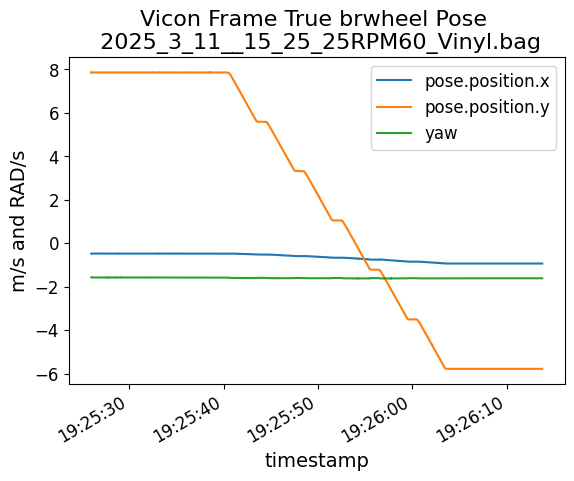

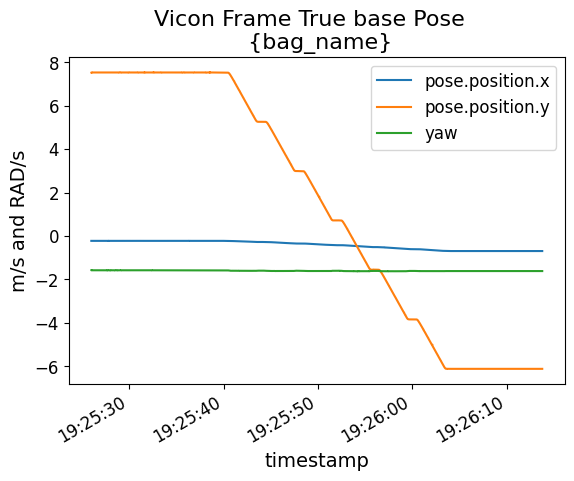

In [20]:
# br,fr,bl,fl

# display(results["VICON_brwheel_TRUE_POSE"])
results["VICON_brwheel_TRUE_POSE"].plot(
    title=f"Vicon Frame True brwheel Pose \n {bag_name}",
    ylabel="m/s and RAD/s",
    y=["pose.position.x", "pose.position.y", "yaw"],
)

# display(results["VICON_base_TRUE_POSE"])
results["VICON_base_TRUE_POSE"].plot(
    title="Vicon Frame True base Pose  \n {bag_name}",
    ylabel="m/s and RAD/s",
    y=["pose.position.x", "pose.position.y", "yaw"],
)

save_all_figures(bag_name=bag_name)

In [21]:
labels = [
    "VICON_base_TRUE_POSE",
    "VICON_marker_TRUE_POSE",
    "VICON_brwheel_TRUE_POSE",
    "VICON_blwheel_TRUE_POSE",
    "VICON_frwheel_TRUE_POSE",
    "VICON_flwheel_TRUE_POSE",
]

df = []
for label in labels:
    df.append(results[label])


# animator = MultiViconPoseAnimator(df, labels=labels, max_size_mb=10, figsize=(12,12), elev=45, azim=60, interval=20)
# animator.run()
# save_animation(animator=animator, bag_name=bag_name)


In [22]:
# from viz_utils import ViconPoseAnimator

# df = results["VICON_marker_TRUE_POSE"]

# animator = ViconPoseAnimator(df, max_size_mb=1, figsize=(6,6), elev=45, azim=60)
# animator.run()

## Make ODOM_frames from VICON_marker_TRUE_POSE
Use the VICON_marker_TRUE_POSE as a TransformStamped to find the Odom frame.

In [23]:
# import tf2_ros
# from tf2_geometry_msgs import TransformStamped
# from analysis_utils import pose_df_to_transforms, #, df_offset_twist_df

# # Make a tf buffer to store transfors we may want to apply. This let's us use tf2 to handle the interp.
# # Load the existing static transforms in case we want them.
# tf_buffer = tf2_ros.Buffer()
# for transform in results["static_transforms"]:
#     tf_buffer.set_transform(transform, "default_authority")
# # Broadcast transforms for visualization.
# send_static_transform(results["static_transforms"])

# # Original pose data for the marker in the VICON frame. This will become our TransformStamped.
# VICON_marker_TRUE_POSE = results[
#     "VICON_marker_TRUE_POSE"
# ]

# # Original twist data for the marker in the VICON frame. Xform this into it's own local frame.
# VICON_brwheel_TRUE_POSE = results[
#     "VICON_brwheel_TRUE_POSE"
# ]


# # Make transforms from the VICON_marker_TRUE_POSE PoseStamped data
# # Create tf2_geometry_msgs.TransformStamped objects and store in a DF.
# vicon_to_marker_xforms = pose_df_to_transforms(
#     results["VICON_marker_TRUE_POSE"], "vicon", "vicon_marker"
# )
# # print("Transform Retrieved:", vicon_to_marker_xforms)

# # Now combine vicon_to_marker_xforms with the vicon_marker->br_wheel and.

# # Now apply the TransformStamps to the VICON_marker_TRUE_TWIST DataFrame and let tf2 handle any small interpolating.
# LOCAL_brwheel_TRUE_POSE = df_offset_pose_df(
#     VICON_marker_TRUE_POSE, vicon_to_marker_xforms
# )
# results["LOCAL_brwheel_TRUE_POSE"] = LOCAL_brwheel_TRUE_POSE


In [24]:
from utils.analysis_utils import offset_pose_df

tf2_geometry_msgs.do_transform_pose
# from viz_utils import MultiViconPoseAnimator, ViconPoseAnimator

# Make a TF buffer and populate with static xforms.
tf_buffer = tf2_ros.Buffer()
for transform in results["static_transforms"]:
    # print(transform)
    tf_buffer.set_transform(transform, "default_authority")

# print(tf_buffer.all_frames_as_yaml())

# Broadcast so we can look at them in rviz.
send_static_transform(results["static_transforms"])


# Get dataframe we are going to transform *from*.
VICON_marker_TRUE_POSE = results["VICON_marker_TRUE_POSE"]

# apply base_link->vicon_ball.
ball_to_base_xform = tf_buffer.lookup_transform(
    "vicon_ball", "body_assembly", rclpy.time.Time()
)
print("Transform Retrieved:", ball_to_base_xform)


VICON_base_TRUE_POSE = offset_pose_df(VICON_marker_TRUE_POSE, ball_to_base_xform)

results["VICON_base_TRUE_POSE"] = add_euler_angles(VICON_base_TRUE_POSE)

# poses_to_pub = {
#     "/VICON_marker_TRUE_POSE": df_to_pose_stamped(results['VICON_marker_TRUE_POSE'], frame_id="vicon"),
#     "/VICON_marker_TRUE_POSE": df_to_pose_stamped(results['VICON_marker_TRUE_POSE'], frame_id="vicon")
# }
# publish_pose_stamped_list(poses_to_pub, rate_hz=100)


df = []
df.append(results["VICON_base_TRUE_POSE"])
df.append(results["VICON_marker_TRUE_POSE"])
labels = ["VICON_base_TRUE_POSE", "VICON_marker_TRUE_POSE"]

# animator = MultiViconPoseAnimator(df, labels=labels, max_size_mb=1, figsize=(6,6), elev=45, azim=60)
# animator.run()

[WARN] [1742099516.608748420] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1742099516.608758143] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.


Transform Retrieved: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='vicon_ball'), child_frame_id='body_assembly', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=-0.0068463314824702744, y=-0.33905758449404216, z=-0.03251200000000004), rotation=geometry_msgs.msg.Quaternion(x=-4.279977145501479e-16, y=5.427076622916737e-16, z=3.901640706876909e-16, w=1.0)))


## Make LOCAL_ frames from VICON_marker_TRUE_TWIST
Offset VICON_marker_TRUE_TWIST to vicon_body_twist and vicon_{fr,fl,bl,br}_twist
Same as before but use PyKDL to handle the Twist transform.

First get the 

### Make vicon_body_twist

In [25]:
from utils.analysis_utils import df_to_twist_stamped, offset_twist_df
from utils.viz_utils import publish_twist_stamped_list

# Make a TF buffer and populate with static xforms.
tf_buffer = tf2_ros.Buffer()
for transform in results["static_transforms"]:
    # print(transform)
    tf_buffer.set_transform(transform, "default_authority")

# Broadcast so we can look at them in rviz.
send_static_transform(results["static_transforms"])


# Get dataframe we are going to transform *from*.
VICON_marker_TRUE_TWIST = results["VICON_marker_TRUE_TWIST"]


# apply base_link->vicon_ball
ball_to_base_xform = tf_buffer.lookup_transform(
    "vicon_ball", "base_link", rclpy.time.Time()
)
print("Transform Retrieved:", ball_to_base_xform)

vicon_base_twist = offset_twist_df(VICON_marker_TRUE_TWIST, ball_to_base_xform)
results["vicon_base_twist"] = vicon_base_twist

# twists_to_pub = {
#     "/vicon_base_twist": df_to_twist_stamped(results['vicon_base_twist'], frame_id="base_link"),
# }
# publish_twist_stamped_list(twists_to_pub, rate_hz=100)

[WARN] [1742099520.294073828] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1742099520.294086051] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.


Transform Retrieved: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='vicon_ball'), child_frame_id='base_link', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=-0.0068463314824702744, y=-0.33905758449404216, z=-0.03251200000000004), rotation=geometry_msgs.msg.Quaternion(x=-4.279977145501479e-16, y=5.427076622916737e-16, z=3.901640706876909e-16, w=1.0)))


<Axes: title={'center': 'Vicon Frame True base Twist'}, xlabel='timestamp', ylabel='m/s and RAD/s'>

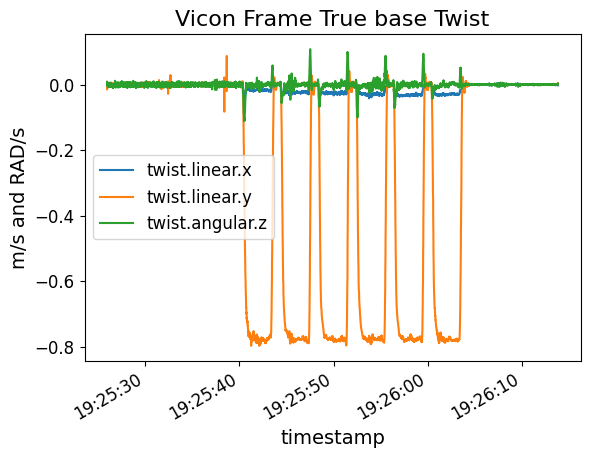

In [26]:
# display(results["VICON_fl_tire_TRUTH_TWIST"])
results["vicon_base_twist"].plot(
    title="Vicon Frame True base Twist",
    ylabel="m/s and RAD/s",
    y=["twist.linear.x", "twist.linear.y", "twist.angular.z"],
)



### Make vicon_wheel_twists

In [27]:
import rclpy
import tf2_ros
from utils.analysis_utils import df_to_twist_stamped, offset_twist_df
from utils.viz_utils import publish_twist_stamped_list

# Make a TF buffer and populate with static transforms.
tf_buffer = tf2_ros.Buffer()
for transform in results["static_transforms"]:
    tf_buffer.set_transform(transform, "default_authority")

# Broadcast transforms for visualization.
send_static_transform(results["static_transforms"])

# Original twist data from vicon_ball frame
VICON_marker_TRUE_TWIST = results["VICON_marker_TRUE_TWIST"]

# Tires to transform to
frames = ["fl_tire", "fr_tire", "bl_tire", "br_tire"]
twists_to_pub = {}

for frame in frames:
    ball_to_tire_xform = tf_buffer.lookup_transform(
        "vicon_ball", frame, rclpy.time.Time()
    )
    print(f"Transform Retrieved for {frame}:", ball_to_tire_xform)

    # Calculate tire twist directly from vicon ball twist
    vicon_tire_twist = offset_twist_df(VICON_marker_TRUE_TWIST, ball_to_tire_xform)
    results[f"vicon_{frame}_twist"] = vicon_tire_twist

    # Prepare twists for publishing
    twists_to_pub[f"/vicon_{frame}_twist"] = df_to_twist_stamped(
        results[f"vicon_{frame}_twist"], frame_id=frame
    )

# Publish twists for visualization.
# publish_twist_stamped_list(twists_to_pub, rate_hz=100)


[WARN] [1742099524.092046491] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1742099524.092070952] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.


Transform Retrieved for fl_tire: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='vicon_ball'), child_frame_id='fl_tire', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=0.3302000000517778, y=-0.08191500000001067, z=-0.13379450005177146), rotation=geometry_msgs.msg.Quaternion(x=-3.169754120875079e-16, y=5.427076622916721e-16, z=3.9016407068777313e-16, w=1.0)))
Transform Retrieved for fr_tire: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='vicon_ball'), child_frame_id='fr_tire', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=0.3301999999482204, y=-0.5962649999999992, z=-0.13379450005177848), rotation=geometry_msgs.msg.Quaternion(x=-5.063106315589241e-16, y=5.427076622916762e-16, z=3.9016407068769055e-16, w=1.0)))
Transform Retrieved for bl_tire: geometry_msgs.msg.TransformSta

<Axes: title={'center': 'Vicon Frame True blwheel Twist'}, xlabel='timestamp', ylabel='m/s and RAD/s'>

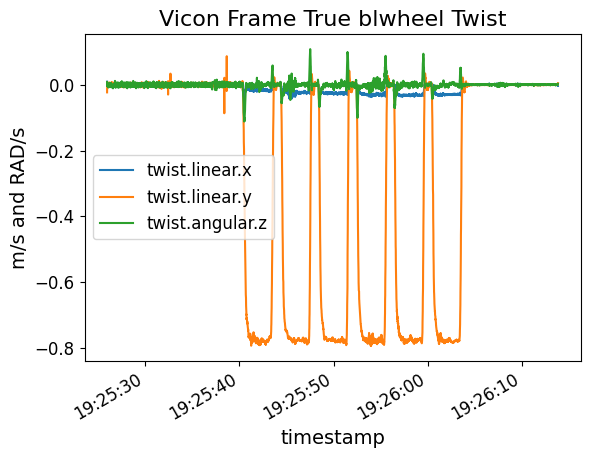

In [28]:
# display(results["VICON_fl_tire_TRUTH_TWIST"])
results["vicon_bl_tire_twist"].plot(
    title="Vicon Frame True blwheel Twist",
    ylabel="m/s and RAD/s",
    y=["twist.linear.x", "twist.linear.y", "twist.angular.z"],
)

## Make LOCAL_marker_TRUE_TWIST
Use the markers own pose VICON_marker_TRUE_POSE to find it's own local twist. Then transform this to the other frames (wheels).


In [29]:
from typing import List

import numpy as np
import pandas as pd
import rclpy
import tf2_ros
from geometry_msgs.msg import TransformStamped, TwistStamped
from rclpy.duration import Duration
from scipy.spatial.transform import Rotation as R


def df_offset_twist_df(
    twist_df: pd.DataFrame, transforms: List[TransformStamped]
) -> pd.DataFrame:
    """
    Given a DataFrame of TwistStamped data and a list of TransformStamped objects, transform the TwistStamped
    data into the correct local frame using the corresponding transform.

    This function uses a tf2_ros.Buffer to look up the correct transform at each timestamp
    and manually applies the transformation to the twist (rotates both linear and angular velocities). Let TF do
    the qaut SLERP for us.

    Args:
        twist_df (pd.DataFrame): DataFrame containing TwistStamped data with timestamps as the index.
        transforms (List[TransformStamped]): List of TransformStamped objects representing the transformation.

    Returns:
        pd.DataFrame: The transformed twist DataFrame in the local frame.
    """

    # Create a TF buffer and store all transforms
    # tf_buffer = tf2_ros.Buffer()
    # Help with some messages not having matching xforms?
    tf_buffer = tf2_ros.Buffer(cache_time=rclpy.duration.Duration(seconds=60))

    for transform in transforms:
        tf_buffer.set_transform(transform, "default_authority")

    # print("TF Buffer Loaded Transforms:")
    # for transform in transforms:
    #     t_sec = transform.header.stamp.sec
    #     t_nanosec = transform.header.stamp.nanosec
    #     print(f"Transform at time {t_sec}.{t_nanosec}: {transform.header.frame_id} -> {transform.child_frame_id}")

    # earliest = tf_buffer.get_latest_common_time("vicon", "vicon_marker")
    # latest = tf_buffer.get_latest_common_time("vicon_marker", "vicon")
    # print(f"TF Buffer Earliest Time: {earliest.nanoseconds}")
    # print(f"TF Buffer Latest Time: {latest.nanoseconds}")

    transformed_twist_data = []

    for index, row in twist_df.iterrows():
        try:
            # Convert timestamp to ROS2 Time object. Use the integer components for precision.
            timestamp = rclpy.time.Time(
                seconds=row["header.stamp.sec"], nanoseconds=row["header.stamp.nanosec"]
            )

            # Get the transform from the twist's original frame to the target frame
            # source_frame = str(row["header._frame_id"])  # Frame the twist was originally in
            # print(source_frame)
            source_frame = "vicon"
            target_frame = "vicon_marker"  # The frame we want the twist in

            t_sec = int(row["header.stamp.sec"])
            t_nanosec = int(row["header.stamp.nanosec"])

            timestamp = rclpy.time.Time(seconds=t_sec, nanoseconds=t_nanosec)

            print(f"Requesting transform at time: {timestamp.nanoseconds} ns")

            if not tf_buffer.can_transform(
                target_frame,
                source_frame,
                timestamp,
                timeout=rclpy.duration.Duration(seconds=0.1),
            ):
                print(
                    f"WARNING: No exact transform found for {index}. Trying latest available."
                )

                # Try fetching the latest transform instead?
                try:
                    transform = tf_buffer.lookup_transform(
                        target_frame,
                        source_frame,
                        rclpy.time.Time(),
                        timeout=rclpy.duration.Duration(seconds=0.1),
                    )
                except Exception as e:
                    print(f"ERROR: No fallback transform found. Skipping {index}.")
                    transformed_twist_data.append(
                        {
                            "twist.linear.x": float("nan"),
                            "twist.linear.y": float("nan"),
                            "twist.linear.z": float("nan"),
                            "twist.angular.x": float("nan"),
                            "twist.angular.y": float("nan"),
                            "twist.angular.z": float("nan"),
                        }
                    )
                    continue

            transform = tf_buffer.lookup_transform(
                target_frame, source_frame, timestamp
            )

            # Extract rotation quaternion and convert to matrix
            quat = np.array(
                [
                    transform.transform.rotation.x,
                    transform.transform.rotation.y,
                    transform.transform.rotation.z,
                    transform.transform.rotation.w,
                ]
            )
            rotation_matrix = R.from_quat(quat).as_matrix()

            # Extract translation vector (frame offset)
            translation = np.array(
                [
                    transform.transform.translation.x,
                    transform.transform.translation.y,
                    transform.transform.translation.z,
                ]
            )

            # Extract twist velocities
            linear_velocity = np.array(
                [row["twist.linear.x"], row["twist.linear.y"], row["twist.linear.z"]]
            )

            angular_velocity = np.array(
                [row["twist.angular.x"], row["twist.angular.y"], row["twist.angular.z"]]
            )

            # Apply rotation to linear velocity.
            rotated_linear_velocity = rotation_matrix @ linear_velocity

            # Compute velocity induced by rotation (omega x T)
            translation_velocity = np.cross(angular_velocity, translation)

            # Now add the "apparent(?)" translational velocity to the new local frame vel.
            transformed_linear_velocity = rotated_linear_velocity + translation_velocity

            # And point our angular vel in the correct dir in the local frame.
            transformed_angular_velocity = rotation_matrix @ angular_velocity

            transformed_twist_data.append(
                {
                    "twist.linear.x": transformed_linear_velocity[0],
                    "twist.linear.y": transformed_linear_velocity[1],
                    "twist.linear.z": transformed_linear_velocity[2],
                    "twist.angular.x": transformed_angular_velocity[0],
                    "twist.angular.y": transformed_angular_velocity[1],
                    "twist.angular.z": transformed_angular_velocity[2],
                }
            )

        except Exception as e:
            print(f"Skipping timestamp {index} due to error: {e}")
            transformed_twist_data.append(
                {
                    "twist.linear.x": float("nan"),
                    "twist.linear.y": float("nan"),
                    "twist.linear.z": float("nan"),
                    "twist.angular.x": float("nan"),
                    "twist.angular.y": float("nan"),
                    "twist.angular.z": float("nan"),
                }
            )

    # Convert transformed data back into a DataFrame
    transformed_twist_df = pd.DataFrame(transformed_twist_data, index=twist_df.index)

    return transformed_twist_df


In [30]:
# Use the PoseStamped from the vicon_msg as a transform to get the Twist of the marker into it's own local frame.
"""Let's change our approach here. Rather than making a DF of transform data let's make actual TransformStamped and use the 
TF2 libraries interpolation. I don't want/need to to implement SLERP myself. Then I can pass the TransformStamped back and forth using my 
conversion functions.
"""

import tf2_ros
from utils.analysis_utils import pose_df_to_transforms  # , df_offset_twist_df
from tf2_geometry_msgs import TransformStamped

# Make a tf buffer to store transfors we may want to apply. This let's us use tf2 to handle the interp.
# Load the existing static transforms in case we want them.
# tf_buffer = tf2_ros.Buffer()
# for transform in results["static_transforms"]:
#     tf_buffer.set_transform(transform, "default_authority")
# # Broadcast transforms for visualization.
# send_static_transform(results["static_transforms"])


# Original twist data for the marker in the VICON frame. Xform this into it's own local frame.
VICON_marker_TRUE_TWIST = results["VICON_marker_TRUE_TWIST"]

# Original pose data for the marker in the VICON frame. This will become our TransformStamped.
VICON_marker_TRUE_POSE = results["VICON_marker_TRUE_POSE"]

# Make transforms from the VICON_marker_TRUE_POSE PoseStamped data
# Create tf2_geometry_msgs.TransformStamped objects and store in a DF.
vicon_to_marker_xforms = pose_df_to_transforms(
    results["VICON_marker_TRUE_POSE"], "vicon", "vicon_marker"
)
# print("Transform Retrieved:", vicon_to_marker_xforms)


# Now apply the TransformStamps to the VICON_marker_TRUE_TWIST DataFrame and let tf2 handle any small interpolating.
LOCAL_marker_TRUE_TWIST = df_offset_twist_df(
    VICON_marker_TRUE_TWIST, vicon_to_marker_xforms
)
results["LOCAL_marker_TRUE_TWIST"] = LOCAL_marker_TRUE_TWIST


Requesting transform at time: 1741721125971342941 ns
Requesting transform at time: 1741721125971380792 ns
Requesting transform at time: 1741721125971431364 ns
Requesting transform at time: 1741721125981352217 ns
Requesting transform at time: 1741721125981382332 ns
Requesting transform at time: 1741721125981403423 ns
Requesting transform at time: 1741721125981430932 ns
Requesting transform at time: 1741721125991390755 ns
Requesting transform at time: 1741721125991437840 ns
Requesting transform at time: 1741721125991472329 ns
Requesting transform at time: 1741721125991499813 ns
Requesting transform at time: 1741721125991594441 ns
Requesting transform at time: 1741721125991624681 ns
Requesting transform at time: 1741721125991665175 ns
Requesting transform at time: 1741721125991696737 ns
Requesting transform at time: 1741721125991729179 ns
Requesting transform at time: 1741721125991760138 ns
Requesting transform at time: 1741721125991792792 ns
Requesting transform at time: 1741721125991826

In [31]:
# pd.set_option('display.max_rows', 500)
# vicon_to_marker_xforms
# display(vicon_to_marker_xforms)
# print(len(vicon_to_marker_xforms))
# display(VICON_marker_TRUE/_POSE)
# print(vicon_to_marker_xforms[5])
# display(VICON_marker_TRUE_TWIST)
# print(results['LOCAL_marker_TRUE_TWIST'], )

### Plot local vicon marker

Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/LOCAL_marker_TRUE_TWIST__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/VICON_marker_TRUE_TWIST__2025_3_11__15_25_25RPM60_Vinyl_bag.png


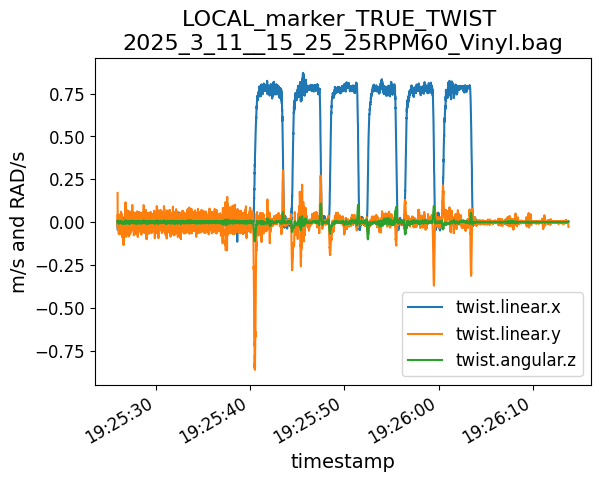

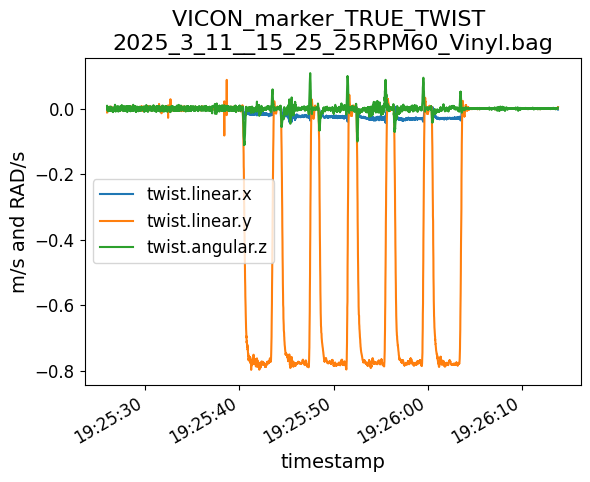

In [32]:
# display(results["VICON_fl_tire_TRUTH_TWIST"])
results["LOCAL_marker_TRUE_TWIST"].notna()


p = results["LOCAL_marker_TRUE_TWIST"].plot(
    title=f"LOCAL_marker_TRUE_TWIST \n{bag_name}",
    ylabel="m/s and RAD/s",
    y=["twist.linear.x", "twist.linear.y", "twist.angular.z"],
)
external_plotter_2.add_plot(p,row=0,col=0)

p = results["VICON_marker_TRUE_TWIST"].plot(
    title=f"VICON_marker_TRUE_TWIST \n{bag_name}",
    ylabel="m/s and RAD/s",
    y=["twist.linear.x", "twist.linear.y", "twist.angular.z"],
)
external_plotter_2.add_plot(p,row=0,col=1)

save_all_figures(bag_name=bag_name)

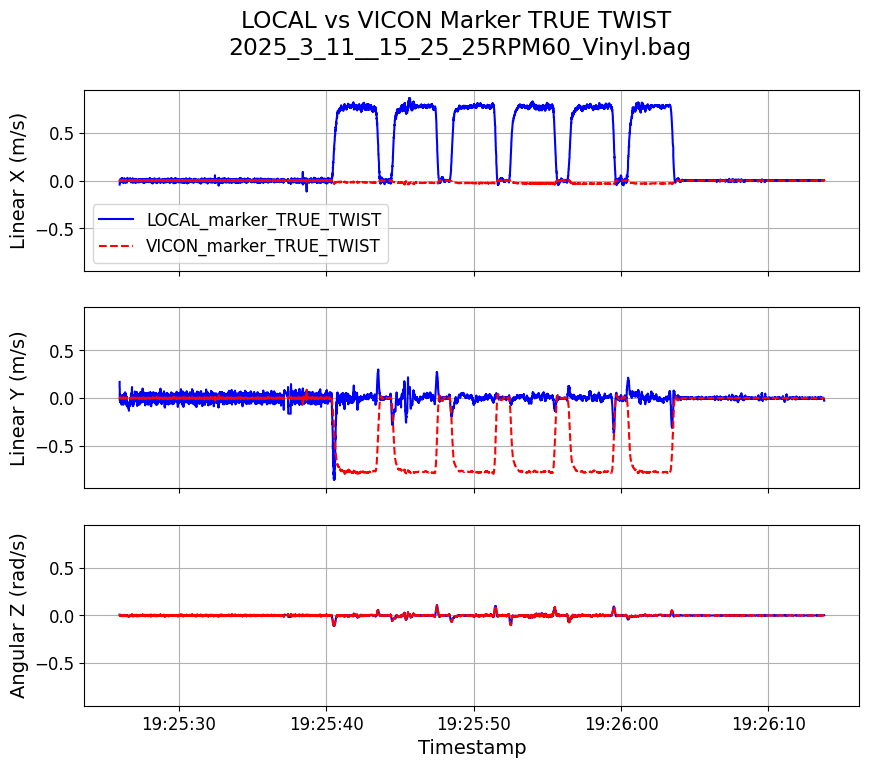

In [33]:
# Extract the relevant data
local_marker_twist = results["LOCAL_marker_TRUE_TWIST"][
    ["twist.linear.x", "twist.linear.y", "twist.angular.z"]
]
vicon_marker_twist = results["VICON_marker_TRUE_TWIST"][
    ["twist.linear.x", "twist.linear.y", "twist.angular.z"]
]

# Create a single figure with shared axes
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)
fig.suptitle(f"LOCAL vs VICON Marker TRUE TWIST \n{bag_name}")

# Plot linear x velocity
axes[0].plot(
    local_marker_twist.index,
    local_marker_twist["twist.linear.x"],
    label="LOCAL_marker_TRUE_TWIST",
    linestyle="-",
    color="blue",
)
axes[0].plot(
    vicon_marker_twist.index,
    vicon_marker_twist["twist.linear.x"],
    label="VICON_marker_TRUE_TWIST",
    linestyle="--",
    color="red",
)
axes[0].set_ylabel("Linear X (m/s)")
axes[0].legend()
axes[0].grid(True)

# Plot linear y velocity
axes[1].plot(
    local_marker_twist.index,
    local_marker_twist["twist.linear.y"],
    linestyle="-",
    color="blue",
)
axes[1].plot(
    vicon_marker_twist.index,
    vicon_marker_twist["twist.linear.y"],
    linestyle="--",
    color="red",
)
axes[1].set_ylabel("Linear Y (m/s)")
axes[1].grid(True)

# Plot angular z velocity
axes[2].plot(
    local_marker_twist.index,
    local_marker_twist["twist.angular.z"],
    linestyle="-",
    color="blue",
)
axes[2].plot(
    vicon_marker_twist.index,
    vicon_marker_twist["twist.angular.z"],
    linestyle="--",
    color="red",
)
axes[2].set_ylabel("Angular Z (rad/s)")
axes[2].set_xlabel("Timestamp")
axes[2].grid(True)

# plt.show()

external_plotter_2.add_plot(axes[0], row=1, col=0)
external_plotter_2.add_plot(axes[1], row=1,col=1)


## Make LOCAL_wheel_TRUE_TWIST
Calc the local frame twists.

Maybe better names for the DataFrames would be `FRAME_OBJ-NAME_SOURCE_TYPE`, e.g. `VICON_BODY_TRUTH_TWIST` or `SELF_FRWHEEL_ODOM_TWIST`.


In [34]:
import numpy as np
import pandas as pd
from geometry_msgs.msg import TransformStamped
from scipy.spatial.transform import Rotation as R


def apply_static_transform_to_twist_df(
    twist_df: pd.DataFrame, transform: TransformStamped
) -> pd.DataFrame:
    """
    Apply a SINGLE static TransformStamped to an entire TwistStamped DataFrame. We would use this for
    intra-robot transforms. For world relative ones we need to apply our vicon pose as the first transform.

    Args:
        twist_df (pd.DataFrame): DataFrame containing TwistStamped data.
        transform (TransformStamped): A single static TransformStamped object.

    Returns:
        pd.DataFrame: The transformed twist DataFrame in the local frame.
    """

    transformed_twist_data = []

    # Extract rotation quaternion and convert to matrix
    quat = np.array(
        [
            transform.transform.rotation.x,
            transform.transform.rotation.y,
            transform.transform.rotation.z,
            transform.transform.rotation.w,
        ]
    )
    rotation_matrix = R.from_quat(quat).as_matrix()

    # Extract translation vector (frame offset)
    translation = np.array(
        [
            transform.transform.translation.x,
            transform.transform.translation.y,
            transform.transform.translation.z,
        ]
    )

    print(
        f"Applying STATIC transform: {transform.header.frame_id} -> {transform.child_frame_id}"
    )

    for index, row in twist_df.iterrows():
        try:
            # Extract twist velocities
            linear_velocity = np.array(
                [row["twist.linear.x"], row["twist.linear.y"], row["twist.linear.z"]]
            )

            angular_velocity = np.array(
                [row["twist.angular.x"], row["twist.angular.y"], row["twist.angular.z"]]
            )

            # Apply rotation to linear velocity
            rotated_linear_velocity = rotation_matrix @ linear_velocity

            # Compute velocity induced by rotation (cross product term)
            translation_velocity = np.cross(angular_velocity, translation)

            # Final transformed linear velocity
            transformed_linear_velocity = rotated_linear_velocity + translation_velocity

            # Apply rotation to angular velocity
            transformed_angular_velocity = rotation_matrix @ angular_velocity

            transformed_twist_data.append(
                {
                    "twist.linear.x": transformed_linear_velocity[0],
                    "twist.linear.y": transformed_linear_velocity[1],
                    "twist.linear.z": transformed_linear_velocity[2],
                    "twist.angular.x": transformed_angular_velocity[0],
                    "twist.angular.y": transformed_angular_velocity[1],
                    "twist.angular.z": transformed_angular_velocity[2],
                }
            )

        except KeyError as e:
            print(f"Skipping timestamp {index} due to error: {e}")
            transformed_twist_data.append(
                {
                    "twist.linear.x": float("nan"),
                    "twist.linear.y": float("nan"),
                    "twist.linear.z": float("nan"),
                    "twist.angular.x": float("nan"),
                    "twist.angular.y": float("nan"),
                    "twist.angular.z": float("nan"),
                }
            )

    # Convert transformed data back into a DataFrame
    transformed_twist_df = pd.DataFrame(transformed_twist_data, index=twist_df.index)

    return transformed_twist_df


In [35]:
""" Use the static URDF transforms vicon_ball->fr_tire on the LOCAL_marker_TRUE_TWIST DataFrame. 
This will give us the twist of the wheels in their own local frame.
"""

tf_buffer = tf2_ros.Buffer()
for transform in results["static_transforms"]:
    tf_buffer.set_transform(transform, "default_authority")

# Get our static transforms.
send_static_transform(results["static_transforms"])

# Local twist data from vicon_marker frame
LOCAL_marker_TRUE_TWIST = results["LOCAL_marker_TRUE_TWIST"]

# Tires frames to transform to.
frames = ["fl_tire", "fr_tire", "bl_tire", "br_tire"]
twists_to_pub = {}

# Apply the Twist transform for each wheel.
for frame in frames:
    # Get static transform from vicon_ball -> XX_tire
    ball_to_tire_xform = tf_buffer.lookup_transform(
        frame, "vicon_ball", rclpy.time.Time()
    )
    print(f"Transform Retrieved for {frame}:", ball_to_tire_xform)

    # Transform vicon_ball twist into tire's local frame using the updated function
    vicon_tire_twist = apply_static_transform_to_twist_df(
        LOCAL_marker_TRUE_TWIST, ball_to_tire_xform
    )

    # Save our results.
    results[f"LOCAL_{frame}_TRUTH_TWIST"] = vicon_tire_twist

    # Prepare twists for publishing
    # twists_to_pub[f"/LOCAL_{frame}_TRUTH_TWIST"] = df_to_twist_stamped(results[f"LOCAL_{frame}_TRUTH_TWIST"], frame_id=frame)

# # Publish twists for visualization.
# publish_twist_stamped_list(twists_to_pub, rate_hz=100)


[WARN] [1742099532.536864131] [rcl]: ROS_LOCALHOST_ONLY is deprecated but still honored if it is enabled. Use ROS_AUTOMATIC_DISCOVERY_RANGE and ROS_STATIC_PEERS instead.
[WARN] [1742099532.536876540] [rcl]: 'localhost_only' is disabled, 'automatic_discovery_range' and 'static_peers' will be used.


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

Transform Retrieved for fl_tire: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='fl_tire'), child_frame_id='vicon_ball', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=-0.3302000000517779, y=0.08191500000001078, z=0.13379450005177118), rotation=geometry_msgs.msg.Quaternion(x=3.169754120875079e-16, y=-5.427076622916721e-16, z=-3.9016407068777313e-16, w=1.0)))
Applying STATIC transform: fl_tire -> vicon_ball
Transform Retrieved for fr_tire: geometry_msgs.msg.TransformStamped(header=std_msgs.msg.Header(stamp=builtin_interfaces.msg.Time(sec=0, nanosec=0), frame_id='fr_tire'), child_frame_id='vicon_ball', transform=geometry_msgs.msg.Transform(translation=geometry_msgs.msg.Vector3(x=-0.3301999999482201, y=0.5962649999999992, z=0.13379450005177873), rotation=geometry_msgs.msg.Quaternion(x=5.063106315589241e-16, y=-5.427076622916762e-16, z=-3.9016407068769055e-16, w=1.0)))
Applying STATI

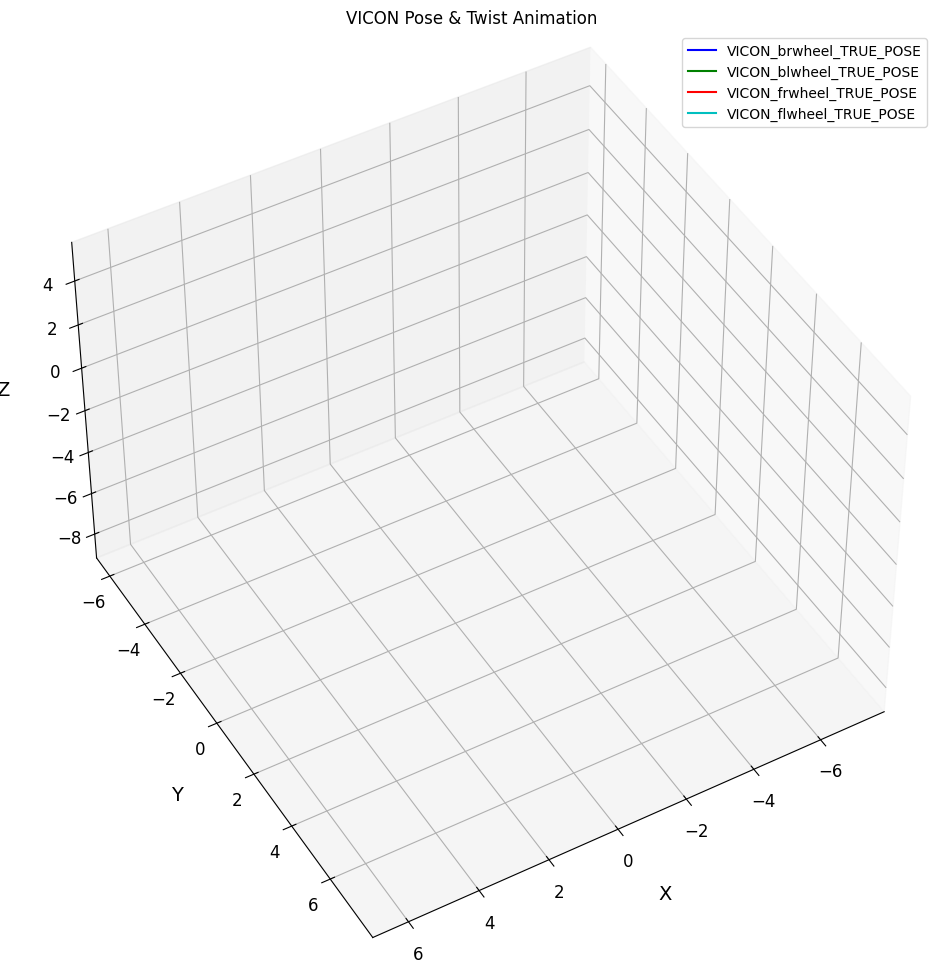

In [36]:
# TODO Make these ODOM_brwheel_TRUE_POSE instead
# TODO ADd vertical quiver for slip ratio.
pose_labels = [
    "VICON_brwheel_TRUE_POSE",
    "VICON_blwheel_TRUE_POSE",
    "VICON_frwheel_TRUE_POSE",
    "VICON_flwheel_TRUE_POSE",
]

twist_labels = [
    "LOCAL_fl_tire_TRUTH_TWIST",
    "LOCAL_fr_tire_TRUTH_TWIST",
    "LOCAL_bl_tire_TRUTH_TWIST",
    "LOCAL_br_tire_TRUTH_TWIST",
]

pose_dfs = [results[label] for label in pose_labels]
twist_dfs = [results[label] for label in twist_labels]

animator = MultiViconPoseTwistAnimator(
    pose_dfs=pose_dfs,
    twist_dfs=twist_dfs,
    labels=pose_labels,
    max_size_mb=10,
    figsize=(12, 12),
    elev=45,
    azim=60,
    interval=100,
)
# animator.run()
# save_animation(animator=animator, bag_name=bag_name)


Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Local_Frame_True_fl_tire_Twist.png


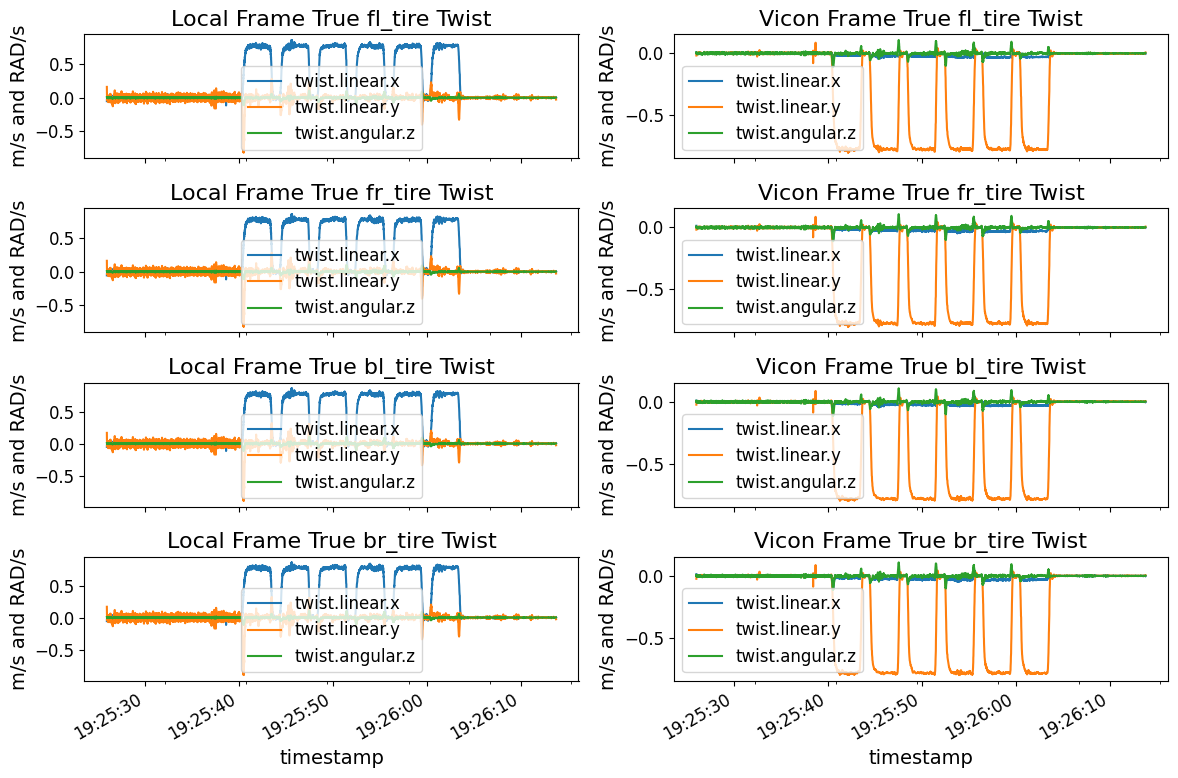

In [37]:
# Define wheel names
wheels = ["fl_tire", "fr_tire", "bl_tire", "br_tire"]

# Create plots for each wheel
fig, axes = plt.subplots(len(wheels), 2, figsize=(12, 8), sharex=True)

for i, wheel in enumerate(wheels):
    # Local frame twist
    results[f"LOCAL_{wheel}_TRUTH_TWIST"].plot(
        ax=axes[i, 0],
        title=f"Local Frame True {wheel} Twist",
        ylabel="m/s and RAD/s",
        y=["twist.linear.x", "twist.linear.y", "twist.angular.z"],
    )

    # Vicon frame twist
    results[f"vicon_{wheel}_twist"].plot(
        ax=axes[i, 1],
        title=f"Vicon Frame True {wheel} Twist",
        ylabel="m/s and RAD/s",
        y=["twist.linear.x", "twist.linear.y", "twist.angular.z"],
    )

# Adjust layout
plt.tight_layout()
# plt.show()

save_all_figures(bag_name=bag_name)

# external_

# Odometry Calculations
Get the wheel encoder derived pose and twist for body and wheels in the vicon and local frames.

## Preprocess Encoder Data
Remove outliers. Make wheel angles.

In [38]:
from utils.encoder_utils import encoder_to_rad, remove_encoder_outliers

# removed encoder samples: 1214
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Raw_Encoder_Counts__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Cleaned_Encoder_Counts__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Cleaned_Wheel_Angles__2025_3_11__15_25_25RPM60_Vinyl_bag.png


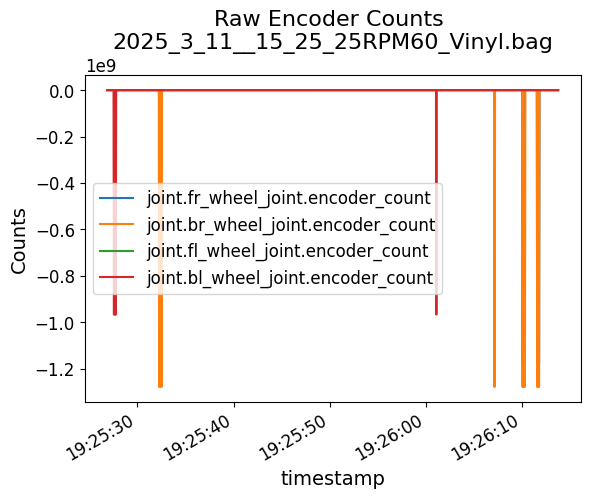

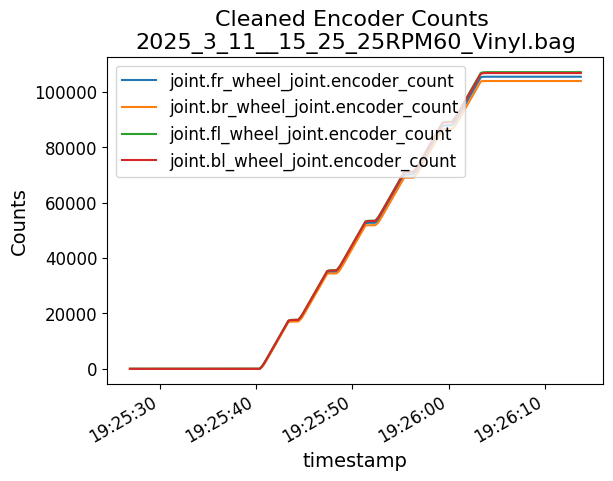

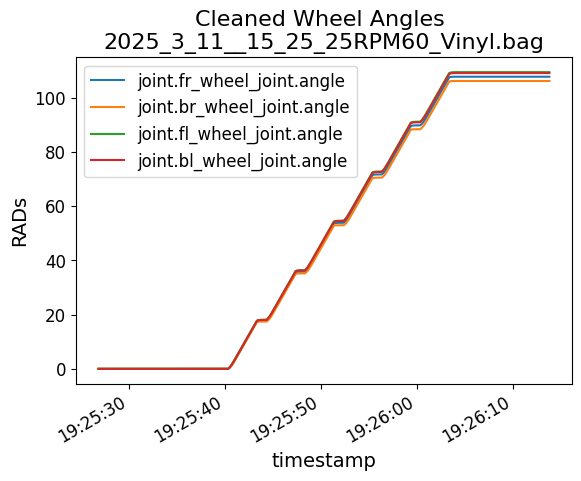

In [39]:
# Remove spikey outliers in the encoder data.
encoder_data = results["raw_encoder_count"]
# print(encoder_data)
# results['raw_encoder_count']

encoder_data.plot(
    title=f"Raw Encoder Counts \n{bag_name}",
    ylabel="Counts",
    y=[
        "joint.fr_wheel_joint.encoder_count",
        "joint.br_wheel_joint.encoder_count",
        "joint.fl_wheel_joint.encoder_count",
        "joint.bl_wheel_joint.encoder_count",
    ],
)

cleaned_encoder_data = remove_encoder_outliers(
    encoder_data=encoder_data, threshold=2000
)
results["cleaned_encoder_data"] = cleaned_encoder_data

cleaned_encoder_data.plot(
    title=f"Cleaned Encoder Counts \n{bag_name}",
    ylabel="Counts",
    y=[
        "joint.fr_wheel_joint.encoder_count",
        "joint.br_wheel_joint.encoder_count",
        "joint.fl_wheel_joint.encoder_count",
        "joint.bl_wheel_joint.encoder_count",
    ],
)


wheel_angle_data = encoder_to_rad(encoder_data=cleaned_encoder_data)
results["wheel_angle_data"] = wheel_angle_data

wheel_angle_data.plot(
    title=f"Cleaned Wheel Angles \n{bag_name}",
    ylabel="RADs",
    y=[
        "joint.fr_wheel_joint.angle",
        "joint.br_wheel_joint.angle",
        "joint.fl_wheel_joint.angle",
        "joint.bl_wheel_joint.angle",
    ],
)

save_all_figures(bag_name=bag_name)

In [40]:
from utils.analysis_utils import remove_outliers

### Clean Motor Controller Reported Angular Vel and Position

Removed 42 outlier samples, including 21 hard limit outliers.
Removed 51 outlier samples, including 24 hard limit outliers.
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Outlier_Removed_Raw_Encoder_Vel_2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Outlier_Removed_Raw_Encoder_Pos__2025_3_11__15_25_25RPM60_Vinyl_bag.png


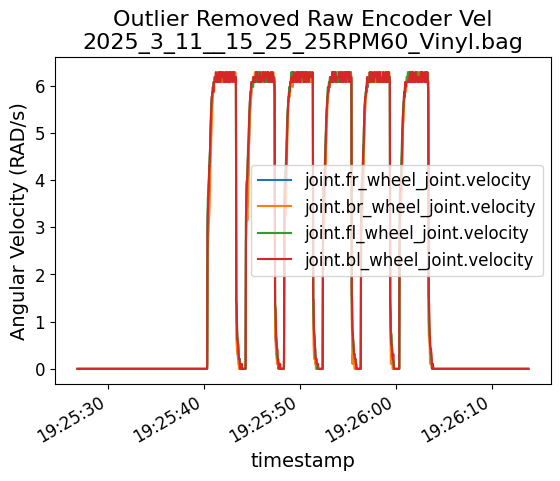

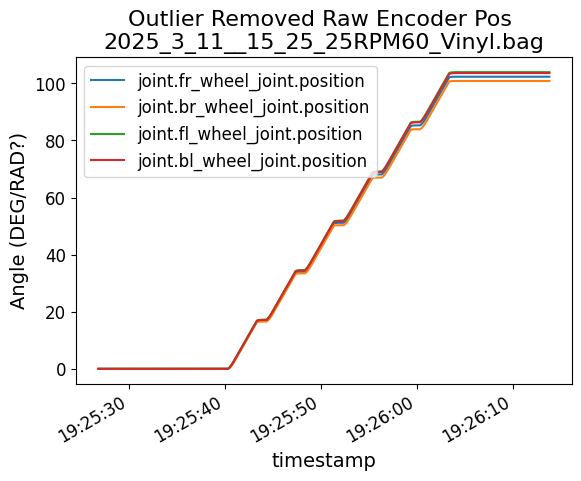

In [41]:
# Remove spikes from built in pos
raw_wheel_vels = results["raw_wheel_vel"][
    [
        "joint.fr_wheel_joint.velocity",
        "joint.br_wheel_joint.velocity",
        "joint.fl_wheel_joint.velocity",
        "joint.bl_wheel_joint.velocity",
    ]
]

cleaned_raw_wheel_vels = remove_outliers(raw_wheel_vels, threshold=1000)
results["cleaned_raw_wheel_vels"] = cleaned_raw_wheel_vels

cleaned_raw_wheel_vels.plot(
    title=f"Outlier Removed Raw Encoder Vel\n{bag_name}",
    ylabel="Angular Velocity (RAD/s)",
    y=[
        "joint.fr_wheel_joint.velocity",
        "joint.br_wheel_joint.velocity",
        "joint.fl_wheel_joint.velocity",
        "joint.bl_wheel_joint.velocity",
    ],
)


raw_wheel_angle = results["raw_wheel_angle"][
    [
        "joint.fr_wheel_joint.position",
        "joint.br_wheel_joint.position",
        "joint.fl_wheel_joint.position",
        "joint.bl_wheel_joint.position",
    ]
]

cleaned_raw_wheel_angle = remove_outliers(
    raw_wheel_angle, threshold=2
)  # Adjust threshold if needed
results["cleaned_raw_wheel_pos"] = cleaned_raw_wheel_angle

cleaned_raw_wheel_angle.plot(
    title=f"Outlier Removed Raw Encoder Pos \n{bag_name}",
    ylabel="Angle (DEG/RAD?)",
    y=[
        "joint.fr_wheel_joint.position",
        "joint.br_wheel_joint.position",
        "joint.fl_wheel_joint.position",
        "joint.bl_wheel_joint.position",
    ],
)

save_all_figures(bag_name=bag_name)

## Make wheel_ang_vel From Encoder Counts
Find the angular wheel speed using numerical diff.

In [42]:
# from scipy.signal import savgol_filter


# def savgol_derivative(
#     df: pd.DataFrame, window_size=21, poly_order=3, derivative_col_names=None
# ) -> pd.DataFrame:
#     """
#     Compute the numerical derivative using Savitzky-Golay filtering on a DataFrame.

#     Parameters:
#         df (pd.DataFrame): DataFrame with timestamps as the index and data columns.
#         window_size (int): Filter window size (must be odd).
#         poly_order (int): Polynomial order (should be < window_size).
#         derivative_col_names (list, optional): List of column names for the derivative DataFrame.

#     Returns:
#         pd.DataFrame: DataFrame containing the computed derivatives with the specified column names.
#     """

#     if not isinstance(df.index, pd.DatetimeIndex):
#         raise ValueError(
#             "DataFrame index must be a DatetimeIndex for time-based differentiation."
#         )

#     # Extract time in seconds from the index
#     time = df.index.astype(np.int64) / 1e9  # Convert nanoseconds to seconds
#     dt = np.mean(np.diff(time))  # Use average timestep to reduce noise

#     # Compute derivatives using Savitzky-Golay filter
#     derivatives = savgol_filter(
#         df.values,
#         window_length=window_size,
#         polyorder=poly_order,
#         deriv=1,
#         delta=dt,
#         axis=0,
#     )

#     # Create new DataFrame with derivatives
#     derivative_df = pd.DataFrame(derivatives, index=df.index)

#     # Assign column names if provided
#     if derivative_col_names:
#         if len(derivative_col_names) != df.shape[1]:
#             raise ValueError(
#                 "Number of derivative column names must match number of data columns."
#             )
#         derivative_df.columns = derivative_col_names
#     else:
#         derivative_df.columns = [
#             f"{col}_derivative" for col in df.columns
#         ]  # Default naming

#     return derivative_df

#     # def quaternion_derivative_savgol(
#     #     quats: NDArray, time: NDArray, window_size=21, poly_order=3
#     # ) -> NDArray:
#     #     """
#     #     Compute the angular velocity from a sequence of quaternions using Savitzky-Golay filtering.

#     #     Parameters:
#     #         quats (NDArray): (4, N) array of quaternions (qx, qy, qz, qw) at each time step.
#     #         time (NDArray): (N,) array of time values corresponding to each quaternion.
#     #         window_size (int): The window length for Savitzky-Golay filtering (must be odd).
#     #         poly_order (int): Polynomial order for Savitzky-Golay filtering.

#     #     Returns:
#     #         NDArray: (3, N) array of angular velocities (wx, wy, wz) in rad/s.
#     #         NDArray: (7, N) array of angular velocities (qx,qy,qz,qw, wx, wy, wz) in rad/s.
#     #     """
#     #     quats = quats.T  # Convert from (4, N) to (N, 4) for scipy.
#     #     print(quats.shape)
#     #     rotations = R.from_quat(quats)

#     #     # Convert quaternion differences to rotation vectors
#     #     rotvecs = np.zeros((len(time), 3))  # (N, 3)
#     #     rotvecs[1:] = (rotations[:-1].inv() * rotations[1:]).as_rotvec()

#     #     # TODO make this not a single scalar constant?
#     #     dt = np.mean(np.diff(time), axis=0)

#     #     # TODO Find optimal way to tune polyorder and window size params to avoid over smoothing/fitting.
#     #     ang_vels = savgol_filter(
#     #         rotvecs.T,
#     #         window_length=window_size,
#     #         polyorder=poly_order,
#     #         deriv=1,
#     #         delta=dt,
#     #         axis=1,
#     #     )

#     #     # Turn euler back to quat?
#     #     quat_vels = R.from_euler("xyz", ang_vels.T).as_quat()
#     #     print("Qual vels", quat_vels.shape)

#     #     ang_vels = np.vstack([ang_vels, quat_vels.T])
#     #     print("Final angles shape", ang_vels.shape)

#     #     return ang_vels  # (7, N)

Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Encoder_Derived_Wheel_Angular_Velocity__2025_3_11__15_25_25RPM60_Vinyl_bag.png


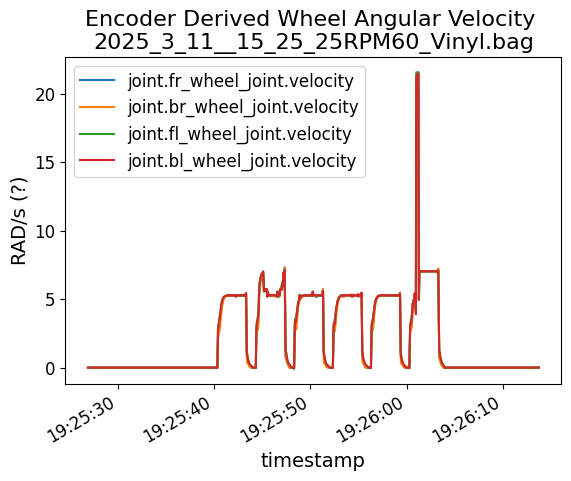

In [43]:
# TODO Use a normal np.gradient derivative here. Minimize smoothing? Or use butter filter for more precise control over it. Maybe just filter afterwards?
wheel_angle_data = results["cleaned_raw_wheel_pos"]
# display(wheel_angle_data)

wheel_angular_vel_data = savgol_derivative(
    wheel_angle_data,
    window_size=5,
    poly_order=4,
    derivative_col_names=[
        "joint.fr_wheel_joint.velocity",
        "joint.br_wheel_joint.velocity",
        "joint.fl_wheel_joint.velocity",
        "joint.bl_wheel_joint.velocity",
    ],
)
results["wheel_angular_vel_deriv"] = wheel_angular_vel_data
# display(wheel_angular_vel_data)
wheel_angular_vel_data.plot(
    title=f"Encoder Derived Wheel Angular Velocity \n{bag_name}", ylabel="RAD/s (?)"
)

results["wheel_angular_vel_deriv"]

save_all_figures(bag_name=bag_name)

## Kinematic Model - VICON_base_ODOM_POSE
Get the body pose in the vicon frame.

### Simple diff drive model

In [44]:
from utils.diff_drive_utils import diff_drive

### Run the Model Using Encoder Data.

In [45]:
# vicon_base_pose = results['vicon_base_pose']
# len(vicon_base_pose)
# wheel_angular_vel_data = results['wheel_angular_vel_data']
# display(wheel_angular_vel_data)
vicon_base_pose = results["VICON_base_TRUE_POSE"]
vicon_base_pose_start = vicon_base_pose.iloc[0]
vicon_base_pose_start["yaw"]

-1.5766695359801934

In [46]:
# display(results["wheel_angular_vel_deriv"])
# display(results["cleaned_raw_wheel_vels"])

Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Odometry_Derived_Kinematic_Robot_Trajectory__Vicon_Frame__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Odometry_Derived_Kinematic_Robot_Trajectory__Vicon_Frame___2025_3_11__15_25_25RPM60_Vinyl_bag.png


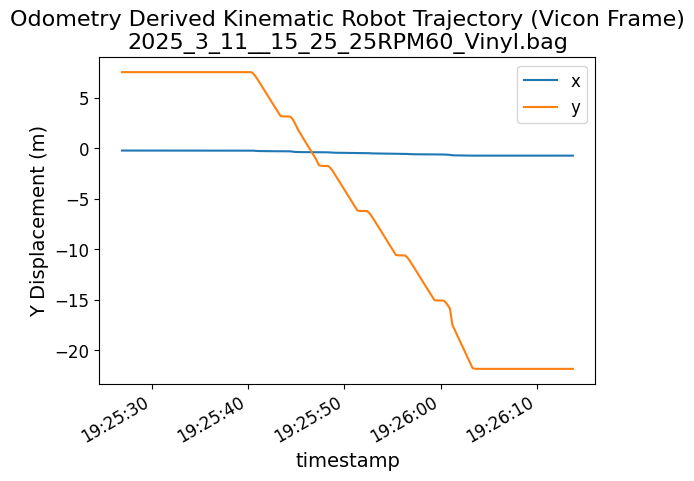

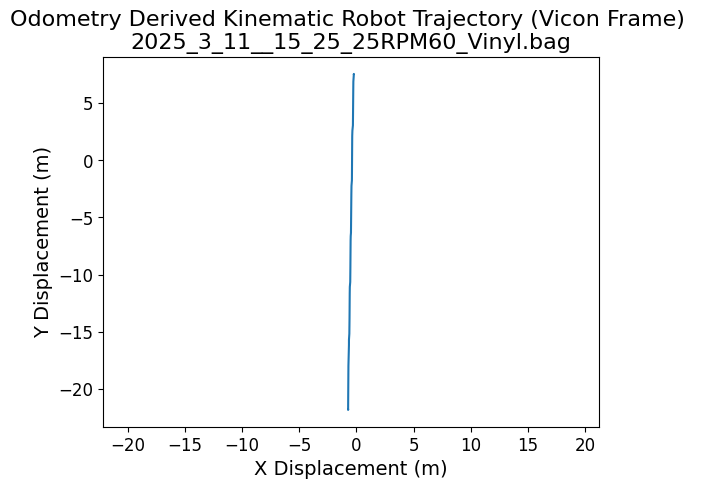

In [47]:
from utils.diff_drive_utils import DiffDriveState

# Load wheel angular velocity data
wheel_angular_vel_data = results["wheel_angular_vel_deriv"]

# Get the initial pose of the body in the vicon frame to start odometry at
vicon_base_pose = results["VICON_base_TRUE_POSE"]
vicon_base_pose_start = vicon_base_pose.iloc[0]
# display(vicon_base_pose_start)
# Define differential drive parameters
diff_drive_params = dict(r=0.29, b=1.56)

# Compute the trajectory using the new model function
body_position = diff_drive(wheel_angular_vel_data, **diff_drive_params)


# Extract initial position & orientation from Vicon
x0 = vicon_base_pose_start["pose.position.x"]
y0 = vicon_base_pose_start["pose.position.y"]
theta0 = vicon_base_pose_start["yaw"]

# Extract computed trajectory
x_body = body_position["x"]
y_body = body_position["y"]

# Apply 2D rotation to transform to the Vicon frame
body_position["x"] = x0 + np.cos(theta0) * x_body - np.sin(theta0) * y_body
body_position["y"] = y0 + np.sin(theta0) * x_body + np.cos(theta0) * y_body

# Apply theta offset
body_position["theta"] += theta0

# Store results
results["VICON_base_ODOM_POSE"] = body_position

# Plot the computed trajectory
body_position.plot(
    y=["x", "y"],
    title=f"Odometry Derived Kinematic Robot Trajectory (Vicon Frame)\n{bag_name}",
    ylabel="Y Displacement (m)",
)

fig, ax = plt.subplots()
ax.set_title(f"Odometry Derived Kinematic Robot Trajectory (Vicon Frame) \n{bag_name}")
ax.set_xlabel("X Displacement (m)")
ax.set_ylabel("Y Displacement (m)")
ax.set_aspect("equal", adjustable="datalim")
ax.plot(body_position.x, body_position.y)

save_all_figures(bag_name=bag_name)

In [48]:
results["cleaned_raw_wheel_vels"].columns
# results["whe"]


Index(['joint.fr_wheel_joint.velocity', 'joint.br_wheel_joint.velocity',
       'joint.fl_wheel_joint.velocity', 'joint.bl_wheel_joint.velocity'],
      dtype='object')

Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Odometry_Derived_Kinematic_Robot_Trajectory__Odom_Frame__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Odometry_Derived_Kinematic_Robot_Trajectory__Odom_Frame__2025_3_11__15_25_25RPM60_Vinyl_bag.png


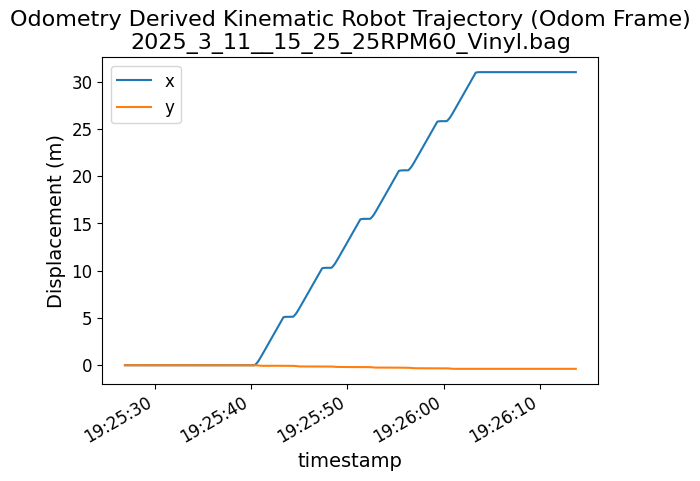

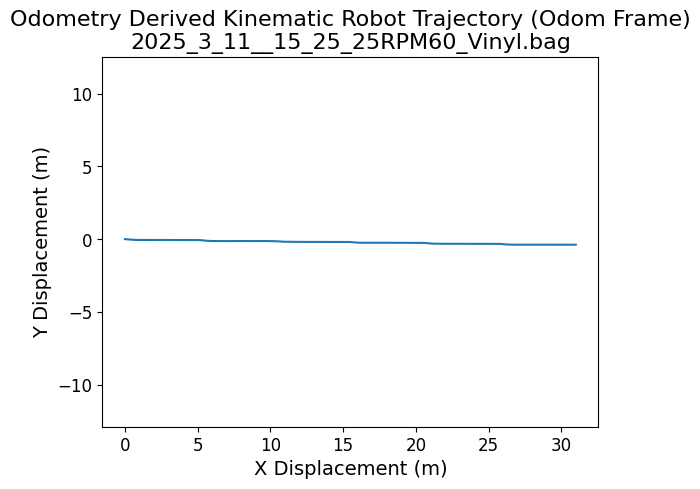

In [49]:
# Do same but for the odom(init pose) frame.

# Load wheel angular velocity data.
wheel_angular_vel_data = results["cleaned_raw_wheel_vels"]  # Roboteq reported

# Get the initial pose of the body in the vicon frame to start odometry at.
vicon_base_pose = results["VICON_base_TRUE_POSE"]
vicon_base_pose_start = vicon_base_pose.iloc[0]
# display(vicon_base_pose_start)
# Define differential drive parameters
diff_drive_params = dict(r=0.29, b=1.56)

# Compute the trajectory using the new model function.
body_position = diff_drive(wheel_angular_vel_data, **diff_drive_params)

# Extract initial position & orientation from Vicon.
x0 = vicon_base_pose_start["pose.position.x"]
y0 = vicon_base_pose_start["pose.position.y"]
theta0 = vicon_base_pose_start["yaw"]

# Extract computed trajectory.
x_body = body_position["x"]
y_body = body_position["y"]

# Apply theta offset.
body_position["theta"] += theta0

# Store results.
results["LOCAL_base_ODOM_POSE"] = body_position

# Plot the computed trajectory.
body_position.plot(
    y=["x", "y"],
    title=f"Odometry Derived Kinematic Robot Trajectory (Odom Frame)\n{bag_name}",
    ylabel="Displacement (m)",
)

fig, ax = plt.subplots()
ax.set_title(f"Odometry Derived Kinematic Robot Trajectory (Odom Frame)\n{bag_name}")
ax.set_xlabel("X Displacement (m)")
ax.set_ylabel("Y Displacement (m)")
ax.set_aspect("equal", adjustable="datalim")
ax.plot(body_position.x, body_position.y)

save_all_figures(bag_name=bag_name)

## Make VICON_base_ODOM_TWIST
Numerically differentiate the odometry poses to get a body Twist in the vicon frame.

<Axes: title={'center': 'Body Velocity Odometry Derived Kinematic Model (Vicon Frame) '}, xlabel='timestamp', ylabel='Velocity (m/s)'>

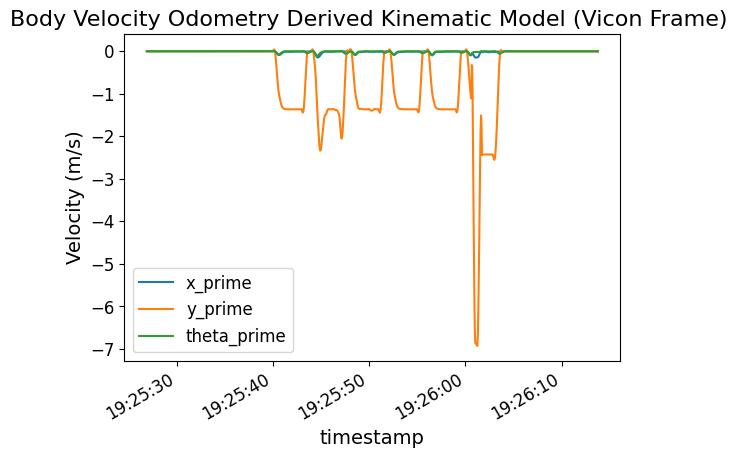

In [50]:
VICON_base_ODOM_POSE = results["VICON_base_ODOM_POSE"]
VICON_base_ODOM_TWIST = savgol_derivative(
    VICON_base_ODOM_POSE, derivative_col_names=["x_prime", "y_prime", "theta_prime"]
)
results["VICON_base_ODOM_TWIST"] = VICON_base_ODOM_TWIST
# display(VICON_base_ODOM_TWIST)

VICON_base_ODOM_TWIST.plot(
    ylabel="Velocity (m/s)",
    title="Body Velocity Odometry Derived Kinematic Model (Vicon Frame) ",
)

## Make LOCAL_base_ODOM_TWIST
Numerical differentiate the odometry poses to get a body Twist in the lcoal (base_link) frame.

Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Body_Velocity_Odometry_Derived_Kinematic_Model__Local_Frame___2025_3_11__15_25_25RPM60_Vinyl_bag.png


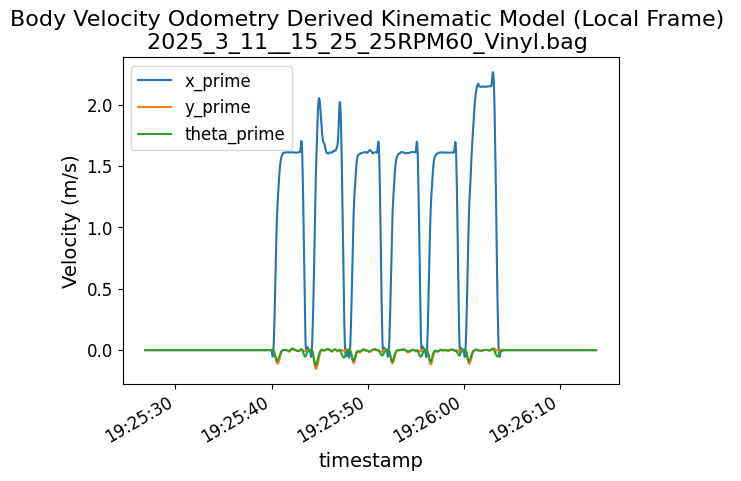

In [51]:
# This is derived from the full kinematic model. Don't use for now.

LOCAL_base_ODOM_POSE = results["LOCAL_base_ODOM_POSE"]
LOCAL_base_ODOM_TWIST = savgol_derivative(
    LOCAL_base_ODOM_POSE, derivative_col_names=["x_prime", "y_prime", "theta_prime"]
)
results["LOCAL_base_ODOM_TWIST"] = LOCAL_base_ODOM_TWIST
# display(VICON_base_ODOM_TWIST)

LOCAL_base_ODOM_TWIST.plot(
    ylabel="Velocity (m/s)",
    title=f"Body Velocity Odometry Derived Kinematic Model (Local Frame) \n{bag_name} ",
)
save_all_figures(bag_name=bag_name)

## Local Frame Odometry Derived Twist
Transform the VICON_base_ODOM_POSE into the local frames of the wheels using our static transforms and PyKDL.

Don't bother doing this until we need lateral slip?

In [52]:
# VICON_base_ODOM_TWIST = results['VICON_base_ODOM_TWIST']
# display(VICON_base_ODOM_TWIST)

# Make *Longitudinal Only* LOCAL_wheel_ODOM_TWIST
We can use just the angular vel for each wheel to find the pure rolling linear velocity expected for each individual wheel. This is only valid (mostly) for longitudinal driving.

$$
V_x(t) = r \omega(t)
$$

Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Wheel_Longitudinal_Velocity_from_Kinematic_Model___V_x___r_omega____Local_Frame__2025_3_11__15_25_25.png


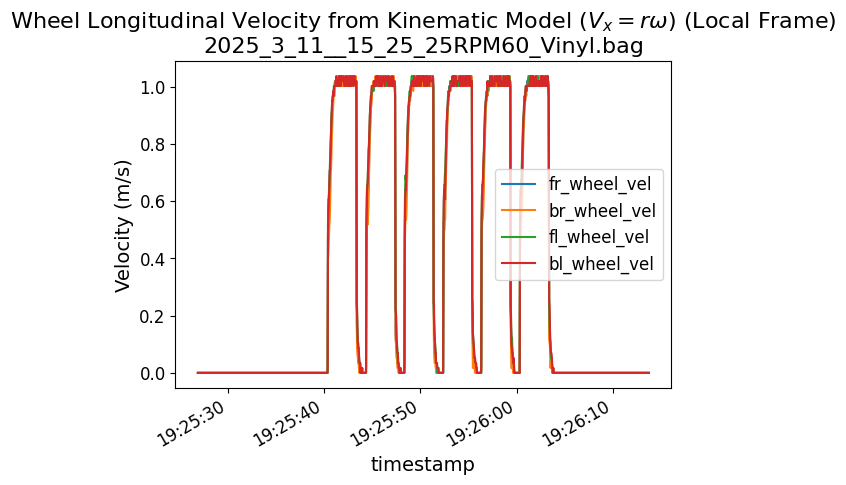

In [53]:
# Have a try with the filtered roboteq reported angular vel.
""" Convert wheel angular velocities from RPM to linear velocity (m/s). """

wheel_angular_vel_data = results["cleaned_raw_wheel_vels"]  # Roboteq reported.
# wheel_angular_vel_data = results['wheel_angular_vel_deriv']  # Numerical deriv using encoder counts

# Convert RPM to rad/s -> (RPM * 2π) / 60
# wheel_angular_vel_data = wheel_angular_vel_data * (2 * np.pi / 60)

r = 0.33 / 2  # Wheel radius in meters

# Compute linear velocity (V = r * ω)
# Assume RAD/s
LOCAL_wheel_longi_ODOM_VEL: pd.DataFrame = (
    r * wheel_angular_vel_data
)  # We aren't using the full kinem model for now.

# Rename columns to match expected format
LOCAL_wheel_longi_ODOM_VEL.rename(
    columns={
        "joint.fr_wheel_joint.velocity": "fr_wheel_vel",
        "joint.br_wheel_joint.velocity": "br_wheel_vel",
        "joint.fl_wheel_joint.velocity": "fl_wheel_vel",
        "joint.bl_wheel_joint.velocity": "bl_wheel_vel",
    },
    inplace=True,
)

# Store results
results["LOCAL_wheel_longi_ODOM_VEL"] = LOCAL_wheel_longi_ODOM_VEL

# Display and plot
# display(LOCAL_wheel_longi_ODOM_VEL)
LOCAL_wheel_longi_ODOM_VEL.plot(
    ylabel="Velocity (m/s)",
    title=f"Wheel Longitudinal Velocity from Kinematic Model ($V_x = r\\omega$) (Local Frame)\n{bag_name}",
)
save_all_figures(bag_name=bag_name)

# Calc Slip-Slope
Do this only during longitudinal driving. Do it in the local frame for each wheel. 



## Maths
$$
    k = \frac{d F_{fr}}{ds}
$$
where $k$ is the longitudinal stiffness, $F_{fr}$ is the friction force and $s$ the slip ratio

We can say that $F_{fr}$ is linearly proportional to the electrical current through the torque-curent relationship and the inverse radius

$$
F_{fr} \propto I
$$

The slip ratio is defined as the difference in expected to actual motion normalized by the larger of the two. There will be a discontinuity at zero.
$$
    s = \frac{\omega r - v}{max(v, \omega r)} \times 100\%
$$

## Calc Slip

Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Motor_Currents__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Longitudinal_Slip__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Wheel_Slip_Ratios__Filtered_for_Movement___2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Wheel_Velocities__Odom_vs_True__Filtered_for_Movement___2025_3_11__15_25_25RPM60_Vinyl_bag.png


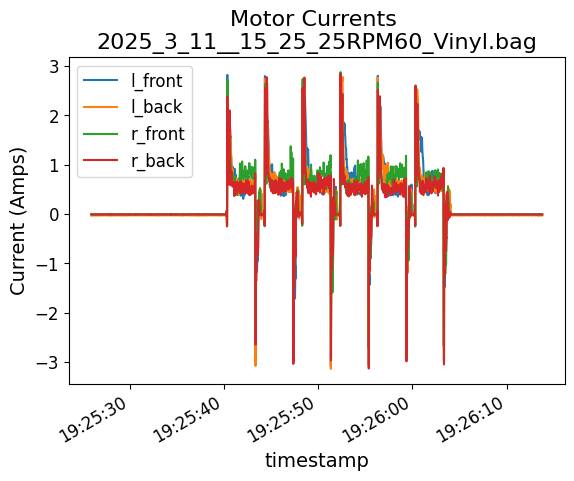

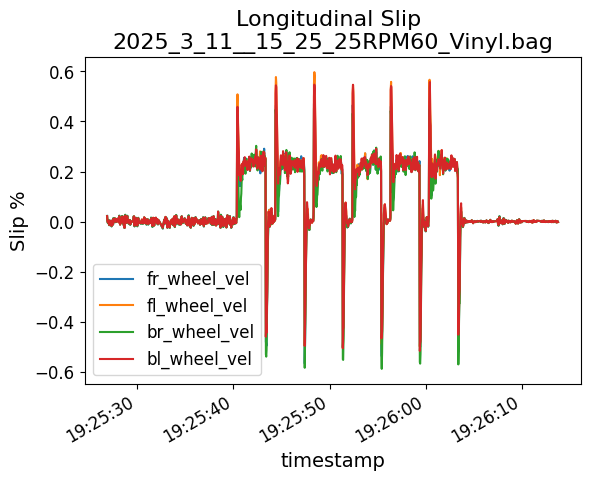

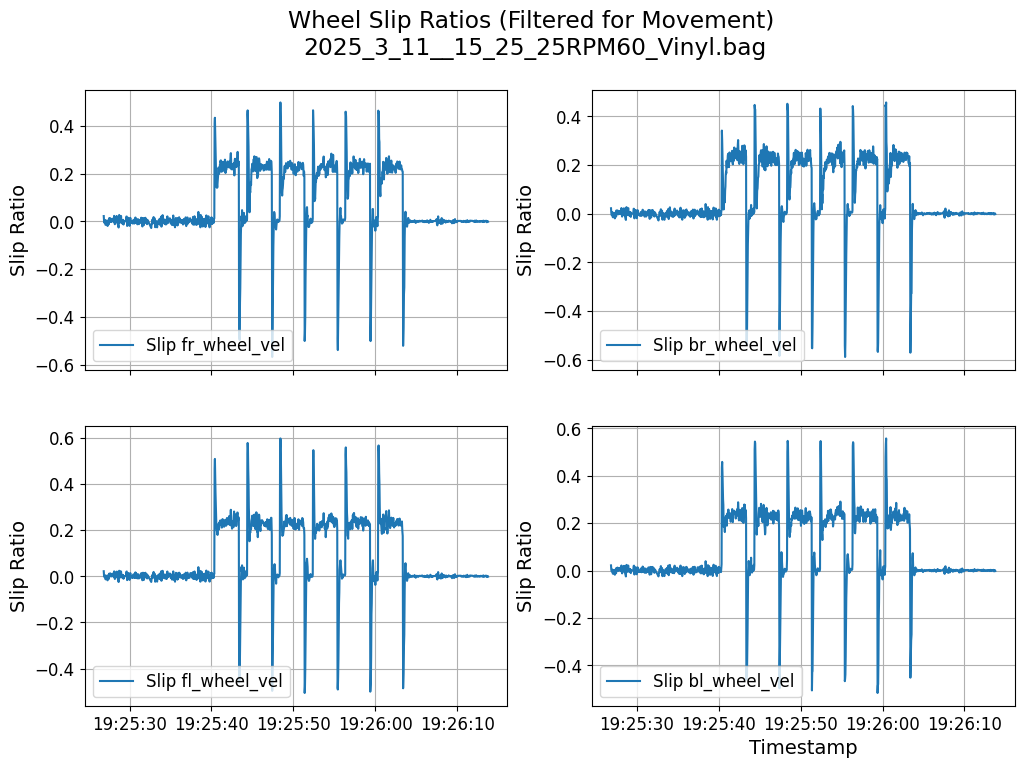

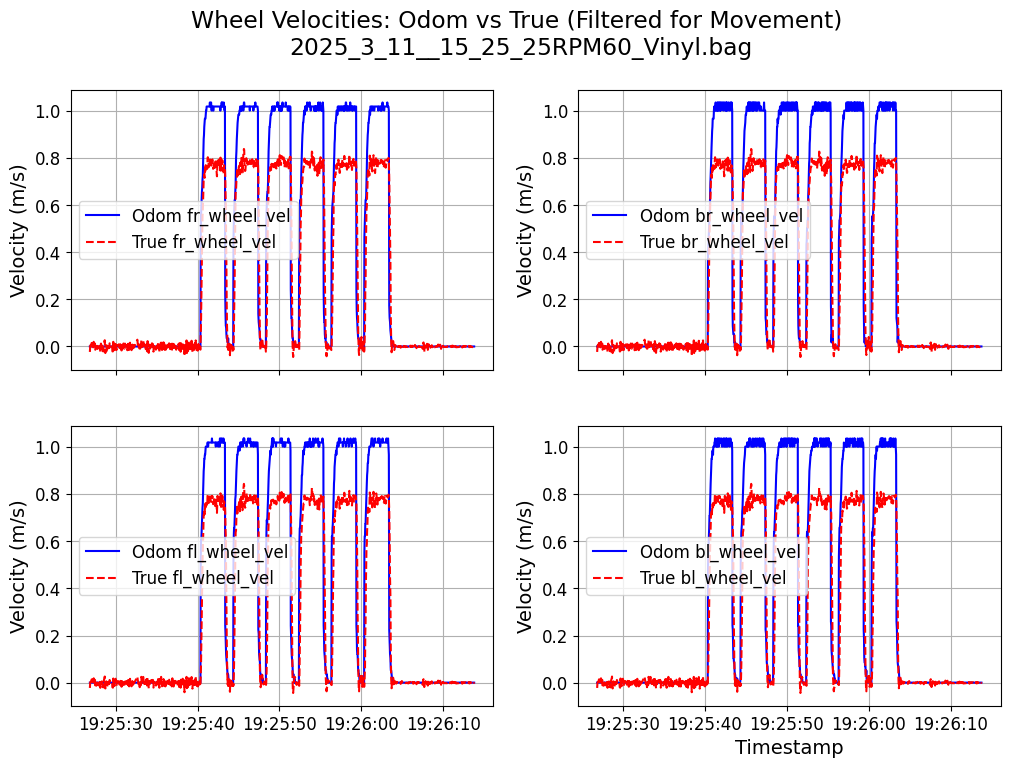

In [54]:
import matplotlib.pyplot as plt
import numpy as np
from pandas.core.interchange.dataframe_protocol import Column
from scipy.interpolate import interp1d

# Data to use
left_currents = results["left_currents"].rename(columns=lambda x: f"l_{x}")
right_currents = results["right_currents"].rename(columns=lambda x: f"r_{x}")
# motor_currents = pd.concat([left_currents, right_currents], axis=1)
motor_currents = pd.merge_asof(
    left_currents.sort_index(),  # Is this okay?
    right_currents.sort_index(),
    left_index=True,
    right_index=True,
)
# display(motor_currents)

motor_currents.plot(
    title=f"Motor Currents \n{bag_name}",
    ylabel="Current (Amps)",
    y=["l_front", "l_back", "r_front", "r_back"],
)


# Local longitudinal only r * omega wheel translation velocity.
# LOCAL_wheel_ODOM_VEL = results['LOCAL_wheel_ODOM_VEL'] # <-- Interpolate to this.
# Roboteq reported raw but cleaned.
LOCAL_wheel_longi_ODOM_VEL = results[
    "LOCAL_wheel_longi_ODOM_VEL"
]  # <-- Interpolate to this.
LOCAL_wheel_longi_ODOM_VEL.rename(
    columns={
        "joint.fr_wheel_joint.velocity": "fr_wheel_vel",
        "joint.br_wheel_joint.velocity": "fl_wheel_vel",
        "joint.fl_wheel_joint.velocity": "br_wheel_vel",
        "joint.bl_wheel_joint.velocity": "bl_wheel_vel",
    },
    inplace=True,
)
# print(LOCAL_wheel_longi_ODOM_VEL.columns)


# Extract TRUE linear x velocity for each wheel and rename columns
local_true_wheel_vels = {
    "fr_wheel_vel": results["LOCAL_fr_tire_TRUTH_TWIST"]["twist.linear.x"],
    "fl_wheel_vel": results["LOCAL_fl_tire_TRUTH_TWIST"]["twist.linear.x"],
    "br_wheel_vel": results["LOCAL_br_tire_TRUTH_TWIST"]["twist.linear.x"],
    "bl_wheel_vel": results["LOCAL_bl_tire_TRUTH_TWIST"]["twist.linear.x"],
}
# Combine into a single DataFrame
LOCAL_wheel_TRUTH_VEL = pd.DataFrame(local_true_wheel_vels)


# print(f"{LOCAL_wheel_longi_ODOM_VEL.columns=}")
# display(LOCAL_wheel_longi_ODOM_VEL)
# print(f"{LOCAL_wheel_TRUTH_VEL.columns=}")
# display(LOCAL_wheel_TRUTH_VEL)

### Align and vicon derived wheel frame vel to odom derived.
TRUTH_aligned_to_ODOM = pd.merge_asof(
    LOCAL_wheel_longi_ODOM_VEL[
        []
    ],  # Only use ODOM timestamps, keep columns empty. Insert NaN.
    LOCAL_wheel_TRUTH_VEL,
    left_index=True,
    right_index=True,
    direction="backward",
)

# print(f"{TRUTH_aligned_to_ODOM.columns=}")
# display(TRUTH_aligned_to_ODOM)

# Just in case there are NaNs
interp_LOCAL_wheel_TRUTH_VEL = TRUTH_aligned_to_ODOM.interpolate(
    method="linear", limit_direction="both"
)

# Display the final interpolated TRUTH DataFrame
# print(f"{interp_LOCAL_wheel_TRUTH_VEL.columns=}")
# display(interp_LOCAL_wheel_TRUTH_VEL)

# Find our slip.
slip_x = (LOCAL_wheel_longi_ODOM_VEL - interp_LOCAL_wheel_TRUTH_VEL) / np.max(
    [LOCAL_wheel_longi_ODOM_VEL, interp_LOCAL_wheel_TRUTH_VEL]
)

# **Plot slip ratio**
slip_x.plot(
    title=f"Longitudinal Slip \n{bag_name}",
    ylabel="Slip %",
    y=["fr_wheel_vel", "fl_wheel_vel", "br_wheel_vel", "bl_wheel_vel"],
)

# Plot each wheel's slip separately
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
fig.suptitle(f"Wheel Slip Ratios (Filtered for Movement) \n{bag_name}")

wheel_labels = ["fr_wheel_vel", "br_wheel_vel", "fl_wheel_vel", "bl_wheel_vel"]
for ax, wheel in zip(axes.flatten(), wheel_labels):
    ax.plot(slip_x.index, slip_x[wheel], label=f"Slip {wheel}", linestyle="-")

    # Plot offset line
    # ax.axhline(delta[wheel], color='r', linestyle='--', label=f"Offset {wheel}")

    ax.set_ylabel("Slip Ratio")
    ax.legend()
    ax.grid(True)

plt.xlabel("Timestamp")


# Plot each wheel's odometry velocity and true velocity on the same plot
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
fig.suptitle(f"Wheel Velocities: Odom vs True (Filtered for Movement) \n{bag_name}")

for ax, wheel in zip(axes.flatten(), LOCAL_wheel_longi_ODOM_VEL.columns):
    ax.plot(
        LOCAL_wheel_longi_ODOM_VEL.index,
        LOCAL_wheel_longi_ODOM_VEL[wheel],
        label=f"Odom {wheel}",
        linestyle="-",
        color="blue",
    )
    ax.plot(
        interp_LOCAL_wheel_TRUTH_VEL.index,
        interp_LOCAL_wheel_TRUTH_VEL[wheel],
        label=f"True {wheel}",
        linestyle="--",
        color="red",
    )
    ax.set_ylabel("Velocity (m/s)")
    ax.legend()
    ax.grid(True)

plt.xlabel("Timestamp")

# Plot slip, LOCAL_wheel_longi_ODOM_VEL, and interp_LOCAL_wheel_TRUTH_VEL on same plot.

save_all_figures(bag_name)

## Remove $\delta$
Calculate the average slip during motion and remove it to unbias.
Kind of a pseudo velocity based delta

Slip offsets (delta) for each wheel:
bl_wheel_vel    0.194563
br_wheel_vel    0.175180
fl_wheel_vel    0.197212
fr_wheel_vel    0.185945
dtype: float64
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Motor_Currents__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Longitudinal_Wheel_Slip_Ratios__For__V_x____epsilon_0_1_m_s___2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Longitudinal_Slip__2025_3_11__15_25_25RPM60_Vinyl_bag.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Wheel_Velocities__Odom_vs_True__Filtered_for_Movement___2025_3_11__15_25_25RPM60_Vinyl_bag.png


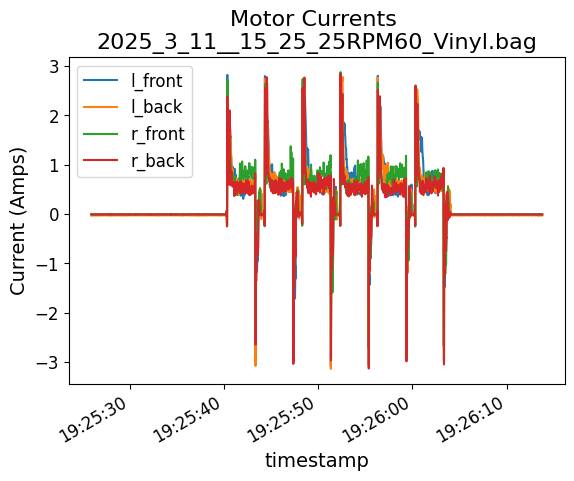

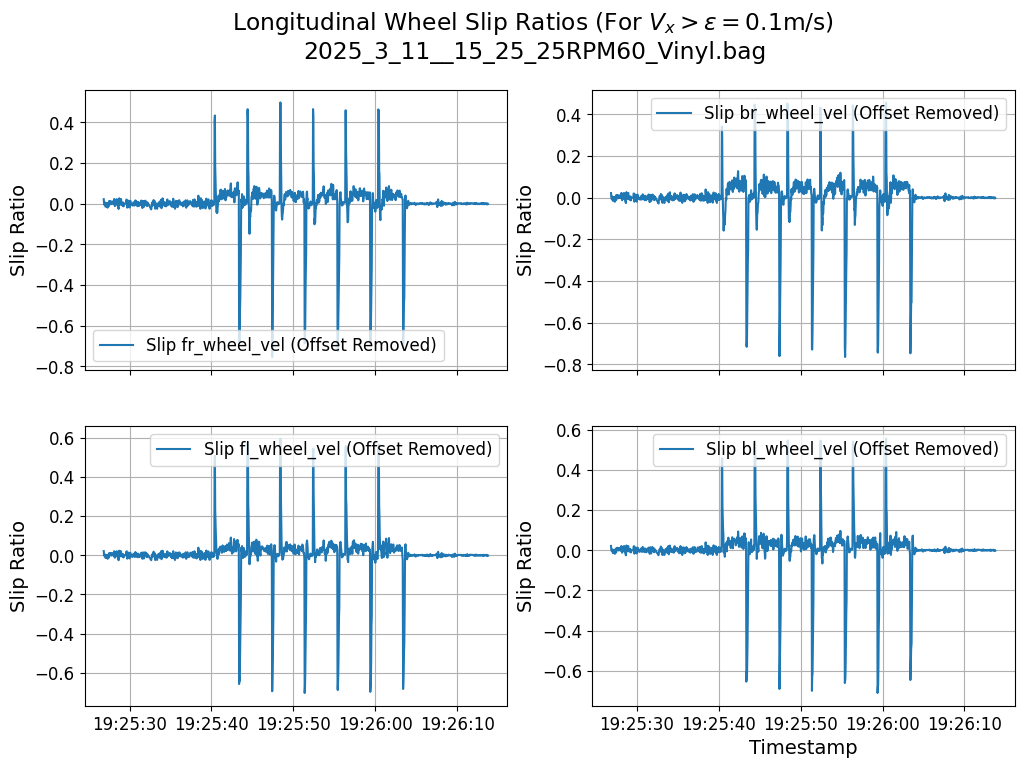

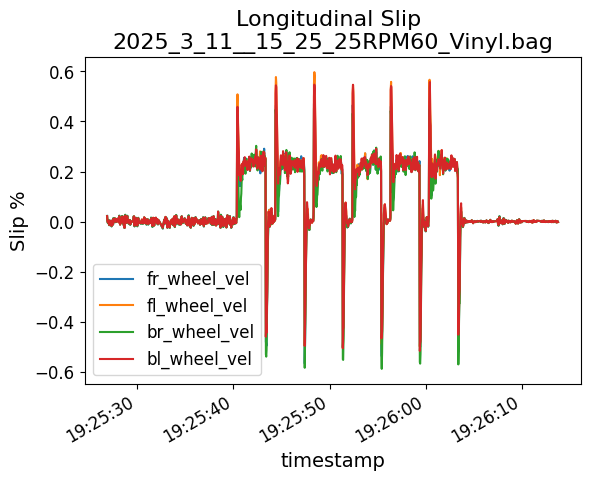

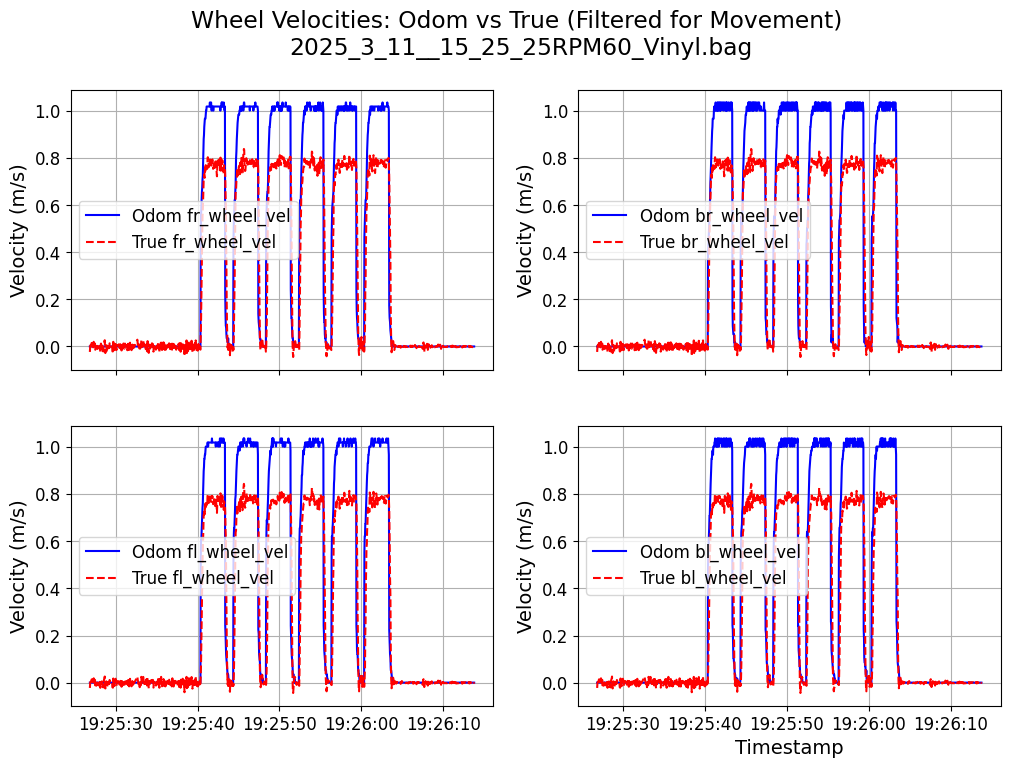

In [55]:
# Threshold for considering movement
velocity_threshold = 0.1

# Data to use
left_currents = results["left_currents"].rename(columns=lambda x: f"l_{x}")
right_currents = results["right_currents"].rename(columns=lambda x: f"r_{x}")
# motor_currents = pd.concat([left_currents, right_currents], axis=1)
motor_currents = pd.merge_asof(
    left_currents.sort_index(),  # Is this okay?
    right_currents.sort_index(),
    left_index=True,
    right_index=True,
)
# display(motor_currents)

motor_currents.plot(
    title=f"Motor Currents \n{bag_name}",
    ylabel="Current (Amps)",
    y=["l_front", "l_back", "r_front", "r_back"],
)

results["combined_currents"] = motor_currents

# Local longitudinal only r * omega wheel translation velocity.
# LOCAL_wheel_ODOM_VEL = results['LOCAL_wheel_ODOM_VEL'] # <-- Interpolate to this.
# Roboteq reported raw but cleaned.
LOCAL_wheel_longi_ODOM_VEL = results[
    "LOCAL_wheel_longi_ODOM_VEL"
]  # <-- Interpolate to this.
LOCAL_wheel_longi_ODOM_VEL.rename(
    columns={
        "joint.fr_wheel_joint.velocity": "fr_wheel_vel",
        "joint.br_wheel_joint.velocity": "fl_wheel_vel",
        "joint.fl_wheel_joint.velocity": "br_wheel_vel",
        "joint.bl_wheel_joint.velocity": "bl_wheel_vel",
    },
    inplace=True,
)
# print(LOCAL_wheel_longi_ODOM_VEL.columns)


# Extract TRUE linear x velocity for each wheel and rename columns
local_true_wheel_vels = {
    "fr_wheel_vel": results["LOCAL_fr_tire_TRUTH_TWIST"]["twist.linear.x"],
    "fl_wheel_vel": results["LOCAL_fl_tire_TRUTH_TWIST"]["twist.linear.x"],
    "br_wheel_vel": results["LOCAL_br_tire_TRUTH_TWIST"]["twist.linear.x"],
    "bl_wheel_vel": results["LOCAL_bl_tire_TRUTH_TWIST"]["twist.linear.x"],
}
# Combine into a single DataFrame
LOCAL_wheel_TRUTH_VEL = pd.DataFrame(local_true_wheel_vels)


# print(f"{LOCAL_wheel_longi_ODOM_VEL.columns=}")
# display(LOCAL_wheel_longi_ODOM_VEL)
# print(f"{LOCAL_wheel_TRUTH_VEL.columns=}")
# display(LOCAL_wheel_TRUTH_VEL)

### Align and vicon derived wheel frame vel to odom derived.
TRUTH_aligned_to_ODOM = pd.merge_asof(
    LOCAL_wheel_longi_ODOM_VEL[
        []
    ],  # Only use ODOM timestamps, keep columns empty. Insert NaN.
    LOCAL_wheel_TRUTH_VEL,
    left_index=True,
    right_index=True,
    direction="backward",
)

# print(f"{TRUTH_aligned_to_ODOM.columns=}")
# display(TRUTH_aligned_to_ODOM)

# Just in case there are NaNs
interp_LOCAL_wheel_TRUTH_VEL = TRUTH_aligned_to_ODOM.interpolate(
    method="linear", limit_direction="both"
)

# Display the final interpolated TRUTH DataFrame
# print(f"{interp_LOCAL_wheel_TRUTH_VEL.columns=}")
# display(interp_LOCAL_wheel_TRUTH_VEL)


# Find our slip.
slip_x = (LOCAL_wheel_longi_ODOM_VEL - interp_LOCAL_wheel_TRUTH_VEL) / np.max(
    [LOCAL_wheel_longi_ODOM_VEL, interp_LOCAL_wheel_TRUTH_VEL]
)


# Use only times where robots is moving.
vicon_velocity = results["LOCAL_marker_TRUE_TWIST"]["twist.linear.x"]
vicon_velocity = vicon_velocity.reindex(
    interp_LOCAL_wheel_TRUTH_VEL.index, method="nearest"
)

moving_mask = abs(vicon_velocity) > velocity_threshold
filtered_slip_x = slip_x.copy()
filtered_slip_x[~moving_mask] = 0


# Compute slip offset (mean slip when moving)
delta = slip_x[moving_mask].mean(skipna=True)
print(f"Slip offsets (delta) for each wheel:\n{delta}")

# Create adjusted slip dataframe
slip_x_adjusted = slip_x.copy()

# Apply delta correction *only in the moving region*
slip_x_adjusted[moving_mask] -= delta

results["slip_x_adjusted"] = slip_x_adjusted


# Plot each wheel's slip separately (delta Removed Only in Moving Region)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
fig.suptitle(
    f"Longitudinal Wheel Slip Ratios (For $V_x > \\epsilon={velocity_threshold}$m/s) \n{bag_name}"
)

wheel_labels = ["fr_wheel_vel", "br_wheel_vel", "fl_wheel_vel", "bl_wheel_vel"]
for ax, wheel in zip(axes.flatten(), wheel_labels):
    ax.plot(
        slip_x_adjusted.index,
        slip_x_adjusted[wheel],
        label=f"Slip {wheel} (Offset Removed)",
        linestyle="-",
    )

    # Plot zero reference line
    # ax.axhline(0, color='r', linestyle='--', label="Zero Slip")

    ax.set_ylabel("Slip Ratio")
    ax.legend()
    ax.grid(True)

plt.xlabel("Timestamp")


# **Plot slip ratio**
slip_x.plot(
    title=f"Longitudinal Slip \n{bag_name}",
    ylabel="Slip %",
    y=["fr_wheel_vel", "fl_wheel_vel", "br_wheel_vel", "bl_wheel_vel"],
)

# Plot each wheel's odometry velocity and true velocity on the same plot
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
fig.suptitle(f"Wheel Velocities: Odom vs True (Filtered for Movement) \n{bag_name}")

for ax, wheel in zip(axes.flatten(), LOCAL_wheel_longi_ODOM_VEL.columns):
    ax.plot(
        LOCAL_wheel_longi_ODOM_VEL.index,
        LOCAL_wheel_longi_ODOM_VEL[wheel],
        label=f"Odom {wheel}",
        linestyle="-",
        color="blue",
    )
    ax.plot(
        interp_LOCAL_wheel_TRUTH_VEL.index,
        interp_LOCAL_wheel_TRUTH_VEL[wheel],
        label=f"True {wheel}",
        linestyle="--",
        color="red",
    )
    ax.set_ylabel("Velocity (m/s)")
    ax.legend()
    ax.grid(True)

external_plotter_2.add_plot(ax=ax,row=3,col=0)

plt.xlabel("Timestamp")

# Plot slip, LOCAL_wheel_longi_ODOM_VEL, and interp_LOCAL_wheel_TRUTH_VEL on same plot.

save_all_figures(bag_name)


## More accurate Delta
base on current=0

timestamp
2025-03-11 19:25:26.852219820     True
2025-03-11 19:25:26.888219833    False
2025-03-11 19:25:26.924315691    False
2025-03-11 19:25:26.960262060    False
2025-03-11 19:25:26.996293545    False
                                 ...  
2025-03-11 19:26:13.601863623    False
2025-03-11 19:26:13.640916824    False
2025-03-11 19:26:13.682996273    False
2025-03-11 19:26:13.724913836    False
2025-03-11 19:26:13.764040947    False
Length: 1172, dtype: bool
Slip offsets (delta) for each wheel:
bl_wheel_vel    0.478261
br_wheel_vel    0.391304
fl_wheel_vel    0.478261
fr_wheel_vel    0.391304
dtype: float64


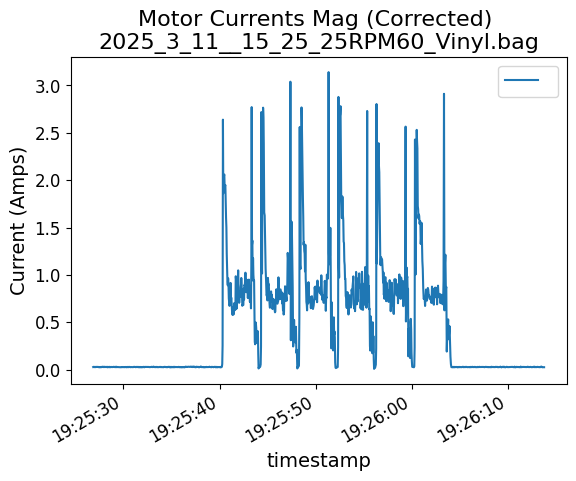

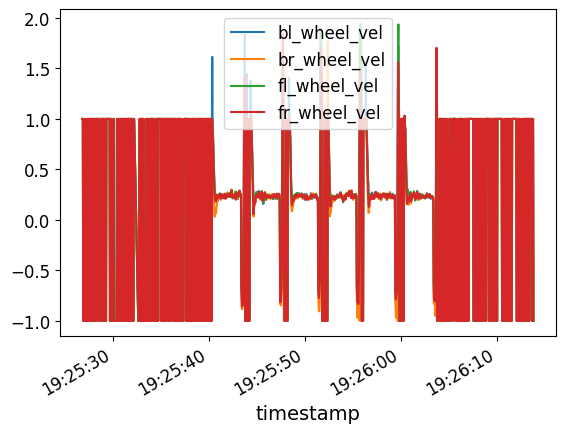

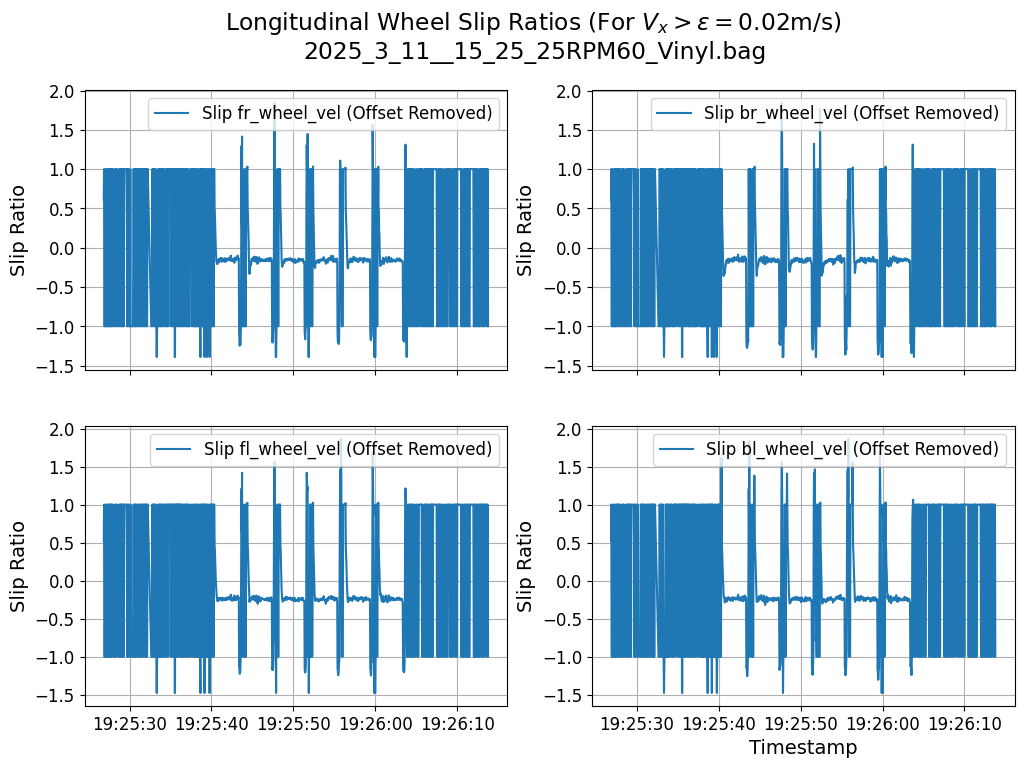

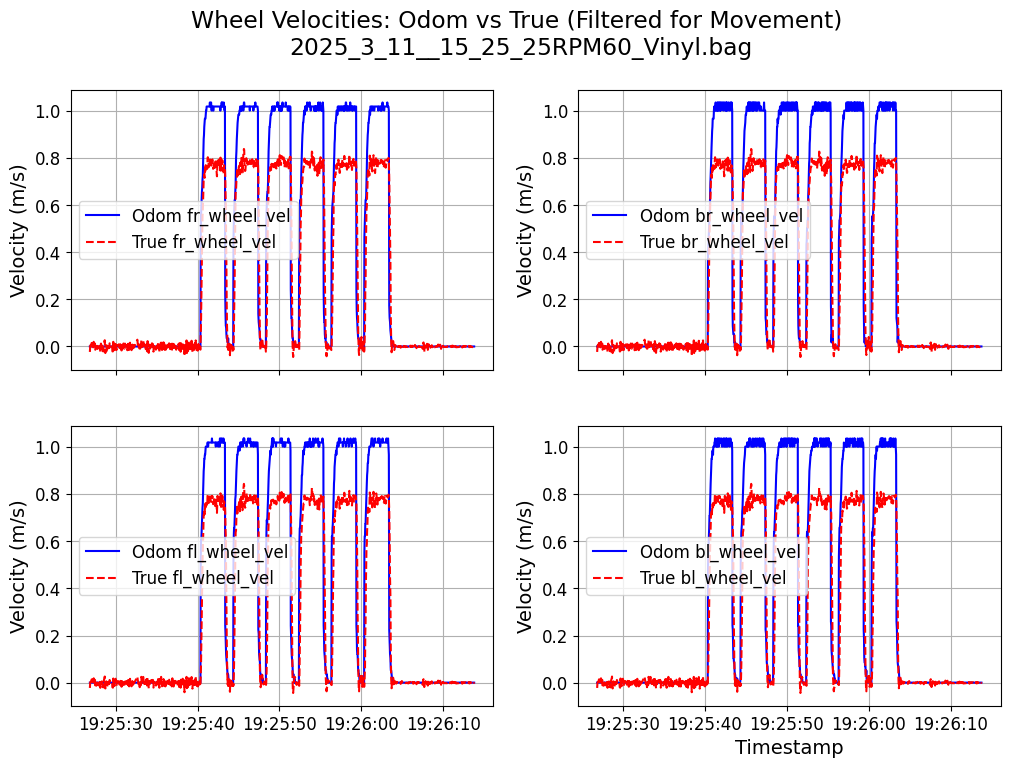

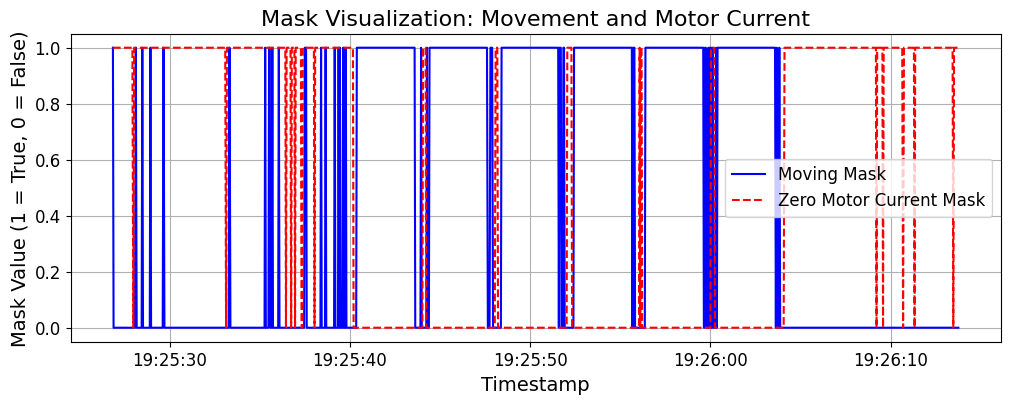

Total slip_x_adjusted points: 1172
Valid moving points: 554 (out of 1172)


In [56]:
# Threshold for considering movement
velocity_threshold = 0.02
mu_threshold = .03  # Consider motor current as zero below this threshol

# Data to use
left_currents = results["left_currents"].rename(columns=lambda x: f"l_{x}")
right_currents = results["right_currents"].rename(columns=lambda x: f"r_{x}")

# Merge and interpolate the two motor currents into one DF.
motor_currents = pd.merge_asof(
    left_currents.sort_index(),  # Is this okay?
    right_currents.sort_index(),
    left_index=True,
    right_index=True,
)
# display(motor_currents)

# motor_currents.plot(
#     title=f"Motor Currents \n{bag_name}",
#     ylabel="Current (Amps)",
#     y=["l_front", "l_back", "r_front", "r_back"],
# )







# Local longitudinal only r * omega wheel translation velocity.
# LOCAL_wheel_ODOM_VEL = results['LOCAL_wheel_ODOM_VEL'] # <-- Interpolate to this.
# Roboteq reported raw but cleaned.
LOCAL_wheel_longi_ODOM_VEL = results[
    "LOCAL_wheel_longi_ODOM_VEL"
]  # <-- Interpolate to this.
LOCAL_wheel_longi_ODOM_VEL.rename(
    columns={
        "joint.fr_wheel_joint.velocity": "fr_wheel_vel",
        "joint.br_wheel_joint.velocity": "fl_wheel_vel",
        "joint.fl_wheel_joint.velocity": "br_wheel_vel",
        "joint.bl_wheel_joint.velocity": "bl_wheel_vel",
    },
    inplace=True,
)
# print(LOCAL_wheel_longi_ODOM_VEL.columns)


# Extract TRUE linear x velocity for each wheel and rename columns
local_true_wheel_vels = {
    "fr_wheel_vel": results["LOCAL_fr_tire_TRUTH_TWIST"]["twist.linear.x"],
    "fl_wheel_vel": results["LOCAL_fl_tire_TRUTH_TWIST"]["twist.linear.x"],
    "br_wheel_vel": results["LOCAL_br_tire_TRUTH_TWIST"]["twist.linear.x"],
    "bl_wheel_vel": results["LOCAL_bl_tire_TRUTH_TWIST"]["twist.linear.x"],
}
# Combine into a single DataFrame
LOCAL_wheel_TRUTH_VEL = pd.DataFrame(local_true_wheel_vels)


# print(f"{LOCAL_wheel_longi_ODOM_VEL.columns=}")
# display(LOCAL_wheel_longi_ODOM_VEL)
# print(f"{LOCAL_wheel_TRUTH_VEL.columns=}")
# display(LOCAL_wheel_TRUTH_VEL)

### Align and vicon derived wheel frame vel to odom derived.
TRUTH_aligned_to_ODOM = pd.merge_asof(
    LOCAL_wheel_longi_ODOM_VEL[
        []
    ],  # Only use ODOM timestamps, keep columns empty. Insert NaN.
    LOCAL_wheel_TRUTH_VEL,
    left_index=True,
    right_index=True,
    direction="backward",
)

# print(f"{TRUTH_aligned_to_ODOM.columns=}")
# display(TRUTH_aligned_to_ODOM)

# Just in case there are NaNs
interp_LOCAL_wheel_TRUTH_VEL = TRUTH_aligned_to_ODOM.interpolate(
    method="linear", limit_direction="both"
)



# Align motor currents with LOCAL_wheel_longi_ODOM_VEL
# Remove extra cols.
# results["combined_currents"] = motor_currents[["l_front", "l_back", "r_front", "r_back"]]
motor_currents= motor_currents[["l_front", "l_back", "r_front", "r_back"]]

# Interpolate motor currents to match odometry timestamps
# interp_motor_currents = motor_currents.reindex(
#     LOCAL_wheel_longi_ODOM_VEL.index, method="nearest"
# )
interp_motor_currents = pd.merge_asof(
    LOCAL_wheel_longi_ODOM_VEL[
        []
    ],  # Only use ODOM timestamps, keep columns empty. Insert NaN.
    motor_currents,
    left_index=True,
    right_index=True,
    direction="backward",
)

# interp_motor_currents.plot(
#     title=f"Motor Currents \n{bag_name}",
#     ylabel="Current (Amps)",
#     y=["l_front", "l_back", "r_front", "r_back"],
# )

# Store interpolated currents
results["interp_motor_currents"] = interp_motor_currents

# Extract total motor currents after interpolation
# motor_current_magnitude = interp_motor_currents.abs().max(axis=1)  # Max absolute current per timestamp



# motor_current_magnitude = np.abs(interp_motor_currents)
motor_current_magnitude = np.abs(interp_motor_currents).max(axis=1)
# Re-check that we are taking the absolute max
motor_current_magnitude = interp_motor_currents.abs().max(axis=1)

# Plot the corrected motor current magnitude
motor_current_magnitude.plot(
    title=f"Motor Currents Mag (Corrected) \n{bag_name}",
    ylabel="Current (Amps)",
    legend=True
)



# Find our slip.
slip_x = (LOCAL_wheel_longi_ODOM_VEL - interp_LOCAL_wheel_TRUTH_VEL) / LOCAL_wheel_longi_ODOM_VEL.abs().combine(
    interp_LOCAL_wheel_TRUTH_VEL.abs(), np.maximum
)
slip_x.plot()


# Use only times where robot is moving.
vicon_velocity = results["LOCAL_marker_TRUE_TWIST"]["twist.linear.x"]
vicon_velocity = vicon_velocity.reindex(interp_LOCAL_wheel_TRUTH_VEL.index, method="nearest")
moving_mask = abs(vicon_velocity) >= velocity_threshold

# Use interpolated motor currents to refine mask
zero_mu_mask = motor_current_magnitude < mu_threshold  # Select times where current ≈ 0
valid_mask = moving_mask & zero_mu_mask  # Ensure movement and zero current condition

print(valid_mask)

# plt.plot((np.ones(zero_mu_mask.shape)






# Compute slip offset (mean slip when moving & motor current ≈ 0)
delta = slip_x[valid_mask].mean(skipna=True)
print(f"Slip offsets (delta) for each wheel:\n{delta}")


# Create adjusted slip dataframe
slip_x_adjusted = slip_x.copy()

# Apply delta correction *only in the moving region*
slip_x_adjusted[moving_mask] -= delta

results["slip_x_adjusted"] = slip_x_adjusted


# Plot each wheel's slip separately (delta Removed Only in Moving Region)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
fig.suptitle(
    f"Longitudinal Wheel Slip Ratios (For $V_x > \\epsilon={velocity_threshold}$m/s) \n{bag_name}"
)

wheel_labels = ["fr_wheel_vel", "br_wheel_vel", "fl_wheel_vel", "bl_wheel_vel"]
for ax, wheel in zip(axes.flatten(), wheel_labels):
    ax.plot(
        slip_x_adjusted.index,
        slip_x_adjusted[wheel],
        label=f"Slip {wheel} (Offset Removed)",
        linestyle="-",
    )

    # Plot zero reference line
    # ax.axhline(0, color='r', linestyle='--', label="Zero Slip")

    ax.set_ylabel("Slip Ratio")
    ax.legend()
    ax.grid(True)

plt.xlabel("Timestamp")


# # **Plot slip ratio**
# slip_x.plot(
#     title=f"Longitudinal Slip \n{bag_name}",
#     ylabel="Slip %",
#     y=["fr_wheel_vel", "fl_wheel_vel", "br_wheel_vel", "bl_wheel_vel"],
# )

# Plot each wheel's odometry velocity and true velocity on the same plot
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
fig.suptitle(f"Wheel Velocities: Odom vs True (Filtered for Movement) \n{bag_name}")

for ax, wheel in zip(axes.flatten(), LOCAL_wheel_longi_ODOM_VEL.columns):
    ax.plot(
        LOCAL_wheel_longi_ODOM_VEL.index,
        LOCAL_wheel_longi_ODOM_VEL[wheel],
        label=f"Odom {wheel}",
        linestyle="-",
        color="blue",
    )
    ax.plot(
        interp_LOCAL_wheel_TRUTH_VEL.index,
        interp_LOCAL_wheel_TRUTH_VEL[wheel],
        label=f"True {wheel}",
        linestyle="--",
        color="red",
    )
    ax.set_ylabel("Velocity (m/s)")
    ax.legend()
    ax.grid(True)

external_plotter_2.add_plot(ax=ax,row=3,col=0)

plt.xlabel("Timestamp")

# Plot slip, LOCAL_wheel_longi_ODOM_VEL, and interp_LOCAL_wheel_TRUTH_VEL on same plot.




# Plot the two masks: moving_mask and zero_mu_mask
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(moving_mask.index, moving_mask.astype(int), label="Moving Mask", linestyle="-", color="blue")
ax.plot(zero_mu_mask.index, zero_mu_mask.astype(int), label="Zero Motor Current Mask", linestyle="--", color="red")

ax.set_ylabel("Mask Value (1 = True, 0 = False)")
ax.set_title("Mask Visualization: Movement and Motor Current")
ax.legend()
ax.grid(True)

plt.xlabel("Timestamp")
plt.show()








save_all_figures(bag_name)

print(f"Total slip_x_adjusted points: {len(slip_x_adjusted)}")
print(f"Valid moving points: {moving_mask.sum()} (out of {len(moving_mask)})")



### Remove proper delta


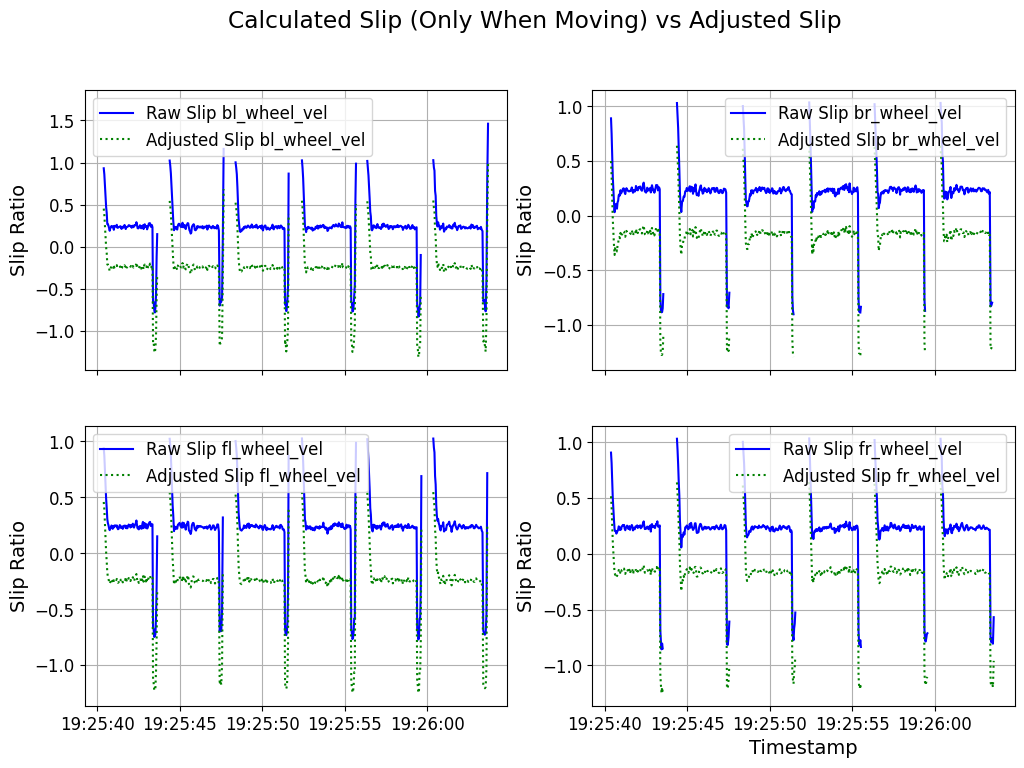

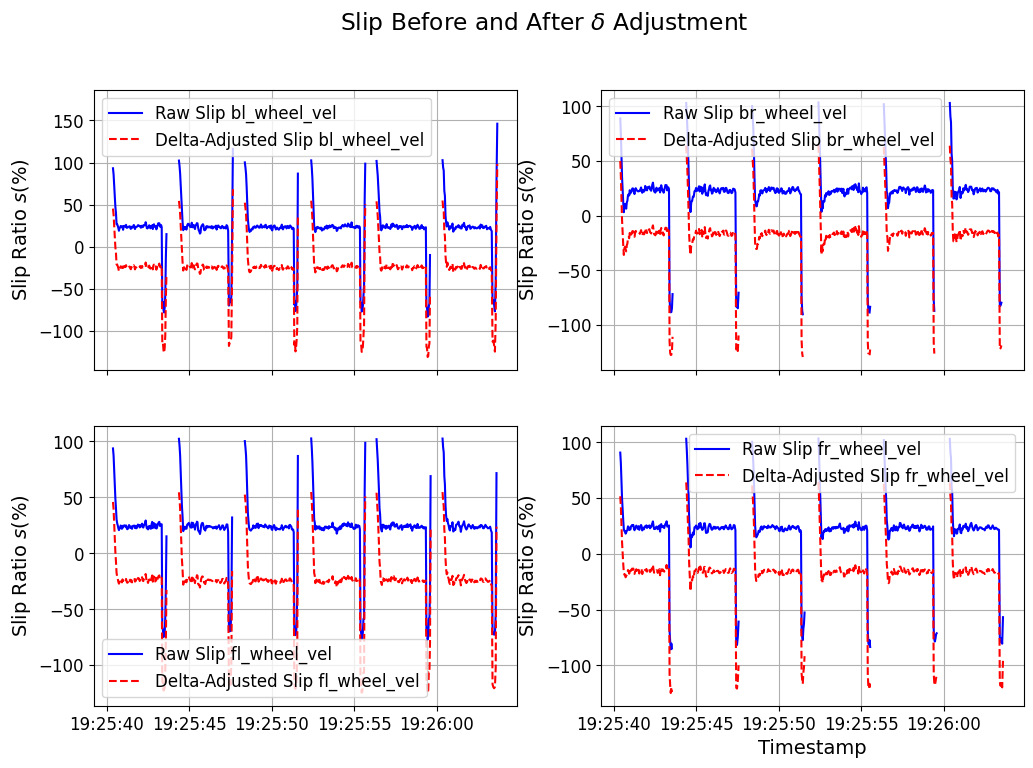

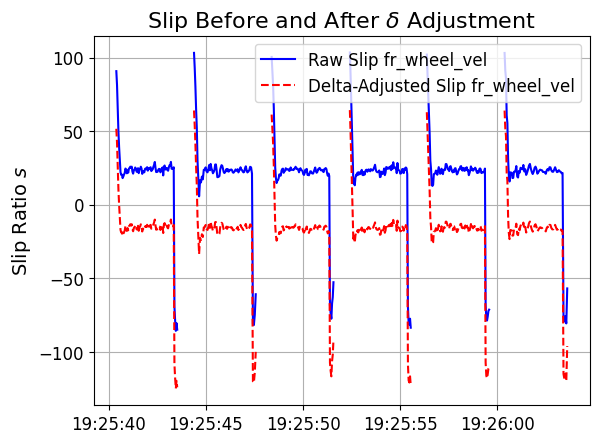

In [57]:
# Define the velocity threshold for considering movement
slip_velocity_threshold = 0.05  # Modify as needed

# Mask for times where the wheel velocity is above the threshold
valid_slip_mask = LOCAL_wheel_longi_ODOM_VEL.abs() > slip_velocity_threshold

# Calculate slip only in valid regions
slip_x_calculated = (LOCAL_wheel_longi_ODOM_VEL - interp_LOCAL_wheel_TRUTH_VEL) / LOCAL_wheel_longi_ODOM_VEL.abs().combine(
    interp_LOCAL_wheel_TRUTH_VEL.abs(), np.maximum
)

# Apply the mask to retain only valid slip values
slip_x_valid = slip_x_calculated.copy()
slip_x_valid[~valid_slip_mask] = np.nan  # Set values to NaN where movement is below the threshold

# Subtract delta to refine the slip calculation
slip_x_final = slip_x_valid.copy()
slip_x_final -= delta

# Store the final slip values
results["slip_x_final"] = slip_x_final

# Plot the slip before and after adjustment
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
fig.suptitle("Calculated Slip (Only When Moving) vs Adjusted Slip")

for ax, wheel in zip(axes.flatten(), slip_x_final.columns):
    ax.plot(slip_x_valid.index, slip_x_valid[wheel], label=f"Raw Slip {wheel}", linestyle="-", color="blue")
    ax.plot(slip_x_final.index, slip_x_final[wheel], label=f"Adjusted Slip {wheel}", linestyle=":", color="green")

    ax.set_ylabel("Slip Ratio")
    ax.legend()
    ax.grid(True)

plt.xlabel("Timestamp")
plt.show()

# Plot both the raw slip and delta-adjusted slip
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
fig.suptitle("Slip Before and After $\\delta$ Adjustment")

for ax, wheel in zip(axes.flatten(), slip_x_final.columns):
    ax.plot(slip_x_valid.index, 100*slip_x_valid[wheel], label=f"Raw Slip {wheel}", linestyle="-", color="blue")
    ax.plot(slip_x_final.index, 100*slip_x_final[wheel], label=f"Delta-Adjusted Slip {wheel}", linestyle="--", color="red")

    ax.set_ylabel("Slip Ratio $s$(%)")
    ax.legend()
    ax.grid(True)

plt.xlabel("Timestamp")
plt.show()

fig,ax = plt.subplots()
ax.plot(slip_x_valid.index, 100*slip_x_valid[wheel], label=f"Raw Slip {wheel}", linestyle="-", color="blue")
ax.plot(slip_x_final.index, 100*slip_x_final[wheel], label=f"Delta-Adjusted Slip {wheel}", linestyle="--", color="red")
ax.set_title("Slip Before and After $\\delta$ Adjustment")
ax.set_ylabel("Slip Ratio $s$")
ax.legend()
ax.grid(True)


Odom offsets (delta) for each wheel (computed where |Odom| > 0.1 m/s):
bl_wheel_vel    0.219260
br_wheel_vel    0.217682
fl_wheel_vel    0.219101
fr_wheel_vel    0.213606
dtype: float64
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Wheel_Velocities__Odom__Offset_Removed__vs_True__2025_3_11__15_25_25RPM60_Vinyl_bag.png


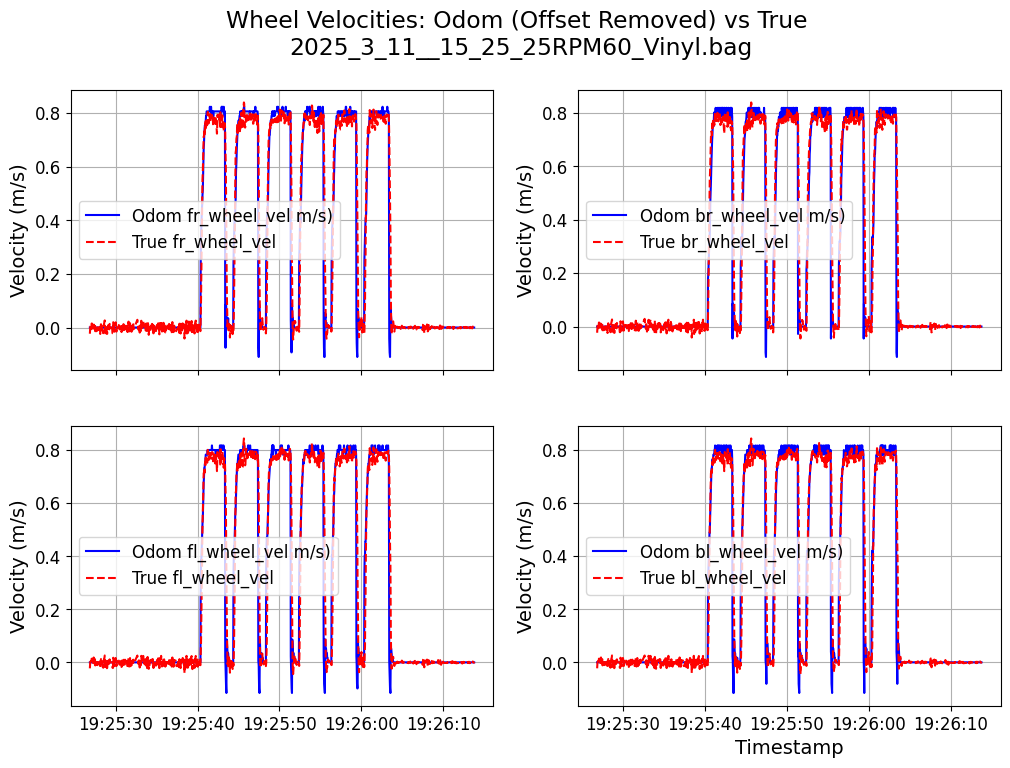

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set threshold for odometry velocity to be considered for delta calculation
odom_velocity_threshold = 0.1  # Change as needed

# Compute mask for valid odometry regions (where odom is above the threshold)
odom_valid_mask = LOCAL_wheel_longi_ODOM_VEL.abs() > odom_velocity_threshold

# Compute the mean offset (delta) between odometry and truth where odom is valid
odom_delta = (LOCAL_wheel_longi_ODOM_VEL - interp_LOCAL_wheel_TRUTH_VEL)[odom_valid_mask].mean(skipna=True)
print(f"Odom offsets (delta) for each wheel (computed where |Odom| > {odom_velocity_threshold} m/s):\n{odom_delta}")

# Adjust odometry values (removing systemic offset only in valid regions)
odom_vel_adjusted = LOCAL_wheel_longi_ODOM_VEL.copy()
odom_vel_adjusted[odom_valid_mask] -= odom_delta  # Apply correction only where odom was moving

# Plot each wheel's odometry velocity and true velocity on the same plot
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
fig.suptitle(f"Wheel Velocities: Odom (Offset Removed) vs True \n{bag_name}")

for ax, wheel in zip(axes.flatten(), LOCAL_wheel_longi_ODOM_VEL.columns):
    ax.plot(
        odom_vel_adjusted.index,
        odom_vel_adjusted[wheel],
        label=f"Odom {wheel} m/s)",
        linestyle="-",
        color="blue",
    )
    ax.plot(
        interp_LOCAL_wheel_TRUTH_VEL.index,
        interp_LOCAL_wheel_TRUTH_VEL[wheel],
        label=f"True {wheel}",
        linestyle="--",
        color="red",
    )
    ax.set_ylabel("Velocity (m/s)")
    ax.legend()
    ax.grid(True)

plt.xlabel("Timestamp")

save_all_figures(bag_name)


<!-- # Old
## Wheel Poses in Vicon Frame
Use the static base_link->{fr,bl,br,fl}_wheel transforms to get their global vicon poses as well. -->


# Slip Slope
Plot delta adjusted slip values.

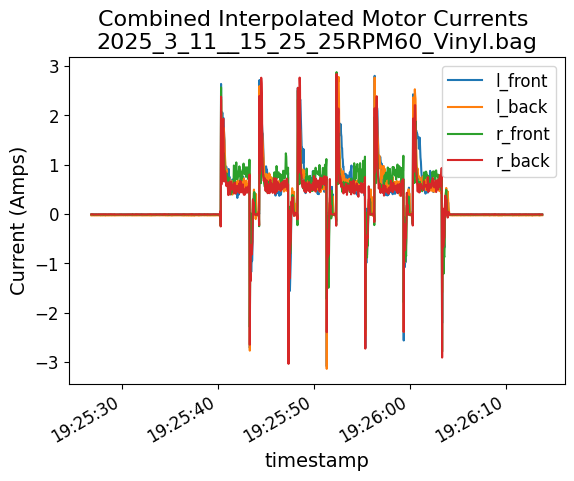

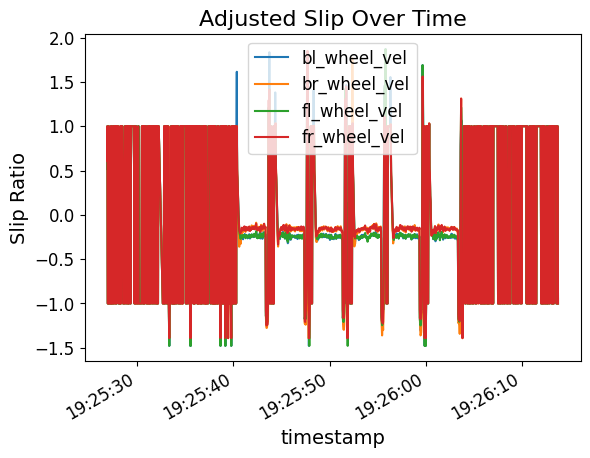

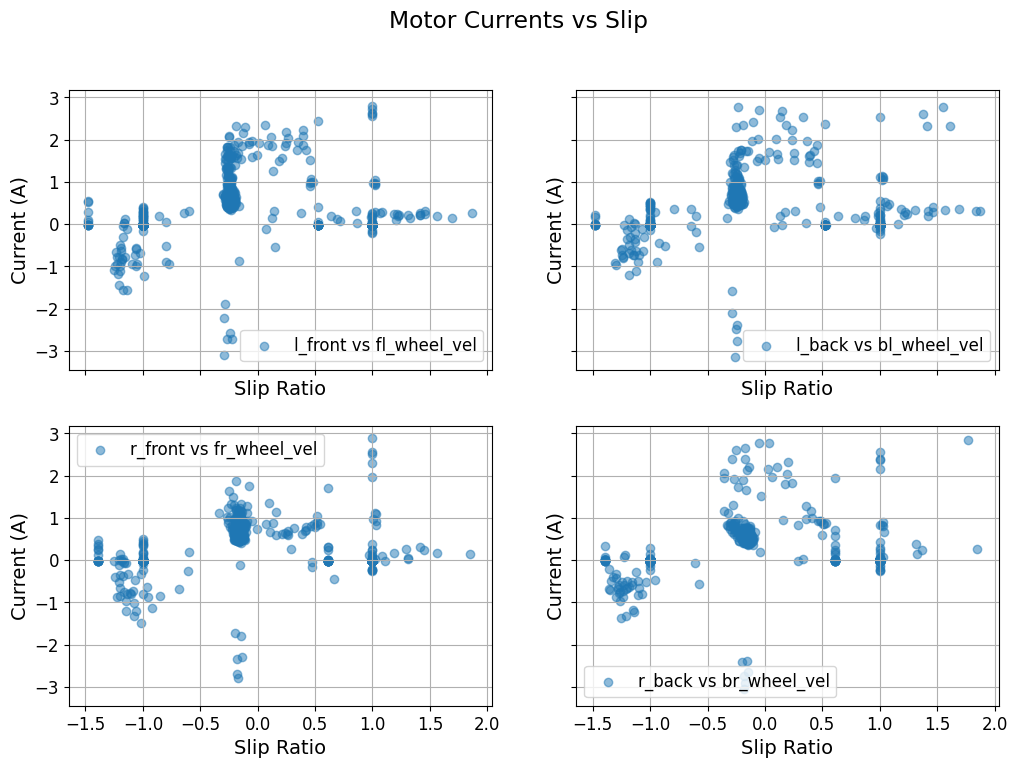

In [59]:
# Extract slip data
slip_x_adjusted = results["slip_x_adjusted"]
# Get aligned motor current data.
combined_currents = results["combined_currents"]

combined_currents_interp = pd.merge_asof(
    slip_x_adjusted[[]],  # Only use ODOM timestamps, keep columns empty. Insert NaN.
    combined_currents,
    left_index=True,
    right_index=True,
    direction="backward",
)
results["combined_currents_interp"] = combined_currents_interp

p = combined_currents_interp.plot(
    title=f"Combined Interpolated Motor Currents \n{bag_name}",
    ylabel="Current (Amps)",
    y=["l_front", "l_back", "r_front", "r_back"],
)
external_plotter_2.add_plot(ax=p, row=2,col=0)
# Ensure slip has no zeros to avoid division errors
safe_slip_x = slip_x_adjusted.replace(0, np.nan)

# display(slip_x_adjusted)
p = slip_x_adjusted.plot(title="Adjusted Slip Over Time", ylabel="Slip Ratio")
external_plotter_2.add_plot(ax=p, row=2,col=1)

# Scatter plot of slip vs. motor currents
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
fig.suptitle("Motor Currents vs Slip")

# Correctly match motors with their respective wheels
motor_wheel_pairs = {
    "l_front": "fl_wheel_vel",
    "l_back": "bl_wheel_vel",
    "r_front": "fr_wheel_vel",
    "r_back": "br_wheel_vel",
}

for ax, (motor, wheel) in zip(axes.flatten(), motor_wheel_pairs.items()):
    ax.scatter(
        safe_slip_x[wheel],
        combined_currents_interp[motor],
        alpha=0.5,
        label=f"{motor} vs {wheel}",
    )

    ax.set_xlabel("Slip Ratio")
    ax.set_ylabel("Current (A)")
    ax.legend()
    ax.grid(True)

# plt.show()


Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Subset_Slip_Over_Time__Vinyl.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Motor_Currents_vs_Slip_with_Best-Fit_Lines__Vinyl.png
Saved: figures/2025_3_11__15_25_25RPM60_Vinyl.bag/Average_Motor_Currents_vs_Slip_with_Best-Fit_Line__Vinyl.png


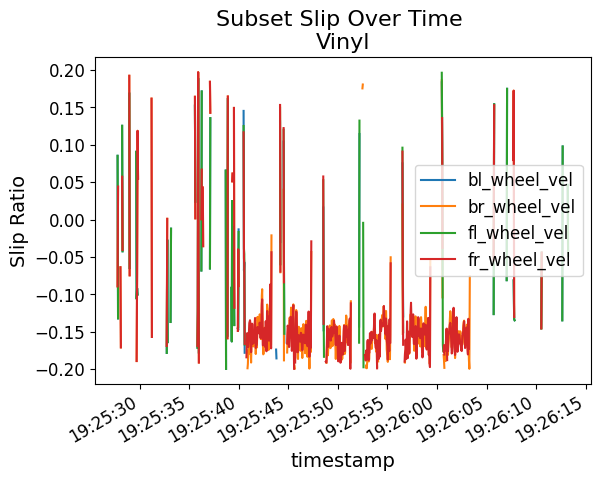

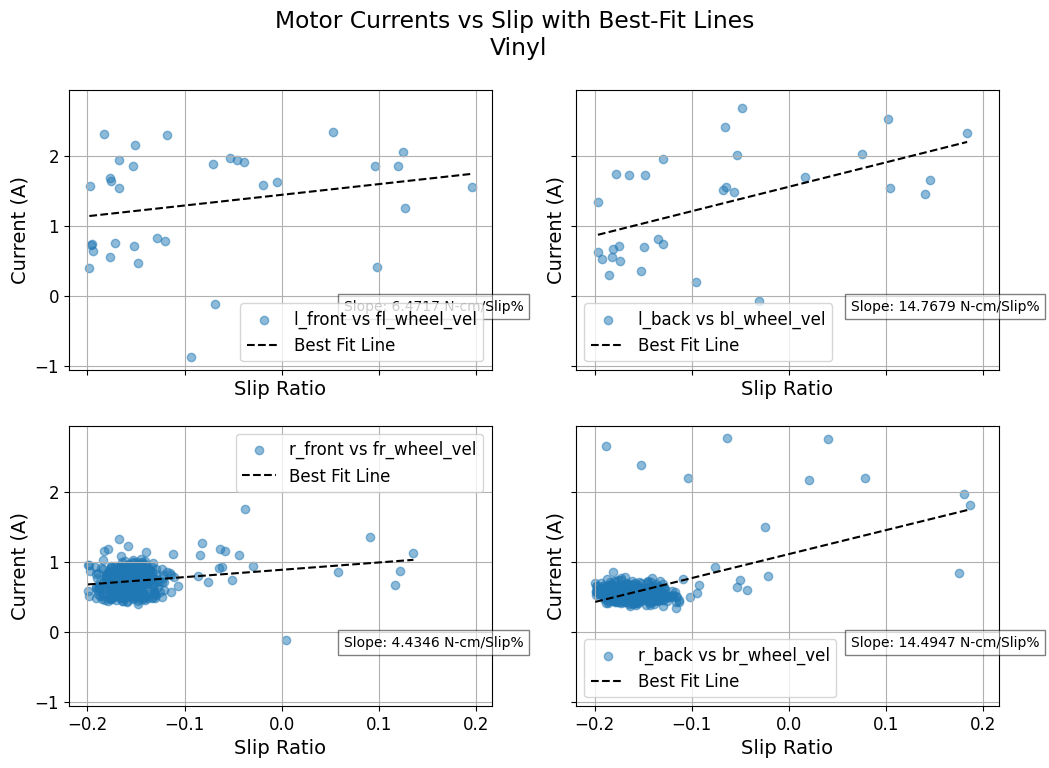

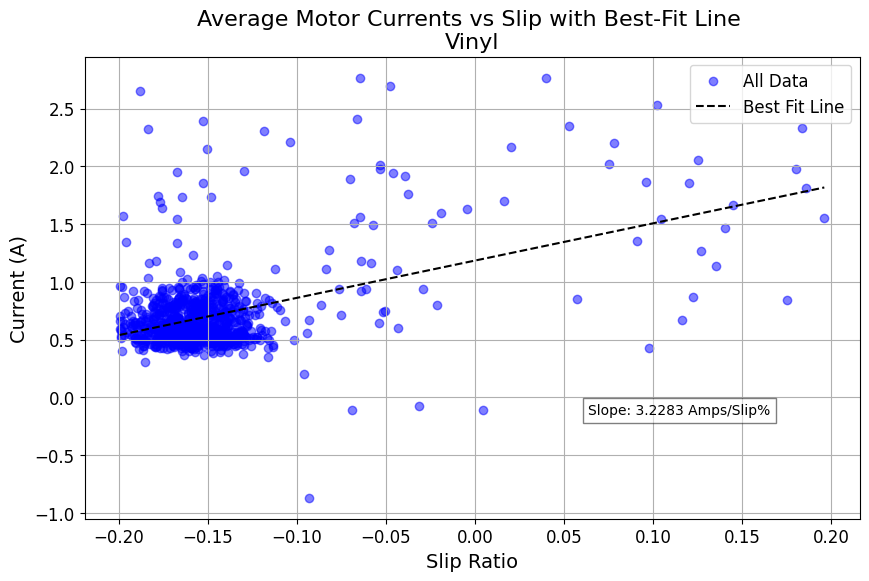

In [63]:
from scipy.stats import linregress

results[f"{SURFACE_TYPE}_per_wheel_data"] = {}
results[f"{SURFACE_TYPE}_combined_data"] = {}


# Extract slip data
slip_x_adjusted = filter_dataframe(results["slip_x_adjusted"],
    columns_to_filter= ['bl_wheel_vel','fl_wheel_vel', 'br_wheel_vel', 'fr_wheel_vel'],
    cutoff=10, fs=30, order=4)

combined_currents_interp = results["combined_currents_interp"]

min_slip_threshold = 0.00
max_slip_threshold = 0.2

min_current_threshold = 0.05

# Keep only values within the valid slip range
slip_x_adjusted = slip_x_adjusted[
    (slip_x_adjusted.abs() >= min_slip_threshold)
    & (slip_x_adjusted.abs() <= max_slip_threshold)
]


# Ensure slip has no zeros to avoid division errors
safe_slip_x = slip_x_adjusted.replace(0, np.nan)

slip_x_adjusted.plot(title=f"Subset Slip Over Time \n{SURFACE_TYPE}", ylabel="Slip Ratio")


fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
fig.suptitle(f"Motor Currents vs Slip with Best-Fit Lines \n{SURFACE_TYPE}")

# Correctly match motors with their respective wheels
motor_wheel_pairs = {
    "l_front": "fl_wheel_vel",
    "l_back": "bl_wheel_vel",
    "r_front": "fr_wheel_vel",
    "r_back": "br_wheel_vel",
}

# Find per-wheel slip-slope.
for ax, (motor, wheel) in zip(axes.flatten(), motor_wheel_pairs.items()):
    # Get valid non-NaN values for regression
    # valid_mask = ~np.isnan(safe_slip_x[wheel]) & ~np.isnan(
    #     combined_currents_interp[motor]
    # )

    valid_mask = (
    ~np.isnan(safe_slip_x[wheel])
    & ~np.isnan(combined_currents_interp[motor])
    & (np.abs(combined_currents_interp[motor]) >= min_current_threshold)
    )

    slip_valid = safe_slip_x[wheel][valid_mask]
    current_valid = combined_currents_interp[motor][valid_mask]

    # Save per wheel data to results
    results[f"{SURFACE_TYPE}_per_wheel_data"][f"{motor}"] = pd.DataFrame({
        "slip": slip_valid.values,
        "current": current_valid.values
    })


    if len(slip_valid) > 1:  # Ensure enough points for regression
        # Compute linear regression (best-fit line)
        slope, intercept, _, _, _ = linregress(slip_valid, current_valid)

        # Generate regression line points
        slip_fit = np.linspace(slip_valid.min(), slip_valid.max(), 100)
        current_fit = slope * slip_fit + intercept

        # Scatter plot
        ax.scatter(slip_valid, current_valid, alpha=0.5, label=f"{motor} vs {wheel}")

        # Best-fit line
        ax.plot(
            slip_fit, current_fit, linestyle="--", color="black", label="Best Fit Line"
        )
        slope *= 4.23 # Make N-cm
        # Add text box for slope value
        textstr = f"Slope: {slope:.4f} N-cm/Slip%"
        ax.text(
            0.65,
            0.25,
            textstr,
            transform=ax.transAxes,
            fontsize=10,
            verticalalignment="top",
            bbox=dict(facecolor="white", alpha=0.5),
        )

    ax.set_xlabel("Slip Ratio")
    ax.set_ylabel("Current (A)")
    ax.legend()
    ax.grid(True)




# k = mu/slip
# mu = k * s
# 433.3g=cm/A
# So replace slope units with 
# 4.24 N-cm


# Aggregate all data.
combined_slip = []
combined_current = []

for motor, wheel in motor_wheel_pairs.items():
    # valid_mask = ~np.isnan(safe_slip_x[wheel]) & ~np.isnan(
    #     combined_currents_interp[motor]
    # )

    valid_mask = (
    ~np.isnan(safe_slip_x[wheel])
    & ~np.isnan(combined_currents_interp[motor])
    & (np.abs(combined_currents_interp[motor]) >= min_current_threshold)
    )

    combined_slip.extend(safe_slip_x[wheel][valid_mask])
    combined_current.extend(combined_currents_interp[motor][valid_mask])

# Only convert to NumPy arrays AFTER aggregation
combined_slip = np.array(combined_slip)
combined_current = np.array(combined_current)



# Compute single regression for all wheels.
if len(combined_slip) > 1:
    slope, intercept, _, _, _ = linregress(combined_slip, combined_current)
    slip_fit = np.linspace(combined_slip.min(), combined_slip.max(), 100)
    current_fit = slope * slip_fit + intercept

    # **Step 4: Plot combined results**
    plt.figure(figsize=(10, 6))
    plt.scatter(
        combined_slip, combined_current, alpha=0.5, label="All Data", color="blue"
    )
    plt.plot(
        slip_fit, current_fit, linestyle="--", color="black", label="Best Fit Line"
    )
    # slope *= 4.23 # Make N-cm
    # Add text box for slope value
    textstr = f"Slope: {slope:.4f} Amps/Slip%"
    plt.text(
        0.65,
        0.25,
        textstr,
        transform=plt.gca().transAxes,
        fontsize=10,
        verticalalignment="top",
        bbox=dict(facecolor="white", alpha=0.5),
    )

    plt.xlabel("Slip Ratio")
    plt.ylabel("Current (A)")
    plt.title(f"Average Motor Currents vs Slip with Best-Fit Line \n{SURFACE_TYPE}")
    plt.legend()
    plt.grid(True)


# Save combined aggregated data
results[f"{SURFACE_TYPE}_combined_data"]["slip"] = combined_slip
results[f"{SURFACE_TYPE}_combined_data"]["current"] = combined_current

save_all_figures(bag_name=bag_name)


In [61]:
# import numpy as np
# import matplotlib.pyplot as plt
# # %matplotlib qt

# # Extract the filtered slip and current data
# slip_x_adjusted = filter_dataframe(
#     results["slip_x_adjusted"],
#     columns_to_filter=['bl_wheel_vel', 'fl_wheel_vel', 'br_wheel_vel', 'fr_wheel_vel'],
#     cutoff=10, fs=30, order=4
# )

# combined_currents_interp = results["combined_currents_interp"]

# # Thresholds for filtering data
# min_slip_threshold = 0.00
# max_slip_threshold = 0.2
# min_current_threshold = 0.05

# # Keep only values within the valid slip range
# slip_x_adjusted = slip_x_adjusted[
#     (slip_x_adjusted.abs() >= min_slip_threshold) & (slip_x_adjusted.abs() <= max_slip_threshold)
# ]

# # Ensure slip has no zeros to avoid division errors
# safe_slip_x = slip_x_adjusted.replace(0, np.nan)

# # Extract rω (wheel velocity) and v (robot velocity)
# r_omega = results["LOCAL_wheel_longi_ODOM_VEL"]
# v = results["LOCAL_marker_TRUE_TWIST"]["twist.linear.x"].reindex(r_omega.index, method="nearest")

# # Merge slip with velocity data for proper alignment
# slip_data = slip_x_adjusted.copy()
# slip_data["r_omega"] = r_omega.mean(axis=1)  # Use mean across all wheels for general visualization
# slip_data["v"] = v

# # Drop NaNs after merging
# slip_data.dropna(inplace=True)

# # Create 3D plot with slip data overlaid onto the slip surface
# fig = plt.figure(figsize=(10, 7))
# ax = fig.add_subplot(projection='3d')

# # Define ranges for rω and v
# omega_r = np.linspace(0, 10, 100)  # rω values from 0 to 10 m/s
# v_range = np.linspace(0, 10, 100)  # v values from 0 to 10 m/s

# # Create meshgrid for 3D plotting
# omega_r_mesh, v_mesh = np.meshgrid(omega_r, v_range)

# # Compute slip using the given equation
# slip_surface = (omega_r_mesh - v_mesh) / np.maximum(v_mesh, omega_r_mesh) * 100  # Convert to percentage

# # Fix potential division by zero issue
# slip_surface = np.nan_to_num(slip_surface, nan=0)

# # Plot the slip surface
# ax.plot_surface(omega_r_mesh, v_mesh, slip_surface, cmap='viridis', alpha=0.7, edgecolor='none')

# # Overlay slip data points onto the surface
# ax.scatter(slip_data["r_omega"], slip_data["v"], slip_data.iloc[:, 0] * 100, c='red', marker='o', s=10, label="Measured Slip")

# # Labels and title
# ax.set_xlabel(r'$r\omega$ (m/s)')
# ax.set_ylabel(r'$v$ (m/s)')
# ax.set_zlabel('Slip (%)')
# ax.set_title(r'3D Slip Surface with Measured Data Overlay')

# # Add legend
# ax.legend()

# # Show the plot
# plt.show()


In [62]:
import pickle

with open(f"Pickles/PICKLED_{bag_name}_results.pkl", "wb") as f:
    pickle.dump(results, f)

# TODO 
Lagrangian formulation, shear strain tire models, and a *KF to fit $\mu$.